Master Testing Roadmap
2 of 14 tasks completed

Correct original notebook review

Iqra ki AI notebook review

Baseline system audit

Backup and recovery

Incremental pipeline preparation

Controlled data insertion

ETL execution

Warehouse reconciliation

Metadata validation

Repeatability testing

Failure recovery testing

AI integration testing

Power BI verification

Final testing report

In [ ]:

# ==========================================================
# CT-472 | FINAL END-TO-END SYSTEM TESTING
# TESTING 1.1 - PROJECT ENVIRONMENT VERIFICATION
# ==========================================================

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_PATH = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project"
)

print("=" * 80)
print("CT-472 - PROJECT ENVIRONMENT VERIFICATION")
print("=" * 80)

if not PROJECT_PATH.exists():
    raise FileNotFoundError("Project folder not found!")

print("Project folder: FOUND")
print("Location:", PROJECT_PATH)

print("\nPROJECT DIRECTORY CONTENTS")
print("-" * 80)

for item in sorted(PROJECT_PATH.iterdir()):
    item_type = "FOLDER" if item.is_dir() else "FILE"
    print(f"[{item_type}] {item.name}")

print("\nNo project files or database records were modified.")
print("=" * 80)


Mounted at /content/drive
CT-472 - PROJECT ENVIRONMENT VERIFICATION
Project folder: FOUND
Location: /content/drive/MyDrive/Enterprise_DW_Project

PROJECT DIRECTORY CONTENTS
--------------------------------------------------------------------------------
[FOLDER] AI_Anomaly_Detection
[FOLDER] AI_Forecasting
[FOLDER] AI_Models
[FOLDER] ERD_Deliverables
[FOLDER] Finance_ETL_Package
[FOLDER] Inventory_ETL_Package
[FOLDER] Phase_1_Dimensional_Design
[FOLDER] Purchasing_ETL_Package
[FOLDER] Sales_ETL_Package
[FOLDER] finance_mapping
[FOLDER] raw_snapshots

No project files or database records were modified.


# Testing 1.2 — Complete Project File Audit

In [ ]:

# ==========================================================
# CT-472 | FINAL END-TO-END SYSTEM TESTING
# TESTING 1.2 - COMPLETE PROJECT FILE AUDIT
# Read-only inspection
# ==========================================================

from pathlib import Path
from collections import Counter

print("=" * 80)
print("CT-472 - COMPLETE PROJECT FILE AUDIT")
print("=" * 80)

total_files = 0

for folder in sorted(PROJECT_PATH.iterdir()):

    if not folder.is_dir():
        continue

    files = sorted(
        f for f in folder.rglob("*") if f.is_file()
    )

    total_files += len(files)

    print(f"\nFOLDER: {folder.name}")
    print(f"Total files: {len(files)}")
    print("-" * 80)

    for file in files:
        size_kb = file.stat().st_size / 1024
        relative_path = file.relative_to(folder)

        print(f"  {relative_path} | {size_kb:,.2f} KB")

    extensions = Counter(
        f.suffix.lower() for f in files
    )

    print("File types:", dict(extensions))

print("\n" + "=" * 80)
print("TOTAL PROJECT FILES:", total_files)
print("No project files or databases were modified.")
print("=" * 80)


CT-472 - COMPLETE PROJECT FILE AUDIT

FOLDER: AI_Anomaly_Detection
Total files: 5
--------------------------------------------------------------------------------
  Anomaly_Experiment_Summary.txt | 0.61 KB
  Anomaly_Model_Evaluation.csv | 0.10 KB
  Flagged_Sales_Months.csv | 0.46 KB
  Monthly_Anomaly_Results.csv | 4.57 KB
  Synthetic_Anomaly_Test_Results.csv | 3.52 KB
File types: {'.txt': 1, '.csv': 4}

FOLDER: AI_Forecasting
Total files: 5
--------------------------------------------------------------------------------
  Historical_Monthly_Sales.csv | 1.32 KB
  Model_Comparison.csv | 0.12 KB
  Rolling_Validation.csv | 0.71 KB
  Sales_Forecast_3_Months.csv | 0.18 KB
  Sales_Forecast_Chart.png | 188.55 KB
File types: {'.csv': 4, '.png': 1}

FOLDER: AI_Models
Total files: 4
--------------------------------------------------------------------------------
  20261111_175459_479473_UTC/Historical_Monthly_Sales.csv | 1.32 KB
  20261111_175459_479473_UTC/Isolation_Forest_Model.joblib | 859.49 

# Testing 1.3 — Warehouse Connectivity and Baseline
Ab hum central Neon warehouse se connect karein ge aur uski current condition check karein ge.

In [ ]:
!pip install -q psycopg2-binary

In [ ]:
%pip install -q "psycopg[binary]"

In [ ]:


# ==========================================================
# CT-472 | TESTING 1.3
# NEON DATABASE CONNECTION VERIFICATION
# READ ONLY
# ==========================================================

from google.colab import userdata
from sqlalchemy import create_engine, text
import pandas as pd

secret_names = [
    "DW_",
    "NEON_DATABASE_URL"
]

engines = {}

for secret_name in secret_names:

    print("=" * 80)
    print("TESTING:", secret_name)
    print("=" * 80)

    try:
        url = userdata.get(secret_name)

        if url.startswith("postgresql://"):
            url = url.replace(
                "postgresql://",
                "postgresql+psycopg://",
                1
            )

        engine = create_engine(
            url,
            pool_pre_ping=True,
            connect_args={"connect_timeout": 15}
        )

        with engine.connect() as conn:

            conn.execute(text("SET TRANSACTION READ ONLY"))

            print("Connection: PASS")

            display(pd.read_sql(text("""
                SELECT
                    current_database() AS database_name,
                    current_user AS connected_user
            """), conn))

            display(pd.read_sql(text("""
                SELECT
                    table_schema,
                    table_type,
                    COUNT(*) AS total_objects
                FROM information_schema.tables
                WHERE table_schema NOT IN (
                    'pg_catalog',
                    'information_schema'
                )
                GROUP BY table_schema, table_type
                ORDER BY table_schema, table_type
            """), conn))

        engines[secret_name] = engine

    except Exception as e:
        print("Connection: FAIL")

        if "password authentication failed" in str(e):
            print("Reason: Password authentication failed.")
        else:
            print("Error type:", type(e).__name__)

print("=" * 80)
print("No database records or project files modified.")


TESTING: DW_
Connection: PASS


,database_name,connected_user
0,neondb,neondb_owner


,table_schema,table_type,total_objects
0,ai,BASE TABLE,3
1,ai,VIEW,2
2,dw,BASE TABLE,20
3,meta,BASE TABLE,10


TESTING: NEON_DATABASE_URL
Connection: PASS


,database_name,connected_user
0,neondb,neondb_owner


,table_schema,table_type,total_objects
0,finance,BASE TABLE,7
1,neon_auth,BASE TABLE,9
2,public,BASE TABLE,20


No database records or project files modified.


In [ ]:

# ==========================================================
# CT-472 | TESTING 1.3A
# EXISTING NEON DATABASE INVESTIGATION
# READ ONLY
# ==========================================================

engine = engines["NEON_DATABASE_URL"]

with engine.connect() as conn:

    conn.execute(text("SET TRANSACTION READ ONLY"))

    print("=" * 80)
    print("NEON DATABASE - ALL EXISTING TABLES")
    print("=" * 80)

    tables = pd.read_sql(text("""
        SELECT
            table_schema,
            table_name,
            table_type
        FROM information_schema.tables
        WHERE table_schema NOT IN (
            'pg_catalog',
            'information_schema',
            'neon_auth'
        )
        ORDER BY table_schema, table_name
    """), conn)

    print(tables.to_string(index=False))

print("\nNo database records modified.")


NEON DATABASE - ALL EXISTING TABLES
table_schema           table_name table_type
     finance             accounts BASE TABLE
     finance              budgets BASE TABLE
     finance         cost_centers BASE TABLE
     finance       exchange_rates BASE TABLE
     finance       fiscal_periods BASE TABLE
     finance      journal_entries BASE TABLE
     finance  journal_entry_lines BASE TABLE
      public            countries BASE TABLE
      public            customers BASE TABLE
      public          departments BASE TABLE
      public      dw_dim_customer BASE TABLE
      public          dw_dim_date BASE TABLE
      public       dw_dim_product BASE TABLE
      public        dw_fact_sales BASE TABLE
      public            employees BASE TABLE
      public          inventories BASE TABLE
      public          job_history BASE TABLE
      public                 jobs BASE TABLE
      public            locations BASE TABLE
      public          order_items BASE TABLE
      public       

# Testing 1.3B — Complete Warehouse Baseline Audit
Ab hum new data insert karne se pehle existing warehouse ka baseline record karein ge, taake baad mein before-and-after comparison kar sakein.

In [ ]:

# ==========================================================
# CT-472 | TESTING 1.3B
# COMPLETE WAREHOUSE BASELINE AUDIT
# READ ONLY - NO DATABASE MODIFICATIONS
# ==========================================================

from sqlalchemy import text
import pandas as pd

warehouse_engine = engines["DW_"]

print("=" * 85)
print("CT-472 - COMPLETE WAREHOUSE BASELINE AUDIT")
print("=" * 85)

baseline_records = []

with warehouse_engine.connect() as conn:

    conn.execute(text("""
        SET TRANSACTION ISOLATION LEVEL
        REPEATABLE READ, READ ONLY
    """))

    objects = pd.read_sql(text("""
        SELECT
            table_schema,
            table_name,
            table_type
        FROM information_schema.tables
        WHERE table_schema IN ('dw', 'meta', 'ai')
        ORDER BY table_schema, table_name
    """), conn)

    preparer = warehouse_engine.dialect.identifier_preparer

    for row in objects.itertuples(index=False):

        schema = preparer.quote(row.table_schema)
        name = preparer.quote(row.table_name)

        count = conn.execute(text(
            f"SELECT COUNT(*) FROM {schema}.{name}"
        )).scalar_one()

        baseline_records.append({
            "schema": row.table_schema,
            "object_name": row.table_name,
            "object_type": row.table_type,
            "record_count": count
        })

        print(f"{row.table_schema}.{row.table_name}: {count:,}")

warehouse_baseline = pd.DataFrame(baseline_records)

print("\n1. COMPLETE BASELINE")
display(warehouse_baseline)

print("\n2. SCHEMA-WISE SUMMARY")

display(
    warehouse_baseline.groupby(
        ["schema", "object_type"]
    ).agg(
        total_objects=("object_name", "count"),
        total_records=("record_count", "sum")
    ).reset_index()
)

dw_tables = warehouse_baseline[
    (warehouse_baseline["schema"] == "dw") &
    (warehouse_baseline["object_type"] == "BASE TABLE")
]

print("\n3. WAREHOUSE BASELINE VALIDATION")

actual_tables = len(dw_tables)
actual_rows = dw_tables["record_count"].sum()

print(f"Warehouse tables: {actual_tables:,}")
print(f"Warehouse records: {actual_rows:,}")

print("Table count:",
      "PASS" if actual_tables == 20 else "FAIL")

print("Historical row count:",
      "PASS" if actual_rows == 1810547 else "REVIEW")

print("\nNo database records or project files modified.")
print("=" * 85)


CT-472 - COMPLETE WAREHOUSE BASELINE AUDIT
ai.model_registry: 3
ai.sales_anomalies: 36
ai.sales_forecasts: 3
ai.vw_sales_anomalies_powerbi: 36
ai.vw_sales_forecasts_powerbi: 3
dw.Dim_Account: 101
dw.Dim_Cost_Center: 101
dw.Dim_Customer: 5,001
dw.Dim_Date: 1,097
dw.Dim_Fiscal_Period: 37
dw.Dim_Location: 101
dw.Dim_Movement_Type: 4
dw.Dim_Product: 2,001
dw.Dim_PurchaseOrder: 30,001
dw.Dim_SalesOrder: 100,001
dw.Dim_Supplier: 2,001
dw.Dim_Warehouse: 101
dw.Fact_Budget: 10,000
dw.Fact_Inventory_Balance: 200,000
dw.Fact_Inventory_Movement: 590,000
dw.Fact_Journal_Entry_Line: 300,000
dw.Fact_Payment: 100,000
dw.Fact_Purchase: 120,000
dw.Fact_Sales: 300,000
dw.Fact_Stock_Count: 50,000
meta.etl_batches: 1
meta.lineage_edges: 9
meta.source_columns: 140
meta.source_datasets: 28
meta.source_systems: 4
meta.table_mappings: 8
meta.transformation_rules: 6
meta.validation_results: 6
meta.warehouse_columns: 152
meta.warehouse_datasets: 20

1. COMPLETE BASELINE


,schema,object_name,object_type,record_count
0,ai,model_registry,BASE TABLE,3
1,ai,sales_anomalies,BASE TABLE,36
2,ai,sales_forecasts,BASE TABLE,3
3,ai,vw_sales_anomalies_powerbi,VIEW,36
4,ai,vw_sales_forecasts_powerbi,VIEW,3
5,dw,Dim_Account,BASE TABLE,101
6,dw,Dim_Cost_Center,BASE TABLE,101
7,dw,Dim_Customer,BASE TABLE,5001
8,dw,Dim_Date,BASE TABLE,1097
9,dw,Dim_Fiscal_Period,BASE TABLE,37



2. SCHEMA-WISE SUMMARY


,schema,object_type,total_objects,total_records
0,ai,BASE TABLE,3,42
1,ai,VIEW,2,39
2,dw,BASE TABLE,20,1810547
3,meta,BASE TABLE,10,374



3. WAREHOUSE BASELINE VALIDATION
Warehouse tables: 20
Warehouse records: 1,810,547
Table count: PASS
Historical row count: PASS

No database records or project files modified.


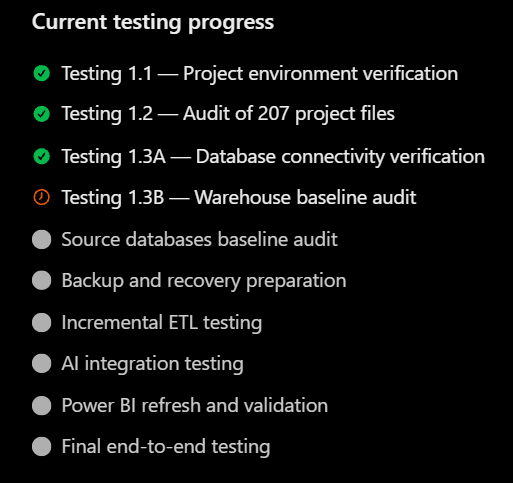

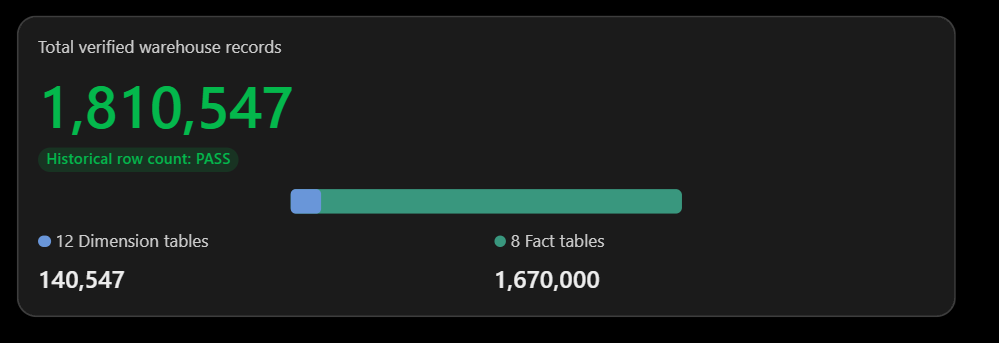

# Testing 1.4 — Source Databases Baseline Audit

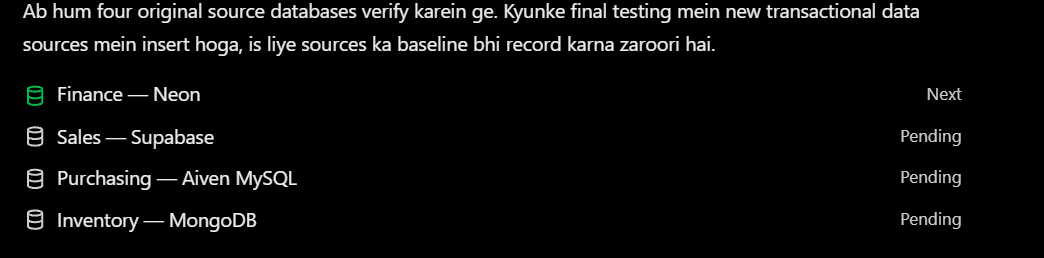

## Testing 1.4A — Finance source baseline

In [ ]:

# ==========================================================
# CT-472 | TESTING 1.4A
# FINANCE SOURCE DATABASE BASELINE AUDIT
# READ ONLY
# ==========================================================

import pandas as pd
from sqlalchemy import text

finance_engine = engines["NEON_DATABASE_URL"]

expected_finance_counts = {
    "accounts": 100,
    "budgets": 10000,
    "cost_centers": 100,
    "exchange_rates": 20000,
    "fiscal_periods": 36,
    "journal_entries": 150000,
    "journal_entry_lines": 300000
}

print("=" * 85)
print("CT-472 - FINANCE SOURCE BASELINE AUDIT")
print("=" * 85)

finance_records = []

with finance_engine.connect() as conn:

    conn.execute(text("""
        SET TRANSACTION ISOLATION LEVEL
        REPEATABLE READ, READ ONLY
    """))

    for table, expected in expected_finance_counts.items():

        actual = conn.execute(text(
            f'SELECT COUNT(*) FROM finance."{table}"'
        )).scalar_one()

        finance_records.append({
            "source_system": "Finance_Neon",
            "table_name": table,
            "expected_records": expected,
            "actual_records": actual,
            "difference": actual - expected,
            "status": "PASS" if actual == expected else "REVIEW"
        })

finance_baseline = pd.DataFrame(finance_records)

display(finance_baseline)

print("\nTotal source tables:", len(finance_baseline))
print("Expected records:",
      f"{finance_baseline['expected_records'].sum():,}")
print("Actual records:",
      f"{finance_baseline['actual_records'].sum():,}")

print("\nFinance baseline:",
      "PASS" if finance_baseline["status"].eq("PASS").all()
      else "REVIEW REQUIRED")

print("\nNo database records or project files modified.")
print("=" * 85)


CT-472 - FINANCE SOURCE BASELINE AUDIT


,source_system,table_name,expected_records,actual_records,difference,status
0,Finance_Neon,accounts,100,100,0,PASS
1,Finance_Neon,budgets,10000,10000,0,PASS
2,Finance_Neon,cost_centers,100,100,0,PASS
3,Finance_Neon,exchange_rates,20000,20000,0,PASS
4,Finance_Neon,fiscal_periods,36,36,0,PASS
5,Finance_Neon,journal_entries,150000,150000,0,PASS
6,Finance_Neon,journal_entry_lines,300000,300000,0,PASS



Total source tables: 7
Expected records: 480,236
Actual records: 480,236

Finance baseline: PASS

No database records or project files modified.


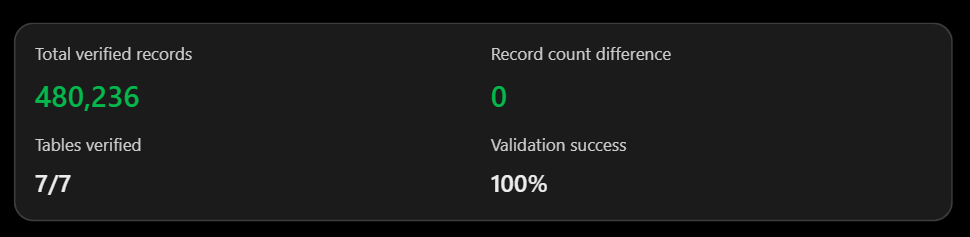

## Testing 1.4B — Sales Source Database Baseline

In [ ]:

# ==========================================================
# CT-472 | TESTING 1.4B
# SALES SOURCE DATABASE BASELINE AUDIT
# READ ONLY
# ==========================================================

from google.colab import userdata
from sqlalchemy import create_engine, text
import pandas as pd

print("=" * 85)
print("CT-472 - SALES SOURCE BASELINE AUDIT")
print("=" * 85)

sales_url = userdata.get("SUPABASE_CONNECTION_STRING")

if sales_url.startswith("postgres://"):
    sales_url = sales_url.replace(
        "postgres://", "postgresql+psycopg://", 1
    )

elif sales_url.startswith("postgresql://"):
    sales_url = sales_url.replace(
        "postgresql://", "postgresql+psycopg://", 1
    )

sales_engine = create_engine(
    sales_url,
    pool_pre_ping=True,
    connect_args={"connect_timeout": 15}
)

expected_sales_counts = {
    "customers": 5000,
    "categories": 20,
    "products": 2000,
    "locations": 100,
    "sales_orders": 100000,
    "sales_order_lines": 300000,
    "payments": 100000
}

sales_records = []

with sales_engine.connect() as conn:

    conn.execute(text("""
        SET TRANSACTION ISOLATION LEVEL
        REPEATABLE READ, READ ONLY
    """))

    print("Supabase connection: PASS")

    for table, expected in expected_sales_counts.items():

        schemas = conn.execute(text("""
            SELECT table_schema
            FROM information_schema.tables
            WHERE table_name = :table
              AND table_type = 'BASE TABLE'
              AND table_schema NOT IN (
                  'pg_catalog', 'information_schema'
              )
        """), {"table": table}).scalars().all()

        if len(schemas) != 1:
            raise RuntimeError(
                f"Schema identification required for {table}: {schemas}"
            )

        schema = schemas[0]

        preparer = sales_engine.dialect.identifier_preparer

        qualified_name = (
            preparer.quote(schema) + "." +
            preparer.quote(table)
        )

        actual = conn.execute(text(
            f"SELECT COUNT(*) FROM {qualified_name}"
        )).scalar_one()

        sales_records.append({
            "source_system": "Sales_Supabase",
            "schema": schema,
            "table_name": table,
            "expected_records": expected,
            "actual_records": actual,
            "difference": actual - expected,
            "status": "PASS" if actual == expected else "REVIEW"
        })

sales_baseline = pd.DataFrame(sales_records)

engines["SUPABASE_CONNECTION_STRING"] = sales_engine

display(sales_baseline)

print("\nTotal source tables:", len(sales_baseline))
print("Expected records:",
      f"{sales_baseline['expected_records'].sum():,}")
print("Actual records:",
      f"{sales_baseline['actual_records'].sum():,}")

print("\nSales baseline:",
      "PASS" if sales_baseline["status"].eq("PASS").all()
      else "REVIEW REQUIRED")

print("\nNo database records or project files modified.")
print("=" * 85)


CT-472 - SALES SOURCE BASELINE AUDIT
Supabase connection: PASS


,source_system,schema,table_name,expected_records,actual_records,difference,status
0,Sales_Supabase,sales,customers,5000,5000,0,PASS
1,Sales_Supabase,sales,categories,20,20,0,PASS
2,Sales_Supabase,sales,products,2000,2000,0,PASS
3,Sales_Supabase,sales,locations,100,100,0,PASS
4,Sales_Supabase,sales,sales_orders,100000,100000,0,PASS
5,Sales_Supabase,sales,sales_order_lines,300000,300000,0,PASS
6,Sales_Supabase,sales,payments,100000,100000,0,PASS



Total source tables: 7
Expected records: 507,120
Actual records: 507,120

Sales baseline: PASS

No database records or project files modified.


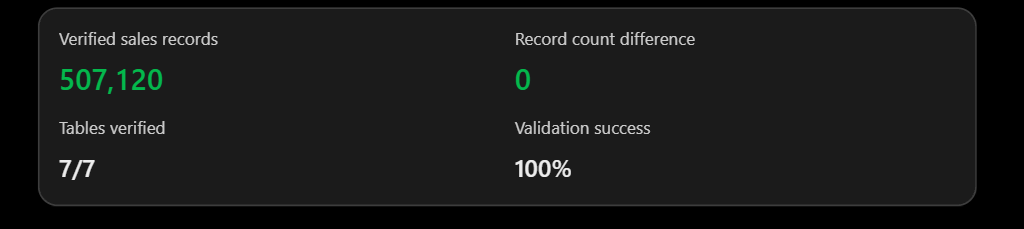

## Testing 1.4C — Purchasing Source Database Baseline

In [ ]:
%pip install -q pymysql

In [ ]:
from google.colab import userdata

password = userdata.get("AIVEN_MYSQL_PASSWORD")

if password:
    print("Aiven secret access: PASS")
else:
    print("Aiven secret access: FAIL")

Aiven secret access: PASS


In [ ]:

# ==========================================================
# CT-472 | AIVEN CONNECTION VERIFICATION
# READ ONLY
# ==========================================================

import socket
from google.colab import userdata
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

host = "mysql-2d888298-cloud-b221.k.aivencloud.com"
port = 28567

print("=" * 75)
print("CT-472 - AIVEN CONNECTION VERIFICATION")
print("=" * 75)

# Step 1: DNS verification
socket.getaddrinfo(host, port)
print("DNS resolution: PASS")

# Step 2: Network verification
with socket.create_connection((host, port), timeout=15):
    print("TCP connectivity: PASS")

# Step 3: Database connection
mysql_url = URL.create(
    drivername="mysql+pymysql",
    username="avnadmin",
    password=userdata.get("AIVEN_MYSQL_PASSWORD"),
    host=host,
    port=port,
    database="defaultdb"
)

mysql_engine = create_engine(
    mysql_url,
    pool_pre_ping=True,
    connect_args={
        "ssl": {"check_hostname": True},
        "connect_timeout": 15
    }
)

with mysql_engine.connect() as conn:
    conn.execute(text("START TRANSACTION READ ONLY"))

    result = conn.execute(text("""
        SELECT DATABASE() AS database_name,
               VERSION() AS mysql_version
    """)).mappings().one()

    print("Aiven MySQL connection: PASS")
    print("Database:", result["database_name"])
    print("MySQL version:", result["mysql_version"])

    conn.rollback()

engines["PURCHASING_AIVEN"] = mysql_engine

print("\nNo database records or project files modified.")
print("=" * 75)


CT-472 - AIVEN CONNECTION VERIFICATION
DNS resolution: PASS
TCP connectivity: PASS
Aiven MySQL connection: PASS
Database: defaultdb
MySQL version: 8.4.11

No database records or project files modified.


In [ ]:

# ==========================================================
# CT-472 | TESTING 1.4C
# PURCHASING SOURCE BASELINE AUDIT
# READ ONLY - NO DATABASE MODIFICATIONS
# ==========================================================

import pandas as pd
from sqlalchemy import text

print("=" * 85)
print("CT-472 - PURCHASING SOURCE BASELINE AUDIT")
print("=" * 85)

expected_purchasing_counts = {
    "categories": 20,
    "products": 2000,
    "locations": 100,
    "suppliers": 2000,
    "purchase_orders": 30000,
    "purchase_order_lines": 120000,
    "goods_receipts": 30000,
    "goods_receipt_lines": 90000
}

purchasing_records = []

with mysql_engine.connect() as conn:

    conn.execute(text("""
        SET TRANSACTION ISOLATION LEVEL REPEATABLE READ
    """))

    conn.execute(text("START TRANSACTION READ ONLY"))

    print("Aiven MySQL connection: PASS")

    for table, expected in expected_purchasing_counts.items():

        actual = conn.execute(text(
            f"SELECT COUNT(*) FROM `defaultdb`.`{table}`"
        )).scalar_one()

        purchasing_records.append({
            "source_system": "Purchasing_Aiven",
            "table_name": table,
            "expected_records": expected,
            "actual_records": actual,
            "difference": actual - expected,
            "status": "PASS" if actual == expected else "REVIEW"
        })

    conn.rollback()

purchasing_baseline = pd.DataFrame(purchasing_records)

display(purchasing_baseline)

print("\nTotal source tables:", len(purchasing_baseline))

print("Expected records:",
      f"{purchasing_baseline['expected_records'].sum():,}")

print("Actual records:",
      f"{purchasing_baseline['actual_records'].sum():,}")

print("\nPurchasing baseline:",
      "PASS" if purchasing_baseline["status"].eq("PASS").all()
      else "REVIEW REQUIRED")

print("\nNo database records or project files modified.")
print("=" * 85)


CT-472 - PURCHASING SOURCE BASELINE AUDIT
Aiven MySQL connection: PASS


,source_system,table_name,expected_records,actual_records,difference,status
0,Purchasing_Aiven,categories,20,20,0,PASS
1,Purchasing_Aiven,products,2000,2000,0,PASS
2,Purchasing_Aiven,locations,100,100,0,PASS
3,Purchasing_Aiven,suppliers,2000,2000,0,PASS
4,Purchasing_Aiven,purchase_orders,30000,30000,0,PASS
5,Purchasing_Aiven,purchase_order_lines,120000,120000,0,PASS
6,Purchasing_Aiven,goods_receipts,30000,30000,0,PASS
7,Purchasing_Aiven,goods_receipt_lines,90000,90000,0,PASS



Total source tables: 8
Expected records: 274,120
Actual records: 274,120

Purchasing baseline: PASS

No database records or project files modified.


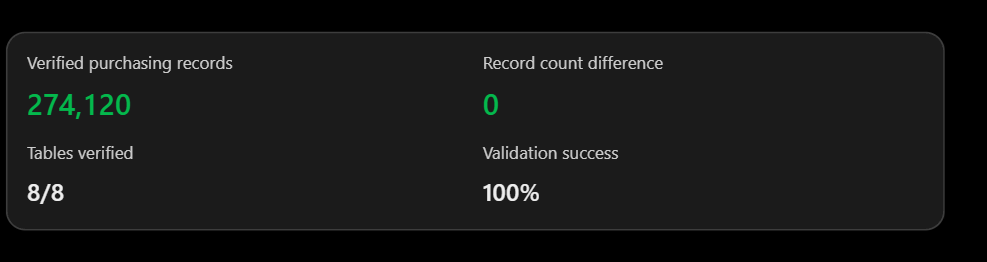

## Testing 1.4D — Inventory Source Database Baselin

In [ ]:
%pip install -q pymongo

In [ ]:

# ==========================================================
# CT-472 | TESTING 1.4D
# INVENTORY SOURCE DATABASE BASELINE AUDIT
# READ ONLY - NO DATABASE MODIFICATIONS
# ==========================================================

from google.colab import userdata
from pymongo import MongoClient
import pandas as pd

print("=" * 85)
print("CT-472 - INVENTORY SOURCE BASELINE AUDIT")
print("=" * 85)

# Step 1: Connect to MongoDB

mongo_client = MongoClient(
    userdata.get("MONGODB_URI"),
    serverSelectionTimeoutMS=15000
)

mongo_client.admin.command("ping")

print("MongoDB connection: PASS")

# Step 2: Historical expected counts

expected_inventory_counts = {
    "products_replica": 2000,
    "locations_replica": 100,
    "warehouses": 100,
    "inventory_movements": 590000,
    "inventory_balances": 200000,
    "stock_counts": 50000
}

# Step 3: Identify existing inventory database

matching_databases = []

for db_name in mongo_client.list_database_names():

    if db_name in ["admin", "local", "config"]:
        continue

    collections = set(
        mongo_client[db_name].list_collection_names()
    )

    if set(expected_inventory_counts).issubset(collections):
        matching_databases.append(db_name)

if len(matching_databases) != 1:
    raise RuntimeError(
        f"Database identification required: {matching_databases}"
    )

inventory_db = mongo_client[matching_databases[0]]

print("Inventory database:", inventory_db.name)

# Step 4: Verify exact document counts

inventory_records = []

for collection, expected in expected_inventory_counts.items():

    actual = inventory_db[collection].count_documents({})

    inventory_records.append({
        "source_system": "Inventory_MongoDB",
        "collection_name": collection,
        "expected_records": expected,
        "actual_records": actual,
        "difference": actual - expected,
        "status": "PASS" if actual == expected else "REVIEW"
    })

inventory_baseline = pd.DataFrame(inventory_records)

display(inventory_baseline)

# Step 5: Final validation

print("\nTotal collections:", len(inventory_baseline))

print("Expected records:",
      f"{inventory_baseline['expected_records'].sum():,}")

print("Actual records:",
      f"{inventory_baseline['actual_records'].sum():,}")

print("\nInventory baseline:",
      "PASS" if inventory_baseline["status"].eq("PASS").all()
      else "REVIEW REQUIRED")

print("\nNo database records or project files modified.")
print("=" * 85)


CT-472 - INVENTORY SOURCE BASELINE AUDIT
MongoDB connection: PASS
Inventory database: inventory


,source_system,collection_name,expected_records,actual_records,difference,status
0,Inventory_MongoDB,products_replica,2000,2000,0,PASS
1,Inventory_MongoDB,locations_replica,100,100,0,PASS
2,Inventory_MongoDB,warehouses,100,100,0,PASS
3,Inventory_MongoDB,inventory_movements,590000,590000,0,PASS
4,Inventory_MongoDB,inventory_balances,200000,200000,0,PASS
5,Inventory_MongoDB,stock_counts,50000,50000,0,PASS



Total collections: 6
Expected records: 842,200
Actual records: 842,200

Inventory baseline: PASS

No database records or project files modified.


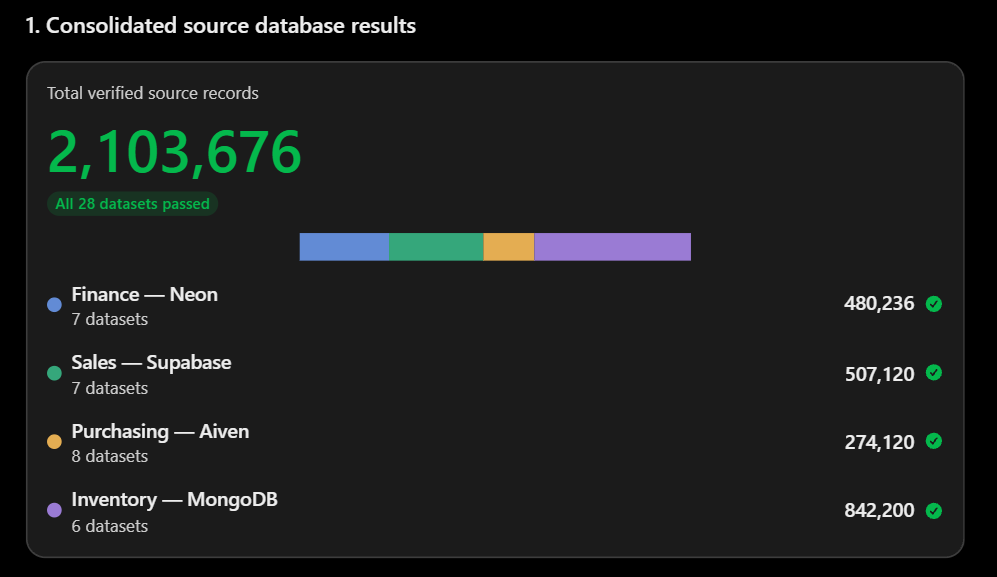

# Testing 1.5 — Permanent Baseline Preservation
Ab tak jitni verification ki hai, uske results Colab variables mein stored hain. Agar Colab session end ho gaya toh ye variables disappear ho jayenge.

Is liye ab hum Google Drive mein ek separate testing folder create karein ge.

In [25]:

# ==========================================================
# CT-472 | TESTING 1.5
# PERMANENT BASELINE PRESERVATION
# NO DATABASE MODIFICATIONS
# ==========================================================

from pathlib import Path
from datetime import datetime, timezone

import pandas as pd
import json

print("=" * 85)
print("CT-472 - PERMANENT BASELINE PRESERVATION")
print("=" * 85)

# ----------------------------------------------------------
# 1. VERIFY REQUIRED BASELINE VARIABLES
# ----------------------------------------------------------

required_variables = [
    "finance_baseline",
    "sales_baseline",
    "purchasing_baseline",
    "inventory_baseline",
    "warehouse_baseline"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(f"Missing baselines: {missing}")

print("Required baseline variables: PASS")

# ----------------------------------------------------------
# 2. CONSOLIDATE SOURCE BASELINES
# ----------------------------------------------------------

source_baseline = pd.concat([
    finance_baseline,
    sales_baseline,
    purchasing_baseline,
    inventory_baseline.rename(
        columns={"collection_name": "table_name"}
    )
], ignore_index=True)

source_baseline = source_baseline[
    [
        "source_system",
        "table_name",
        "expected_records",
        "actual_records",
        "difference",
        "status"
    ]
]

# ----------------------------------------------------------
# 3. VALIDATE BEFORE SAVING
# ----------------------------------------------------------

assert len(source_baseline) == 28
assert source_baseline["actual_records"].sum() == 2103676
assert source_baseline["status"].eq("PASS").all()

dw_baseline = warehouse_baseline[
    (warehouse_baseline["schema"] == "dw") &
    (warehouse_baseline["object_type"] == "BASE TABLE")
]

assert len(dw_baseline) == 20
assert dw_baseline["record_count"].sum() == 1810547

assert len(warehouse_baseline) == 35

print("Consolidated baseline validation: PASS")

# ----------------------------------------------------------
# 4. PREPARE SUMMARY
# ----------------------------------------------------------

baseline_summary = source_baseline.groupby(
    "source_system"
).agg(
    total_datasets=("table_name", "count"),
    expected_records=("expected_records", "sum"),
    actual_records=("actual_records", "sum"),
    difference=("difference", "sum")
).reset_index()

baseline_summary["status"] = baseline_summary[
    "difference"
].apply(lambda x: "PASS" if x == 0 else "REVIEW")

display(baseline_summary)

# ----------------------------------------------------------
# 5. CREATE SEPARATE TESTING FOLDER
# ----------------------------------------------------------

PROJECT_PATH = Path(
    "/content/drive/MyDrive/Enterprise_DW_Project"
)

assert PROJECT_PATH.is_dir(), "Project folder not found"

TESTING_PATH = PROJECT_PATH / "Final_End_to_End_Testing"
BASELINE_PATH = TESTING_PATH / "01_Baseline"

BASELINE_PATH.mkdir(parents=True, exist_ok=True)

# Unique timestamp to protect previous testing evidence

timestamp = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%f_UTC"
)

BASELINE_RUN_PATH = BASELINE_PATH / timestamp

BASELINE_RUN_PATH.mkdir(exist_ok=False)

# ----------------------------------------------------------
# 6. SAVE BASELINE FILES
# ----------------------------------------------------------

source_baseline.to_csv(
    BASELINE_RUN_PATH / "Source_Baseline.csv",
    index=False
)

warehouse_baseline.to_csv(
    BASELINE_RUN_PATH / "Warehouse_Baseline.csv",
    index=False
)

baseline_summary.to_csv(
    BASELINE_RUN_PATH / "Baseline_Summary.csv",
    index=False
)

# ----------------------------------------------------------
# 7. SAVE BASELINE MANIFEST
# ----------------------------------------------------------

manifest = {
    "project": "CT-472 Enterprise Data Warehouse",
    "testing_phase": "1.5",
    "baseline_timestamp_utc": timestamp,
    "original_snapshot": "20261105_200624",
    "source_systems": 4,
    "source_datasets": 28,
    "source_records": 2103676,
    "warehouse_tables": 20,
    "warehouse_records": 1810547,
    "metadata_tables": 10,
    "ai_tables": 3,
    "ai_views": 2,
    "warehouse_secret_name": "DW_",
    "validation_scope": "Connectivity and record counts",
    "validation_status": "PASS"
}

with open(
    BASELINE_RUN_PATH / "Baseline_Manifest.json",
    "w"
) as f:
    json.dump(manifest, f, indent=4)

# ----------------------------------------------------------
# 8. VERIFY SAVED FILES
# ----------------------------------------------------------

print("\nSaved baseline files:")

for file in sorted(BASELINE_RUN_PATH.iterdir()):
    print(f"PASS | {file.name} | {file.stat().st_size:,} bytes")

assert len(list(BASELINE_RUN_PATH.iterdir())) == 4

print("\nBaseline location:")
print(BASELINE_RUN_PATH)

print("\nPermanent baseline preservation: PASS")
print("No database records modified.")
print("Original project files were not overwritten.")
print("=" * 85)


CT-472 - PERMANENT BASELINE PRESERVATION
Required baseline variables: PASS
Consolidated baseline validation: PASS


,source_system,total_datasets,expected_records,actual_records,difference,status
0,Finance_Neon,7,480236,480236,0,PASS
1,Inventory_MongoDB,6,842200,842200,0,PASS
2,Purchasing_Aiven,8,274120,274120,0,PASS
3,Sales_Supabase,7,507120,507120,0,PASS



Saved baseline files:
PASS | Baseline_Manifest.json | 523 bytes
PASS | Baseline_Summary.csv | 234 bytes
PASS | Source_Baseline.csv | 1,397 bytes
PASS | Warehouse_Baseline.csv | 1,262 bytes

Baseline location:
/content/drive/MyDrive/Enterprise_DW_Project/Final_End_to_End_Testing/01_Baseline/20261115_111720_088739_UTC

Permanent baseline preservation: PASS
No database records modified.
Original project files were not overwritten.


## Testing 1.6 — Complete Historical Data Integrity Audit
Is single code mein hum verify karein ge:
- All 20 warehouse tables ki primary key uniqueness.
- All foreign key relationships.
- All 12 dimensions ke unknown members.
- Historical date coverage.
- Sales aur purchasing totals.
- Inventory reconciliation.
- Finance debit-credit reconciliation.
- Metadata aur AI record counts.

In [26]:

# ==========================================================
# CT-472 | TESTING 1.6
# COMPLETE HISTORICAL DATA INTEGRITY AUDIT
# READ ONLY - NO DATABASE MODIFICATIONS
# ==========================================================

import pandas as pd
from sqlalchemy import text, inspect

from datetime import datetime, timezone
from decimal import Decimal

print("=" * 90)
print("CT-472 - COMPLETE HISTORICAL DATA INTEGRITY AUDIT")
print("=" * 90)

warehouse_engine = engines["DW_"]

audit_results = []

def record_check(category, test, expected, actual):

    status = "PASS" if expected == actual else "FAIL"

    audit_results.append({
        "category": category,
        "test": test,
        "expected": str(expected),
        "actual": str(actual),
        "status": status
    })

    print(f"{status} | {test} | Actual: {actual}")


with warehouse_engine.connect() as conn:

    conn.execute(text("""
        SET TRANSACTION ISOLATION LEVEL
        REPEATABLE READ, READ ONLY
    """))

    inspector = inspect(conn)

    def scalar(sql):
        return conn.execute(text(sql)).scalar_one()

    def q(identifier):
        return warehouse_engine.dialect.identifier_preparer.quote(
            identifier
        )

    tables = inspector.get_table_names(schema="dw")

    dimensions = [
        t for t in tables if t.startswith("Dim_")
    ]

    facts = [
        t for t in tables if t.startswith("Fact_")
    ]

    # ------------------------------------------------------
    # 1. STRUCTURAL VALIDATION
    # ------------------------------------------------------

    print("\n1. WAREHOUSE STRUCTURE")

    record_check("Structure", "Warehouse tables", 20, len(tables))
    record_check("Structure", "Dimensions", 12, len(dimensions))
    record_check("Structure", "Facts", 8, len(facts))

    total_columns = sum(
        len(inspector.get_columns(t, schema="dw"))
        for t in tables
    )

    record_check("Structure", "Warehouse columns", 152, total_columns)

    # ------------------------------------------------------
    # 2. PRIMARY KEY INTEGRITY
    # ------------------------------------------------------

    print("\n2. PRIMARY KEY INTEGRITY")

    for table in tables:

        pk = inspector.get_pk_constraint(
            table, schema="dw"
        )["constrained_columns"]

        record_check(
            "Primary Key",
            f"{table}: PK exists",
            True,
            bool(pk)
        )

        if not pk:
            continue

        columns = ", ".join(q(c) for c in pk)

        duplicates = scalar(f"""
            SELECT COUNT(*)
            FROM (
                SELECT {columns}
                FROM dw.{q(table)}
                GROUP BY {columns}
                HAVING COUNT(*) > 1
            ) d
        """)

        record_check(
            "Primary Key",
            f"{table}: duplicate PK groups",
            0,
            duplicates
        )

    # ------------------------------------------------------
    # 3. FOREIGN KEY INTEGRITY
    # ------------------------------------------------------

    print("\n3. FOREIGN KEY INTEGRITY")

    fk_count = 0

    for table in tables:

        foreign_keys = inspector.get_foreign_keys(
            table, schema="dw"
        )

        for fk in foreign_keys:

            fk_count += 1

            parent_table = fk["referred_table"]
            parent_schema = fk["referred_schema"] or "dw"

            child_columns = fk["constrained_columns"]
            parent_columns = fk["referred_columns"]

            join_condition = " AND ".join(
                f"c.{q(c)} = p.{q(p)}"
                for c, p in zip(
                    child_columns, parent_columns
                )
            )

            non_null = " AND ".join(
                f"c.{q(c)} IS NOT NULL"
                for c in child_columns
            )

            orphan_count = scalar(f"""
                SELECT COUNT(*)
                FROM dw.{q(table)} c
                WHERE {non_null}
                  AND NOT EXISTS (
                      SELECT 1
                      FROM {q(parent_schema)}.{q(parent_table)} p
                      WHERE {join_condition}
                  )
            """)

            record_check(
                "Foreign Key",
                f"{table} -> {parent_table} ({', '.join(child_columns)})",
                0,
                orphan_count
            )

    record_check(
        "Foreign Key",
        "Total declared FK relationships",
        34,
        fk_count
    )

    # ------------------------------------------------------
    # 4. UNKNOWN DIMENSION MEMBERS
    # ------------------------------------------------------

    print("\n4. UNKNOWN DIMENSION MEMBERS")

    for table in dimensions:

        pk = inspector.get_pk_constraint(
            table, schema="dw"
        )["constrained_columns"]

        if len(pk) != 1:
            record_check(
                "Unknown Member",
                f"{table}: single-column key",
                True,
                False
            )
            continue

        unknown_count = scalar(f"""
            SELECT COUNT(*)
            FROM dw.{q(table)}
            WHERE {q(pk[0])} = 0
        """)

        record_check(
            "Unknown Member",
            table,
            1,
            unknown_count
        )

    # ------------------------------------------------------
    # 5. HISTORICAL BUSINESS TOTALS
    # ------------------------------------------------------

    print("\n5. BUSINESS TOTALS")

    # Automatically identify measure columns

    def measure_sum(table, candidates):

        columns = {
            c["name"]
            for c in inspector.get_columns(
                table, schema="dw"
            )
        }

        for candidate in candidates:
            if candidate in columns:
                return scalar(f"""
                    SELECT SUM({q(candidate)})
                    FROM dw.{q(table)}
                """)

        print(f"REVIEW | {table} | Available columns: {sorted(columns)}")
        return None

    def money_check(test, expected, actual):

        normalized = (
            Decimal(str(actual)).quantize(Decimal("0.01"))
            if actual is not None else None
        )

        record_check(
            "Business Total",
            test,
            Decimal(expected),
            normalized
        )

    money_check(
        "Historical sales revenue",
        "89849774124.37",
        measure_sum(
            "Fact_Sales",
            ["line_total", "sales_amount",
             "total_amount", "line_amount"]
        )
    )

    record_check(
        "Business Total",
        "Historical sales quantity",
        899727,
        measure_sum(
            "Fact_Sales",
            ["quantity", "quantity_sold"]
        )
    )

    money_check(
        "Historical payments",
        "89849774124.37",
        measure_sum(
            "Fact_Payment",
            ["amount", "payment_amount"]
        )
    )

    money_check(
        "Historical purchasing amount",
        "456477444960.94",
        measure_sum(
            "Fact_Purchase",
            ["line_total", "purchase_amount",
             "total_amount", "line_amount"]
        )
    )

    record_check(
        "Business Total",
        "Historical purchased quantity",
        6296214,
        measure_sum(
            "Fact_Purchase",
            ["quantity", "quantity_ordered",
             "ordered_quantity"]
        )
    )

    # ------------------------------------------------------
    # 6. INVENTORY RECONCILIATION
    # ------------------------------------------------------

    print("\n6. INVENTORY RECONCILIATION")

    movement = measure_sum(
        "Fact_Inventory_Movement",
        ["quantity_change"]
    )

    balance = measure_sum(
        "Fact_Inventory_Balance",
        ["quantity_on_hand", "quantity",
         "on_hand_quantity", "stock_quantity"]
    )

    record_check(
        "Inventory", "Net inventory movements",
        63755183, movement
    )

    record_check(
        "Inventory", "Inventory balance",
        63755183, balance
    )

    record_check(
        "Inventory", "Movement vs balance reconciliation",
        True,
        movement is not None and
        balance is not None and movement == balance
    )

    # ------------------------------------------------------
    # 7. FINANCE RECONCILIATION
    # ------------------------------------------------------

    print("\n7. FINANCE RECONCILIATION")

    debit = measure_sum(
        "Fact_Journal_Entry_Line",
        ["debit", "debit_amount"]
    )

    credit = measure_sum(
        "Fact_Journal_Entry_Line",
        ["credit", "credit_amount"]
    )

    money_check("Historical debit", "37512632145.45", debit)
    money_check("Historical credit", "37512632145.45", credit)

    record_check(
        "Finance", "Debit equals credit",
        True,
        debit is not None and
        credit is not None and debit == credit
    )

    # ------------------------------------------------------
    # 8. DATE COVERAGE
    # ------------------------------------------------------

    print("\n8. DATE COVERAGE")

    date_columns = inspector.get_columns(
        "Dim_Date", schema="dw"
    )

    date_fields = [
        c["name"] for c in date_columns
        if str(c["type"]).upper() == "DATE"
    ]

    if len(date_fields) == 1:

        date_col = q(date_fields[0])

        date_data = conn.execute(text(f"""
            SELECT MIN({date_col}),
                   MAX({date_col}),
                   COUNT(DISTINCT {date_col})
            FROM dw."Dim_Date"
            WHERE date_key <> 0
        """)).one()

        record_check(
            "Date", "Earliest historical date",
            "2023-11-01", str(date_data[0])
        )

        record_check(
            "Date", "Latest historical date",
            "2026-10-31", str(date_data[1])
        )

        record_check(
            "Date", "Unique historical dates",
            1096, date_data[2]
        )

    else:
        record_check(
            "Date", "Date field identification",
            1, len(date_fields)
        )

    # ------------------------------------------------------
    # 9. METADATA AND AI
    # ------------------------------------------------------

    print("\n9. METADATA AND AI VALIDATION")

    expected_objects = {
        "meta.source_systems": 4,
        "meta.source_datasets": 28,
        "meta.source_columns": 140,
        "meta.warehouse_datasets": 20,
        "meta.warehouse_columns": 152,
        "meta.table_mappings": 8,
        "meta.lineage_edges": 9,
        "meta.transformation_rules": 6,
        "meta.etl_batches": 1,
        "meta.validation_results": 6,
        "ai.model_registry": 3,
        "ai.sales_anomalies": 36,
        "ai.sales_forecasts": 3,
        "ai.vw_sales_anomalies_powerbi": 36,
        "ai.vw_sales_forecasts_powerbi": 3
    }

    for obj, expected in expected_objects.items():

        record_check(
            "Metadata / AI",
            obj,
            expected,
            scalar(f"SELECT COUNT(*) FROM {obj}")
        )

# ----------------------------------------------------------
# 10. FINAL RESULTS AND EVIDENCE
# ----------------------------------------------------------

integrity_audit = pd.DataFrame(audit_results)

print("\n" + "=" * 90)
print("FINAL VALIDATION SUMMARY")
print("=" * 90)

display(pd.crosstab(
    integrity_audit["category"],
    integrity_audit["status"]
))

failed = integrity_audit[
    integrity_audit["status"] != "PASS"
]

print("Total checks:", len(integrity_audit))
print("Passed:", integrity_audit["status"].eq("PASS").sum())
print("Failed:", len(failed))

if not failed.empty:
    print("\nCHECKS REQUIRING INVESTIGATION")
    display(failed)

audit_path = TESTING_PATH / "02_Integrity_Audit"
audit_path.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%f_UTC"
)

output_file = audit_path / f"Integrity_Audit_{timestamp}.csv"

integrity_audit.to_csv(output_file, index=False)

print("\nEvidence saved:", output_file)

print("\nFINAL STATUS:",
      "PASS" if failed.empty else "REVIEW REQUIRED")

print("No database records modified.")
print("=" * 90)


CT-472 - COMPLETE HISTORICAL DATA INTEGRITY AUDIT

1. WAREHOUSE STRUCTURE
PASS | Warehouse tables | Actual: 20
PASS | Dimensions | Actual: 12
PASS | Facts | Actual: 8
PASS | Warehouse columns | Actual: 152

2. PRIMARY KEY INTEGRITY
PASS | Dim_SalesOrder: PK exists | Actual: True
PASS | Dim_SalesOrder: duplicate PK groups | Actual: 0
PASS | Dim_Customer: PK exists | Actual: True
PASS | Dim_Customer: duplicate PK groups | Actual: 0
PASS | Dim_Product: PK exists | Actual: True
PASS | Dim_Product: duplicate PK groups | Actual: 0
PASS | Dim_Location: PK exists | Actual: True
PASS | Dim_Location: duplicate PK groups | Actual: 0
PASS | Dim_Date: PK exists | Actual: True
PASS | Dim_Date: duplicate PK groups | Actual: 0
PASS | Dim_PurchaseOrder: PK exists | Actual: True
PASS | Dim_PurchaseOrder: duplicate PK groups | Actual: 0
PASS | Dim_Supplier: PK exists | Actual: True
PASS | Dim_Supplier: duplicate PK groups | Actual: 0
PASS | Dim_Warehouse: PK exists | Actual: True
PASS | Dim_Warehouse: du

status,FAIL,PASS
category,,
Business Total,0,7
Date,1,0
Finance,0,1
Foreign Key,0,35
Inventory,0,3
Metadata / AI,0,15
Primary Key,0,40
Structure,0,4
Unknown Member,0,12


Total checks: 118
Passed: 117
Failed: 1

CHECKS REQUIRING INVESTIGATION


,category,test,expected,actual,status
102,Date,Date field identification,1,0,FAIL



Evidence saved: /content/drive/MyDrive/Enterprise_DW_Project/Final_End_to_End_Testing/02_Integrity_Audit/Integrity_Audit_20261115_111915_017814_UTC.csv

FINAL STATUS: REVIEW REQUIRED
No database records modified.


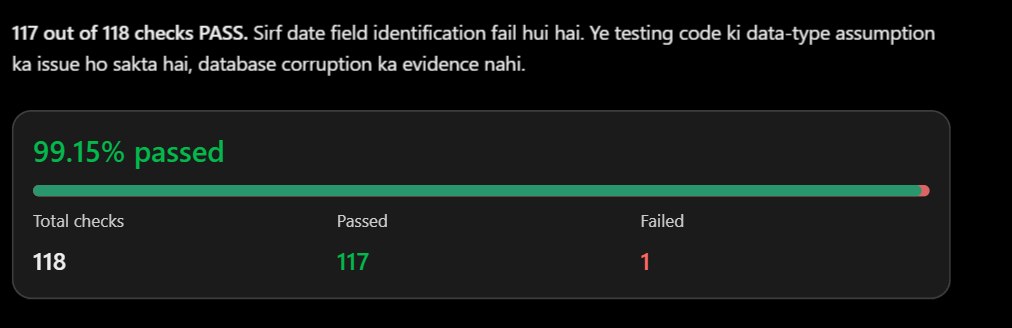

## Testing 1.7 — Date Correction + Backup Preparation
Dono steps ek cell mein karte hain. Date dimension verify karein ge aur existing database structures ka backup evidence save karein ge.

In [27]:

from sqlalchemy import text, inspect
from datetime import datetime, timezone
import pandas as pd
import json

print("=" * 85)
print("CT-472 - DATE VALIDATION AND BACKUP PREPARATION")
print("=" * 85)

# 1. Correct date validation

with warehouse_engine.connect() as conn:

    conn.execute(text("SET TRANSACTION READ ONLY"))

    dates = pd.read_sql(text("""
        SELECT *
        FROM dw."Dim_Date"
        WHERE date_key <> 0
        ORDER BY date_key
    """), conn)

    print("Date dimension columns:", dates.columns.tolist())

    actual_dates = pd.to_datetime(
        dates["date_key"].astype(str),
        format="%Y%m%d",
        errors="coerce"
    )

    expected_dates = pd.date_range(
        "2023-11-01", "2026-10-31"
    )

    date_checks = {
        "Valid date keys": bool(actual_dates.notna().all()),
        "Total real dates": len(dates) == 1096,
        "Unique dates": actual_dates.nunique() == 1096,
        "Complete date coverage": (
            set(actual_dates) == set(expected_dates)
        )
    }

    for check, passed in date_checks.items():
        print(f"{check}: {'PASS' if passed else 'FAIL'}")

    print("Earliest date:", actual_dates.min())
    print("Latest date:", actual_dates.max())

    if not all(date_checks.values()):
        raise RuntimeError("Date validation requires investigation")

# 2. Prepare separate backup folder

timestamp = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%f_UTC"
)

BACKUP_PATH = (
    TESTING_PATH / "03_Backup" / timestamp
)

BACKUP_PATH.mkdir(parents=True, exist_ok=False)

# 3. Capture relational database structures

database_configs = [
    ("Warehouse", warehouse_engine, ["dw", "meta", "ai"]),
    ("Finance", finance_engine, ["finance"]),
    ("Sales", sales_engine, ["sales"]),
    ("Purchasing", mysql_engine, ["defaultdb"])
]

schema_records = []

for system, engine, schemas in database_configs:

    inspector = inspect(engine)

    for schema in schemas:

        for table in inspector.get_table_names(schema=schema):

            schema_records.append({
                "system": system,
                "schema": schema,
                "table": table,
                "columns": inspector.get_columns(
                    table, schema=schema
                ),
                "primary_key": inspector.get_pk_constraint(
                    table, schema=schema
                ),
                "foreign_keys": inspector.get_foreign_keys(
                    table, schema=schema
                ),
                "unique_constraints": inspector.get_unique_constraints(
                    table, schema=schema
                ),
                "indexes": inspector.get_indexes(
                    table, schema=schema
                )
            })

    print(f"{system} structure captured: PASS")

# 4. Capture MongoDB collection structure

mongo_records = []

for name in expected_inventory_counts:

    collection = inventory_db[name]
    sample = collection.find_one() or {}

    mongo_records.append({
        "collection": name,
        "sample_field_types": {
            key: type(value).__name__
            for key, value in sample.items()
        },
        "indexes": collection.index_information()
    })

print("MongoDB structure captured: PASS")

# 5. Save evidence

for filename, data in [
    ("Relational_Schema_Backup.json", schema_records),
    ("MongoDB_Schema_Backup.json", mongo_records),
    ("Date_Validation.json", date_checks)
]:
    with open(BACKUP_PATH / filename, "w") as f:
        json.dump(data, f, indent=4, default=str)

source_baseline.to_csv(
    BACKUP_PATH / "Source_Baseline.csv", index=False
)

warehouse_baseline.to_csv(
    BACKUP_PATH / "Warehouse_Baseline.csv", index=False
)

print("\nSaved evidence:")

for file in sorted(BACKUP_PATH.iterdir()):
    print(f"PASS | {file.name}")

print("\nBackup preparation path:", BACKUP_PATH)
print("Date key validation: PASS")
print("Backup preparation: PASS")
print("No database records modified.")
print("=" * 85)


CT-472 - DATE VALIDATION AND BACKUP PREPARATION
Date dimension columns: ['date_key', 'full_date', 'day', 'day_name', 'month', 'month_name', 'quarter', 'year']
Valid date keys: PASS
Total real dates: PASS
Unique dates: PASS
Complete date coverage: PASS
Earliest date: 2023-11-01 00:00:00
Latest date: 2026-10-31 00:00:00
Warehouse structure captured: PASS
Finance structure captured: PASS
Sales structure captured: PASS
Purchasing structure captured: PASS
MongoDB structure captured: PASS

Saved evidence:
PASS | Date_Validation.json
PASS | MongoDB_Schema_Backup.json
PASS | Relational_Schema_Backup.json
PASS | Source_Baseline.csv
PASS | Warehouse_Baseline.csv

Backup preparation path: /content/drive/MyDrive/Enterprise_DW_Project/Final_End_to_End_Testing/03_Backup/20261115_112054_663946_UTC
Date key validation: PASS
Backup preparation: PASS
No database records modified.


Date field identification kya thi?
Dim_Date ki full_date field identify nahi ho rahi thi, kyunke previous code specifically SQL DATE data type search kar raha tha.

date_key ki complete coverage ab verify ho gayi hai:
- Earliest date: 1 November 2023
- Latest date: 31 October 2026
- Unique dates: 1,096
Ye konsa backup hai?
Ye structural backup hai. Ismein database tables ki structure, columns, primary keys, foreign keys, indexes aur record counts save hain. Actual records ka recoverable backup abhi nahi banaya.

## Testing 1.8 — Actual Data Backup
Ab new data insert karne se pehle existing records ka backup save karte hain. Iske baad incremental ETL aur new data insertion ki taraf move karein ge.

In [28]:

# ==========================================================
# CT-472 | TESTING 1.8
# PRE-INSERTION DATA BACKUP
# ==========================================================

import gzip
import pickle
import json
import hashlib
import pandas as pd

from bson import BSON
from sqlalchemy import text
from datetime import datetime, timezone

print("=" * 85)
print("CT-472 - PRE-INSERTION DATA BACKUP")
print("=" * 85)

# 1. Complete actual date attribute validation

with warehouse_engine.connect() as conn:

    conn.execute(text("SET TRANSACTION READ ONLY"))

    date_df = pd.read_sql(text("""
        SELECT date_key, full_date
        FROM dw."Dim_Date"
        WHERE date_key <> 0
    """), conn)

    key_dates = pd.to_datetime(
        date_df["date_key"].astype(str),
        format="%Y%m%d",
        errors="coerce"
    )

    full_dates = pd.to_datetime(
        date_df["full_date"],
        errors="coerce"
    )

    assert full_dates.notna().all()
    assert key_dates.eq(full_dates).all()

print("Actual full_date validation: PASS")

# 2. Create separate backup location

timestamp = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%f_UTC"
)

DATA_BACKUP_PATH = (
    TESTING_PATH / "04_Data_Backup" / timestamp
)

DATA_BACKUP_PATH.mkdir(parents=True, exist_ok=False)

backup_results = []

def checksum(path):
    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1048576), b""):
            digest.update(block)

    return digest.hexdigest()

# 3. Relational data backup

configs = [
    ("Warehouse", warehouse_engine, "dw"),
    ("Warehouse", warehouse_engine, "meta"),
    ("Warehouse", warehouse_engine, "ai"),
    ("Finance_Neon", finance_engine, "finance"),
    ("Sales_Supabase", sales_engine, "sales"),
    ("Purchasing_Aiven", mysql_engine, "defaultdb")
]

from sqlalchemy import inspect

for system, engine, schema in configs:

    folder = DATA_BACKUP_PATH / system / schema
    folder.mkdir(parents=True, exist_ok=True)

    tables = inspect(engine).get_table_names(schema=schema)

    quote = engine.dialect.identifier_preparer.quote

    with engine.connect() as conn:

        if engine.dialect.name == "mysql":
            conn.execute(text(
                "SET TRANSACTION ISOLATION LEVEL REPEATABLE READ"
            ))
            conn.execute(text("START TRANSACTION READ ONLY"))
        else:
            conn.execute(text("""
                SET TRANSACTION ISOLATION LEVEL
                REPEATABLE READ, READ ONLY
            """))

        for table in tables:

            qualified = f"{quote(schema)}.{quote(table)}"

            expected = conn.execute(text(
                f"SELECT COUNT(*) FROM {qualified}"
            )).scalar_one()

            path = folder / f"{table}.pkl.gz"

            saved = 0

            with gzip.open(path, "wb") as f:

                result = conn.execution_options(
                    stream_results=True
                ).execute(text(
                    f"SELECT * FROM {qualified}"
                ))

                pickle.dump(list(result.keys()), f)

                while True:

                    rows = result.fetchmany(10000)

                    if not rows:
                        break

                    pickle.dump(
                        [tuple(row) for row in rows],
                        f,
                        protocol=pickle.HIGHEST_PROTOCOL
                    )

                    saved += len(rows)

                result.close()

            assert saved == expected, table

            backup_results.append({
                "system": system,
                "schema": schema,
                "dataset": table,
                "records": saved,
                "file": str(path.relative_to(DATA_BACKUP_PATH)),
                "bytes": path.stat().st_size,
                "sha256": checksum(path),
                "status": "PASS"
            })

            print(f"PASS | {system}.{table} | {saved:,}")

        conn.rollback()

# 4. MongoDB document backup

folder = DATA_BACKUP_PATH / "Inventory_MongoDB"
folder.mkdir(exist_ok=True)

for name, expected in expected_inventory_counts.items():

    path = folder / f"{name}.bson.gz"

    saved = 0

    with gzip.open(path, "wb") as f:

        for document in inventory_db[name].find({}).batch_size(5000):

            f.write(BSON.encode(document))
            saved += 1

    assert saved == expected, name

    backup_results.append({
        "system": "Inventory_MongoDB",
        "schema": inventory_db.name,
        "dataset": name,
        "records": saved,
        "file": str(path.relative_to(DATA_BACKUP_PATH)),
        "bytes": path.stat().st_size,
        "sha256": checksum(path),
        "status": "PASS"
    })

    print(f"PASS | MongoDB.{name} | {saved:,}")

# 5. Save manifest and validate totals

backup_manifest = pd.DataFrame(backup_results)

backup_manifest.to_csv(
    DATA_BACKUP_PATH / "Backup_Manifest.csv",
    index=False
)

display(
    backup_manifest.groupby("system").agg(
        datasets=("dataset", "count"),
        records=("records", "sum")
    )
)

assert len(backup_manifest) == 61
assert backup_manifest["records"].sum() == 3914639

print("\nTotal datasets:", len(backup_manifest))
print("Total backed-up records:",
      f"{backup_manifest['records'].sum():,}")

print("Backup location:", DATA_BACKUP_PATH)
print("DATA EXPORT BACKUP: PASS")
print("No database records modified.")
print("=" * 85)


CT-472 - PRE-INSERTION DATA BACKUP
Actual full_date validation: PASS
PASS | Warehouse.Dim_SalesOrder | 100,001
PASS | Warehouse.Dim_Customer | 5,001
PASS | Warehouse.Dim_Product | 2,001
PASS | Warehouse.Dim_Location | 101
PASS | Warehouse.Dim_Date | 1,097
PASS | Warehouse.Dim_PurchaseOrder | 30,001
PASS | Warehouse.Dim_Supplier | 2,001
PASS | Warehouse.Dim_Warehouse | 101
PASS | Warehouse.Dim_Movement_Type | 4
PASS | Warehouse.Dim_Cost_Center | 101
PASS | Warehouse.Fact_Sales | 300,000
PASS | Warehouse.Fact_Payment | 100,000
PASS | Warehouse.Fact_Purchase | 120,000
PASS | Warehouse.Fact_Inventory_Movement | 590,000
PASS | Warehouse.Fact_Inventory_Balance | 200,000
PASS | Warehouse.Fact_Stock_Count | 50,000
PASS | Warehouse.Dim_Account | 101
PASS | Warehouse.Fact_Journal_Entry_Line | 300,000
PASS | Warehouse.Dim_Fiscal_Period | 37
PASS | Warehouse.Fact_Budget | 10,000
PASS | Warehouse.source_systems | 4
PASS | Warehouse.source_datasets | 28
PASS | Warehouse.source_columns | 140
PASS | W

,datasets,records
system,,
Finance_Neon,7,480236
Inventory_MongoDB,6,842200
Purchasing_Aiven,8,274120
Sales_Supabase,7,507120
Warehouse,33,1810963



Total datasets: 61
Total backed-up records: 3,914,639
Backup location: /content/drive/MyDrive/Enterprise_DW_Project/Final_End_to_End_Testing/04_Data_Backup/20261115_112526_130138_UTC
DATA EXPORT BACKUP: PASS
No database records modified.


## Testing 2.1 — Incremental ETL Preparation

Source schemas, primary keys, maximum IDs, foreign keys aur MongoDB document structure identify ho gaye hain.

Is step mein humne existing databases ki structure ko understand kiya, taake jab new data insert karein toh koi error na aaye.

In [29]:

# ==========================================================
# CT-472 | TESTING 2.1
# INCREMENTAL ETL PREPARATION
# REUSE EXISTING SCHEMA EVIDENCE
# ==========================================================

import json
import pandas as pd
from sqlalchemy import text

print("=" * 85)
print("CT-472 - INCREMENTAL ETL PREPARATION")
print("=" * 85)

# Reuse previously saved schema information

with open(BACKUP_PATH / "Relational_Schema_Backup.json") as f:
    schemas = json.load(f)

source_engines = {
    "Sales": sales_engine,
    "Purchasing": mysql_engine,
    "Finance": finance_engine
}

incremental_profile = []

for item in schemas:

    system = item["system"]

    if system not in source_engines:
        continue

    engine = source_engines[system]
    schema = item["schema"]
    table = item["table"]

    quote = engine.dialect.identifier_preparer.quote

    qualified = f"{quote(schema)}.{quote(table)}"

    pk = item["primary_key"]["constrained_columns"]

    print(f"\n{system} | {table}")
    print("Columns:")

    for col in item["columns"]:
        print(
            f"  {col['name']} | {col['type']} "
            f"| nullable={col.get('nullable')}"
        )

    print("Primary key:", pk)

    profile = {
        "system": system,
        "table": table,
        "primary_key": pk,
        "columns": item["columns"],
        "foreign_keys": item["foreign_keys"],
        "maximum_pk": None
    }

    with engine.connect() as conn:

        for key in pk:

            if len(pk) == 1:

                maximum = conn.execute(text(
                    f"SELECT MAX({quote(key)}) "
                    f"FROM {qualified}"
                )).scalar()

                profile["maximum_pk"] = maximum

                print("Maximum primary key:", maximum)

    incremental_profile.append(profile)

    print("Foreign keys:")

    for fk in item["foreign_keys"]:
        print(
            fk["constrained_columns"],
            "->",
            fk["referred_table"],
            fk["referred_columns"]
        )

# MongoDB field information from previous backup

print("\n" + "=" * 85)
print("MONGODB INVENTORY STRUCTURE")
print("=" * 85)

with open(BACKUP_PATH / "MongoDB_Schema_Backup.json") as f:
    mongo_schema = json.load(f)

for item in mongo_schema:

    print("\nCollection:", item["collection"])
    print("Fields:", item["sample_field_types"])

# Existing ETL batch structure

print("\n" + "=" * 85)
print("EXISTING ETL BATCH")
print("=" * 85)

with warehouse_engine.connect() as conn:

    conn.execute(text("SET TRANSACTION READ ONLY"))

    display(pd.read_sql(
        text("SELECT * FROM meta.etl_batches"),
        conn
    ))

print("\nINCREMENTAL PROFILE PREPARATION: COMPLETE")
print("No database records modified.")
print("=" * 85)


CT-472 - INCREMENTAL ETL PREPARATION

Finance | fiscal_periods
Columns:
  period_id | INTEGER | nullable=False
  fiscal_year | INTEGER | nullable=False
  period_number | INTEGER | nullable=False
  start_date | DATE | nullable=False
  end_date | DATE | nullable=False
Primary key: ['period_id']
Maximum primary key: 36
Foreign keys:

Finance | journal_entries
Columns:
  journal_entry_id | INTEGER | nullable=False
  entry_date | DATE | nullable=False
  description | TEXT | nullable=True
  period_id | INTEGER | nullable=True
  entry_status | VARCHAR(50) | nullable=True
Primary key: ['journal_entry_id']
Maximum primary key: 150000
Foreign keys:
['period_id'] -> fiscal_periods ['period_id']

Finance | journal_entry_lines
Columns:
  line_id | INTEGER | nullable=False
  journal_entry_id | INTEGER | nullable=False
  account_id | INTEGER | nullable=False
  cost_center_id | INTEGER | nullable=True
  debit | NUMERIC(14, 2) | nullable=True
  credit | NUMERIC(14, 2) | nullable=True
Primary key: ['lin

,batch_id,snapshot_folder,source_table_count,source_row_count,warehouse_fact_rows,batch_status,notes,recorded_at
0,20261105_200624,/content/drive/MyDrive/Enterprise_DW_Project/r...,28,2103676,1670000,SNAPSHOT_VERIFIED_AND_WAREHOUSE_VALIDATED,Original source snapshots and warehouse loadin...,2026-11-07 12:39:42.072551+00:00



INCREMENTAL PROFILE PREPARATION: COMPLETE
No database records modified.


## Testing 2.2 — Controlled New Transaction Batch

In [30]:

# ==========================================================
# CT-472 | TESTING 2.2
# CONTROLLED TRANSACTION BATCH PREPARATION
# READ ONLY
# ==========================================================

import pandas as pd
from sqlalchemy import text
from datetime import datetime

print("=" * 85)
print("CT-472 - CONTROLLED TRANSACTION BATCH PREPARATION")
print("=" * 85)

def read_sql(engine, query):

    with engine.connect() as conn:
        return pd.read_sql(text(query), conn)

TEST_DATE = datetime(2026, 11, 15)
TEST_BATCH_ID = "E2E_TEST_20261115_001"

# 1. Select existing warehouse

test_warehouse = inventory_db.warehouses.find_one(
    {"warehouse_id": 1},
    {"_id": 0}
)

assert test_warehouse is not None

warehouse_id = test_warehouse["warehouse_id"]
location_id = test_warehouse["location_id"]

print("\nWAREHOUSE")
print(test_warehouse)

# 2. Select products with sufficient available stock

stock_candidates = pd.DataFrame(list(
    inventory_db.inventory_balances.find(
        {
            "warehouse_id": warehouse_id,
            "quantity_on_hand": {"$gte": 50}
        },
        {"_id": 0}
    ).sort("product_id", 1).limit(20)
))

assert not stock_candidates.empty

sales_products = read_sql(
    sales_engine,
    """
    SELECT product_id, product_name, unit_price
    FROM sales.products
    """
)

purchase_products = read_sql(
    mysql_engine,
    """
    SELECT product_id, unit_price AS purchasing_price
    FROM defaultdb.products
    """
)

test_products = (
    stock_candidates
    .merge(sales_products, on="product_id")
    .merge(purchase_products, on="product_id")
    .sort_values("product_id")
    .head(3)
)

assert len(test_products) == 3
assert test_products["product_id"].is_unique

print("\nSELECTED PRODUCTS")
display(test_products)

# 3. Existing customer

test_customer = read_sql(
    sales_engine,
    """
    SELECT customer_id
    FROM sales.customers
    ORDER BY customer_id
    LIMIT 1
    """
)

print("\nCUSTOMER")
display(test_customer)

# 4. Existing supplier

test_supplier = read_sql(
    mysql_engine,
    """
    SELECT supplier_id, supplier_name
    FROM defaultdb.suppliers
    ORDER BY supplier_id
    LIMIT 1
    """
)

print("\nSUPPLIER")
display(test_supplier)

# 5. Finance accounts and cost centers

test_accounts = read_sql(
    finance_engine,
    """
    SELECT account_id, account_code,
           account_name, account_type
    FROM finance.accounts
    ORDER BY account_id
    """
)

print("\nAVAILABLE FINANCE ACCOUNTS")
display(test_accounts)

test_cost_center = read_sql(
    finance_engine,
    """
    SELECT cost_center_id, cost_center_name
    FROM finance.cost_centers
    ORDER BY cost_center_id
    LIMIT 1
    """
)

print("\nCOST CENTER")
display(test_cost_center)

# 6. Existing transaction status values

status_queries = [
    (
        "Sales order statuses", sales_engine,
        "SELECT DISTINCT order_status FROM sales.sales_orders"
    ),
    (
        "Payment methods", sales_engine,
        "SELECT DISTINCT payment_method FROM sales.payments"
    ),
    (
        "Payment statuses", sales_engine,
        "SELECT DISTINCT payment_status FROM sales.payments"
    ),
    (
        "Purchase order statuses", mysql_engine,
        "SELECT DISTINCT order_status FROM defaultdb.purchase_orders"
    ),
    (
        "Receipt statuses", mysql_engine,
        "SELECT DISTINCT receipt_status FROM defaultdb.goods_receipts"
    ),
    (
        "Journal statuses", finance_engine,
        "SELECT DISTINCT entry_status FROM finance.journal_entries"
    )
]

for label, engine, query in status_queries:
    print("\n" + label)
    display(read_sql(engine, query))

# 7. MongoDB maximum business IDs

mongo_max_ids = {}

for collection, field in [
    ("inventory_movements", "movement_id"),
    ("stock_counts", "count_id")
]:

    latest = inventory_db[collection].find_one(
        {},
        {"_id": 0, field: 1},
        sort=[(field, -1)]
    )

    mongo_max_ids[field] = latest[field]

print("\nMONGODB MAXIMUM IDs")
print(mongo_max_ids)

# 8. Check fiscal period availability

print("\nLATEST FISCAL PERIODS")

display(read_sql(
    finance_engine,
    """
    SELECT *
    FROM finance.fiscal_periods
    ORDER BY period_id DESC
    LIMIT 3
    """
))

print("\nTEST BATCH:", TEST_BATCH_ID)
print("TEST DATE:", TEST_DATE)

print("\nTRANSACTION PREPARATION: COMPLETE")
print("No new files created.")
print("No database records modified.")
print("=" * 85)


CT-472 - CONTROLLED TRANSACTION BATCH PREPARATION

WAREHOUSE
{'warehouse_id': 1, 'warehouse_name': 'Warehouse 001', 'location_id': 1, 'warehouse_capacity': 19100, 'warehouse_status': 'Active'}

SELECTED PRODUCTS


,product_id,warehouse_id,quantity_on_hand,last_updated,product_name,unit_price,purchasing_price
0,1,1,214,2026-10-31,Refrigerator Model 0001,148439.32,148439.32
1,2,1,152,2026-10-31,Blender Model 0002,28337.82,28337.82
2,3,1,219,2026-10-31,Microwave Model 0003,148263.22,148263.22



CUSTOMER


,customer_id
0,1



SUPPLIER


,supplier_id,supplier_name
0,1,"Brown, Valencia and Crawford 1"


... (15 outputs left out)

,entry_status
0,Posted



MONGODB MAXIMUM IDs
{'movement_id': 590000, 'count_id': 50000}

LATEST FISCAL PERIODS


,period_id,fiscal_year,period_number,start_date,end_date
0,36,2026,10,2026-10-01,2026-10-31
1,35,2026,9,2026-09-01,2026-09-30
2,34,2026,8,2026-08-01,2026-08-31



TEST BATCH: E2E_TEST_20261115_001
TEST DATE: 2026-11-15 00:00:00

TRANSACTION PREPARATION: COMPLETE
No new files created.
No database records modified.


## Testing 2.3 — Generate New Transaction Data

In [31]:

# ==========================================================
# CT-472 | TESTING 2.3
# GENERATE CONTROLLED INCREMENTAL TRANSACTIONS
# ==========================================================

from decimal import Decimal
from datetime import datetime, date
import pandas as pd

print("=" * 85)
print("CT-472 - NEW TRANSACTION GENERATION")
print("=" * 85)

D = lambda x: Decimal(str(x)).quantize(Decimal("0.01"))

customer_id = int(test_customer.iloc[0]["customer_id"])
supplier_id = int(test_supplier.iloc[0]["supplier_id"])
cost_center_id = int(test_cost_center.iloc[0]["cost_center_id"])

warehouse_id = int(warehouse_id)
location_id = int(location_id)

# Reuse maximum IDs from Testing 2.1

def next_id(system, table):
    item = next(
        x for x in incremental_profile
        if x["system"] == system and x["table"] == table
    )
    return int(item["maximum_pk"]) + 1

order_id = next_id("Sales", "sales_orders")
line_id = next_id("Sales", "sales_order_lines")
payment_id = next_id("Sales", "payments")

po_id = next_id("Purchasing", "purchase_orders")
po_line_id = next_id("Purchasing", "purchase_order_lines")
receipt_id = next_id("Purchasing", "goods_receipts")
receipt_line_id = next_id("Purchasing", "goods_receipt_lines")

movement_id = int(mongo_max_ids["movement_id"]) + 1
count_id = int(mongo_max_ids["count_id"]) + 1

purchase_time = TEST_DATE.replace(hour=9)
sale_time = TEST_DATE.replace(hour=12)
count_time = TEST_DATE.replace(hour=15)

purchase_quantities = [20, 30, 25]
sale_quantities = [5, 10, 8]

new_sales = {
    "sales_orders": [{
        "order_id": order_id,
        "customer_id": customer_id,
        "location_id": location_id,
        "order_date": sale_time,
        "order_status": "Completed"
    }],
    "sales_order_lines": [],
    "payments": []
}

new_purchasing = {
    "purchase_orders": [{
        "purchase_order_id": po_id,
        "supplier_id": supplier_id,
        "location_id": location_id,
        "order_date": purchase_time.date(),
        "order_status": "Received"
    }],
    "purchase_order_lines": [],
    "goods_receipts": [{
        "receipt_id": receipt_id,
        "purchase_order_id": po_id,
        "receipt_date": purchase_time.date(),
        "receipt_status": "Received"
    }],
    "goods_receipt_lines": []
}

new_inventory = {
    "inventory_movements": [],
    "stock_counts": []
}

expected_balances = []

for i, (_, product) in enumerate(test_products.iterrows()):

    pid = int(product["product_id"])
    price = D(product["unit_price"])
    cost = D(product["purchasing_price"])

    pq = purchase_quantities[i]
    sq = sale_quantities[i]

    old_stock = int(product["quantity_on_hand"])
    closing_stock = old_stock + pq - sq

    assert closing_stock >= 0

    new_sales["sales_order_lines"].append({
        "order_line_id": line_id + i,
        "order_id": order_id,
        "product_id": pid,
        "quantity": sq,
        "unit_price": price,
        "line_total": price * sq
    })

    new_purchasing["purchase_order_lines"].append({
        "purchase_line_id": po_line_id + i,
        "purchase_order_id": po_id,
        "product_id": pid,
        "quantity": pq,
        "unit_cost": cost,
        "line_total": cost * pq
    })

    new_purchasing["goods_receipt_lines"].append({
        "receipt_line_id": receipt_line_id + i,
        "receipt_id": receipt_id,
        "product_id": pid,
        "quantity_received": pq
    })

    common = {
        "product_id": pid,
        "warehouse_id": warehouse_id,
        "location_id": location_id
    }

    new_inventory["inventory_movements"].extend([
        {
            **common,
            "movement_id": movement_id + 2*i,
            "movement_date": purchase_time,
            "movement_type": "PURCHASE_IN",
            "quantity_change": pq,
            "source_type": "PURCHASING",
            "source_id": receipt_id,
            "source_line_id": receipt_line_id + i
        },
        {
            **common,
            "movement_id": movement_id + 2*i + 1,
            "movement_date": sale_time,
            "movement_type": "SALE_OUT",
            "quantity_change": -sq,
            "source_type": "SALES",
            "source_id": order_id,
            "source_line_id": line_id + i
        }
    ])

    new_inventory["stock_counts"].append({
        "count_id": count_id + i,
        "product_id": pid,
        "warehouse_id": warehouse_id,
        "counted_quantity": closing_stock,
        "count_date": count_time
    })

    expected_balances.append({
        "product_id": pid,
        "warehouse_id": warehouse_id,
        "old_stock": old_stock,
        "purchased": pq,
        "sold": sq,
        "expected_stock": closing_stock
    })

sales_total = sum(
    r["line_total"]
    for r in new_sales["sales_order_lines"]
)

purchase_total = sum(
    r["line_total"]
    for r in new_purchasing["purchase_order_lines"]
)

new_sales["payments"].append({
    "payment_id": payment_id,
    "order_id": order_id,
    "payment_date": sale_time,
    "payment_method": "Bank Transfer",
    "payment_amount": sales_total,
    "payment_status": "Completed"
})

# Finance account classification investigation

print("\nFINANCE ACCOUNT CANDIDATES")

account_candidates = test_accounts[
    test_accounts["account_name"].str.contains(
        "Bank|Cash|Inventory|Payable|Sales Revenue|Cost of Goods",
        case=False,
        regex=True,
        na=False
    )
]

display(account_candidates)

# Inventory index verification

print("\nINVENTORY BALANCE INDEXES")
print(inventory_db.inventory_balances.index_information())

# Display generated records

for system, datasets in [
    ("SALES", new_sales),
    ("PURCHASING", new_purchasing),
    ("INVENTORY", new_inventory)
]:
    for table, records in datasets.items():
        print(f"\n{system} | {table}")
        display(pd.DataFrame(records))

print("\nEXPECTED INVENTORY BALANCES")
display(pd.DataFrame(expected_balances))

print("\nEXPECTED BUSINESS TOTALS")
print("Sales revenue:", sales_total)
print("Payment amount:", sales_total)
print("Purchasing amount:", purchase_total)
print("Purchased units:", sum(purchase_quantities))
print("Sold units:", sum(sale_quantities))
print("Net stock increase:",
      sum(purchase_quantities) - sum(sale_quantities))

print("\nTRANSACTION GENERATION: PASS")
print("No files created.")
print("No database records modified.")
print("=" * 85)


CT-472 - NEW TRANSACTION GENERATION

FINANCE ACCOUNT CANDIDATES


,account_id,account_code,account_name,account_type
0,1,ACC001,Cash 1,Equity
1,2,ACC002,Bank 1,Asset
3,4,ACC004,Inventory 1,Liability
4,5,ACC005,Accounts Payable 1,Asset
5,6,ACC006,Sales Revenue 1,Revenue
20,21,ACC021,Cash 2,Asset
21,22,ACC022,Bank 2,Equity
23,24,ACC024,Inventory 2,Revenue
24,25,ACC025,Accounts Payable 2,Revenue
25,26,ACC026,Sales Revenue 2,Expense



INVENTORY BALANCE INDEXES
{'_id_': {'v': 2, 'key': [('_id', 1)]}}

SALES | sales_orders


,order_id,customer_id,location_id,order_date,order_status
0,100001,1,1,2026-11-15 12:00:00,Completed



SALES | sales_order_lines


,order_line_id,order_id,product_id,quantity,unit_price,line_total
0,300001,100001,1,5,148439.32,742196.60
1,300002,100001,2,10,28337.82,283378.20
2,300003,100001,3,8,148263.22,1186105.76


... (13 outputs left out)

,count_id,product_id,warehouse_id,counted_quantity,count_date
0,50001,1,1,229,2026-11-15 15:00:00
1,50002,2,1,172,2026-11-15 15:00:00
2,50003,3,1,236,2026-11-15 15:00:00



EXPECTED INVENTORY BALANCES


,product_id,warehouse_id,old_stock,purchased,sold,expected_stock
0,1,1,214,20,5,229
1,2,1,152,30,10,172
2,3,1,219,25,8,236



EXPECTED BUSINESS TOTALS
Sales revenue: 2211680.56
Payment amount: 2211680.56
Purchasing amount: 7525501.50
Purchased units: 75
Sold units: 23
Net stock increase: 52

TRANSACTION GENERATION: PASS
No files created.
No database records modified.


## Testing 2.4 — Finalize Finance and Inventory Records

In [32]:
# ==========================================================
# CT-472 | TESTING 2.4
# FINALIZE FINANCE AND INVENTORY TRANSACTIONS
# ==========================================================

from decimal import Decimal
from datetime import date
import pandas as pd

# 1. Select verified finance accounts

bank_account_id = 2
revenue_account_id = 6
payable_account_id = 85

inventory_account_id = next_id("Finance", "accounts")
period_id = next_id("Finance", "fiscal_periods")
journal_id = next_id("Finance", "journal_entries")
journal_line_id = next_id("Finance", "journal_entry_lines")
budget_id = next_id("Finance", "budgets")

zero = Decimal("0.00")

# 2. Prepare new finance records

new_finance = {
    "accounts": [{
        "account_id": inventory_account_id,
        "account_code": f"ACC{inventory_account_id:03d}",
        "account_name": "Inventory Asset",
        "account_type": "Asset"
    }],

    "fiscal_periods": [{
        "period_id": period_id,
        "fiscal_year": 2026,
        "period_number": 11,
        "start_date": date(2026, 11, 1),
        "end_date": date(2026, 11, 30)
    }],

    "journal_entries": [],
    "journal_entry_lines": [],

    "budgets": [{
        "budget_id": budget_id,
        "account_id": revenue_account_id,
        "cost_center_id": cost_center_id,
        "period_id": period_id,
        "budget_amount": Decimal("2500000.00")
    }]
}

# Helper: balanced journal entry

def add_journal(description, debit_account,
                credit_account, amount):

    jid = journal_id + len(
        new_finance["journal_entries"]
    )

    new_finance["journal_entries"].append({
        "journal_entry_id": jid,
        "entry_date": TEST_DATE.date(),
        "description": f"{TEST_BATCH_ID} | {description}",
        "period_id": period_id,
        "entry_status": "Posted"
    })

    for account, debit, credit in [
        (debit_account, amount, zero),
        (credit_account, zero, amount)
    ]:

        lid = journal_line_id + len(
            new_finance["journal_entry_lines"]
        )

        new_finance["journal_entry_lines"].append({
            "line_id": lid,
            "journal_entry_id": jid,
            "account_id": account,
            "cost_center_id": cost_center_id,
            "debit": debit,
            "credit": credit
        })

# Purchase on credit
add_journal(
    "Inventory purchased on credit",
    inventory_account_id,
    payable_account_id,
    purchase_total
)

# Sales received through bank
add_journal(
    "Sales payment received",
    bank_account_id,
    revenue_account_id,
    sales_total
)

# Cost of goods sold account
cogs_candidates = test_accounts[
    test_accounts["account_name"].str.contains(
        r"Cost of Goods|COGS|Cost of Sales",
        case=False, regex=True, na=False
    )
    & test_accounts["account_type"].eq("Expense")
]

if not cogs_candidates.empty:
    cogs_account_id = int(
        cogs_candidates.iloc[0]["account_id"]
    )
else:
    cogs_account_id = inventory_account_id + 1

    new_finance["accounts"].append({
        "account_id": cogs_account_id,
        "account_code": f"ACC{cogs_account_id:03d}",
        "account_name": "Cost of Goods Sold",
        "account_type": "Expense"
    })

# Test assumption: sales cost equals purchasing unit cost
cogs_total = sum(
    D(product["purchasing_price"]) * sale_quantities[i]
    for i, (_, product) in enumerate(test_products.iterrows())
)

add_journal(
    "Cost of goods sold",
    cogs_account_id,
    inventory_account_id,
    cogs_total
)

# 3. New dated inventory balance records

new_inventory["inventory_balances"] = [
    {
        "product_id": int(r["product_id"]),
        "warehouse_id": int(r["warehouse_id"]),
        "quantity_on_hand": int(r["expected_stock"]),
        "last_updated": count_time
    }
    for r in expected_balances
]

# 4. Finance validations

journal_df = pd.DataFrame(
    new_finance["journal_entry_lines"]
)

journal_check = (
    journal_df.groupby("journal_entry_id")
    [["debit", "credit"]].sum()
)

assert (journal_check["debit"] ==
        journal_check["credit"]).all()

print("JOURNAL BALANCING: PASS")
display(journal_check)

# 5. Inventory validations

assert sum(
    r["quantity_change"]
    for r in new_inventory["inventory_movements"]
) == 52

assert sum(
    r["quantity_on_hand"]
    for r in new_inventory["inventory_balances"]
) == 637

print("INVENTORY VALIDATION: PASS")

# 6. Display new finance records

for table, records in new_finance.items():
    print("\nFINANCE |", table)
    display(pd.DataFrame(records))

print("\nNEW INVENTORY BALANCES")
display(pd.DataFrame(
    new_inventory["inventory_balances"]
))

# 7. Consolidated incremental batch

test_batch = {
    "Sales": new_sales,
    "Purchasing": new_purchasing,
    "Inventory": new_inventory,
    "Finance": new_finance
}

summary = []

for system, datasets in test_batch.items():
    for dataset, records in datasets.items():
        summary.append({
            "source_system": system,
            "dataset": dataset,
            "new_records": len(records)
        })

batch_summary = pd.DataFrame(summary)

print("\nCOMPLETE INCREMENTAL BATCH")
display(batch_summary)

print("Total new records:",
      batch_summary["new_records"].sum())

print("Total debit:", journal_df["debit"].sum())
print("Total credit:", journal_df["credit"].sum())

print("\nTESTING 2.4: DATA PREPARATION COMPLETE")
print("No database records modified.")
print("No additional files created.")

JOURNAL BALANCING: PASS


,debit,credit
journal_entry_id,,
150001,7525501.50,7525501.50
150002,2211680.56,2211680.56
150003,2211680.56,2211680.56


INVENTORY VALIDATION: PASS

FINANCE | accounts


,account_id,account_code,account_name,account_type
0,101,ACC101,Inventory Asset,Asset
1,102,ACC102,Cost of Goods Sold,Expense



FINANCE | fiscal_periods


,period_id,fiscal_year,period_number,start_date,end_date
0,37,2026,11,2026-11-01,2026-11-30


... (7 outputs left out)

,product_id,warehouse_id,quantity_on_hand,last_updated
0,1,1,229,2026-11-15 15:00:00
1,2,1,172,2026-11-15 15:00:00
2,3,1,236,2026-11-15 15:00:00



COMPLETE INCREMENTAL BATCH


,source_system,dataset,new_records
0,Sales,sales_orders,1
1,Sales,sales_order_lines,3
2,Sales,payments,1
3,Purchasing,purchase_orders,1
4,Purchasing,purchase_order_lines,3
5,Purchasing,goods_receipts,1
6,Purchasing,goods_receipt_lines,3
7,Inventory,inventory_movements,6
8,Inventory,stock_counts,3
9,Inventory,inventory_balances,3


Total new records: 38
Total debit: 11948862.62
Total credit: 11948862.62

TESTING 2.4: DATA PREPARATION COMPLETE
No database records modified.
No additional files created.


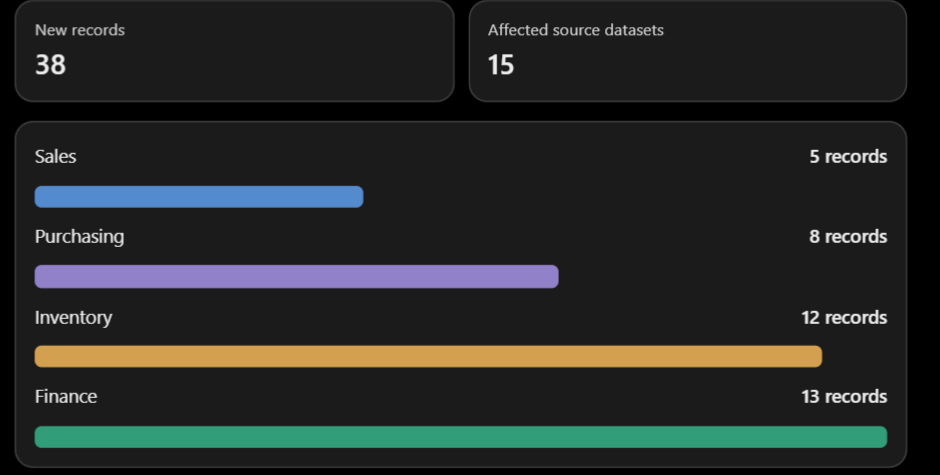

# Testing 2.5 — Insert new records into source databases

Code pehle ID collisions check karega, ek small batch manifest save karega aur phir actual insertion karega. Is testing ke dauran koi aur developer source databases mein writes na kare.

In [33]:
# ==========================================================
# CT-472 | TESTING 2.5
# CONTROLLED SOURCE DATABASE INSERTION
# ==========================================================

from sqlalchemy import MetaData, Table, select, insert
from pathlib import Path
from bson import ObjectId
import hashlib
import pickle
import pandas as pd

assert sum(
    len(rows)
    for datasets in test_batch.values()
    for rows in datasets.values()
) == 38

sql_config = {
    "Sales": (sales_engine, "sales"),
    "Purchasing": (mysql_engine, "defaultdb"),
    "Finance": (finance_engine, "finance")
}

mongo_keys = {
    "inventory_movements": ["movement_id"],
    "stock_counts": ["count_id"],
    "inventory_balances": [
        "product_id", "warehouse_id", "last_updated"
    ]
}

# 1. Save ONLY the 38 new records for recovery

batch_path = TESTING_PATH / "05_Incremental_Batches" / TEST_BATCH_ID
batch_path.mkdir(parents=True, exist_ok=True)

manifest_file = batch_path / "Prepared_Test_Batch.pkl"

if manifest_file.exists():
    with manifest_file.open("rb") as f:
        assert pickle.load(f) == test_batch, "Batch mismatch"
else:
    with manifest_file.open("xb") as f:
        pickle.dump(test_batch, f)

# 2. Prepare SQL table mappings

sql_tables = {}

for system, (engine, schema) in sql_config.items():
    for name in test_batch[system]:
        sql_tables[(system, name)] = Table(
            name,
            MetaData(),
            schema=schema,
            autoload_with=engine
        )

# 3. SQL collision detection

def sql_record_exists(conn, table, row):

    pk = [c.name for c in table.primary_key.columns]
    assert pk, f"No primary key: {table.name}"

    query = select(table).where(
        *[table.c[k] == row[k] for k in pk]
    )

    existing = conn.execute(query).mappings().one_or_none()

    if existing is None:
        return False

    assert all(
        existing[k] == v for k, v in row.items()
    ), f"Conflicting existing record: {table.name}"

    return True

# 4. MongoDB collision detection

def mongo_record_exists(name, row):

    query = {k: row[k] for k in mongo_keys[name]}

    matches = list(
        inventory_db[name].find(query, {"_id": 0}).limit(2)
    )

    assert len(matches) <= 1, f"Duplicate business key: {name}"

    if not matches:
        return False

    assert matches[0] == row, f"Conflicting Mongo record: {name}"

    return True

# 5. Preflight checks before any database writes

print("RUNNING PREFLIGHT CHECKS")

for system, (engine, schema) in sql_config.items():
    with engine.connect() as conn:
        for name, rows in test_batch[system].items():
            table = sql_tables[(system, name)]

            for row in rows:
                sql_record_exists(conn, table, row)

for name, rows in test_batch["Inventory"].items():
    for row in rows:
        mongo_record_exists(name, row)

print("PREFLIGHT: PASS")

approval = input(
    "Type INSERT38 to insert the prepared test batch: "
)

assert approval == "INSERT38", "Insertion cancelled"

# 6. Insert relational records
# One transaction per relational database

results = []

for system, (engine, schema) in sql_config.items():

    system_results = []

    with engine.begin() as conn:

        for name, rows in test_batch[system].items():

            table = sql_tables[(system, name)]

            inserted = 0
            skipped = 0

            for row in rows:

                if sql_record_exists(conn, table, row):
                    skipped += 1
                    continue

                conn.execute(insert(table).values(**row))
                inserted += 1

            system_results.append({
                "system": system,
                "dataset": name,
                "inserted": inserted,
                "already_exists": skipped
            })

    results.extend(system_results)
    print(system, "COMMITTED")

# 7. Insert MongoDB records

for name, rows in test_batch["Inventory"].items():

    inserted = 0
    skipped = 0

    for row in rows:

        if mongo_record_exists(name, row):
            skipped += 1
            continue

        # Deterministic MongoDB document ID
        key = repr([
            TEST_BATCH_ID,
            name,
            *[row[k] for k in mongo_keys[name]]
        ])

        doc_id = ObjectId(
            hashlib.sha256(key.encode()).hexdigest()[:24]
        )

        inventory_db[name].insert_one({
            "_id": doc_id,
            **row
        })

        inserted += 1

    results.append({
        "system": "Inventory",
        "dataset": name,
        "inserted": inserted,
        "already_exists": skipped
    })

# 8. Verify all 38 records in source databases

verified = 0

for system, (engine, schema) in sql_config.items():
    with engine.connect() as conn:
        for name, rows in test_batch[system].items():
            for row in rows:
                assert sql_record_exists(
                    conn, sql_tables[(system, name)], row
                )
                verified += 1

for name, rows in test_batch["Inventory"].items():
    for row in rows:
        assert mongo_record_exists(name, row)
        verified += 1

assert verified == 38

result_df = pd.DataFrame(results)
display(result_df)

print("New records inserted:", result_df["inserted"].sum())
print("Already existing:", result_df["already_exists"].sum())
print("Verified records:", verified)

print("\nTESTING 2.5: PASS")
print("No historical records updated or deleted.")
print("No new database tables created.")
print("Warehouse unchanged.")

RUNNING PREFLIGHT CHECKS
PREFLIGHT: PASS
Type INSERT38 to insert the prepared test batch: INSERT38
Sales COMMITTED
Purchasing COMMITTED
Finance COMMITTED


,system,dataset,inserted,already_exists
0,Sales,sales_orders,1,0
1,Sales,sales_order_lines,3,0
2,Sales,payments,1,0
3,Purchasing,purchase_orders,1,0
4,Purchasing,purchase_order_lines,3,0
5,Purchasing,goods_receipts,1,0
6,Purchasing,goods_receipt_lines,3,0
7,Finance,accounts,2,0
8,Finance,fiscal_periods,1,0
9,Finance,journal_entries,3,0


New records inserted: 38
Already existing: 0
Verified records: 38

TESTING 2.5: PASS
No historical records updated or deleted.
No new database tables created.
Warehouse unchanged.


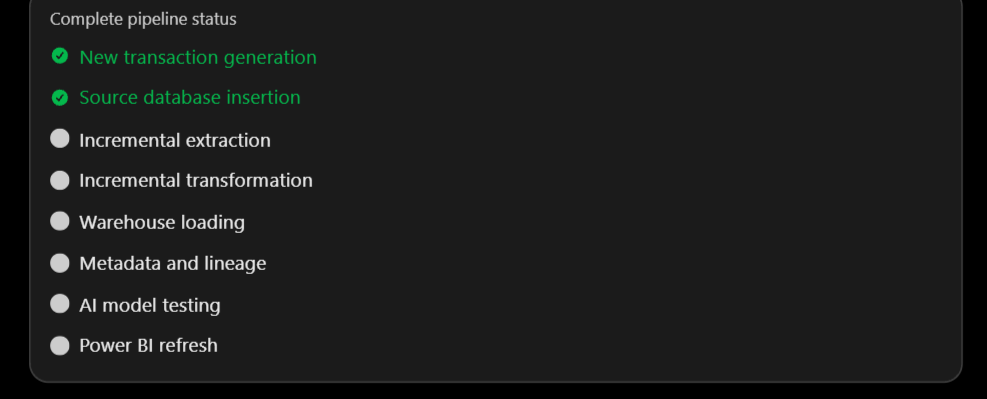

## Testing 2.6 — Incremental Data Extraction

In [34]:
# ==========================================================
# CT-472 | TESTING 2.6
# INCREMENTAL EXTRACTION - NEW RECORDS ONLY
# ==========================================================

import pandas as pd
import hashlib
from sqlalchemy import select

DELTA_PATH = batch_path / "Incremental_Parquet"
DELTA_PATH.mkdir(parents=True, exist_ok=True)

delta_data = {}
extraction_results = []

for system, datasets in test_batch.items():

    delta_data[system] = {}

    system_path = DELTA_PATH / system
    system_path.mkdir(exist_ok=True)

    for name, expected_rows in datasets.items():

        extracted_rows = []

        # Extract from actual source database

        if system == "Inventory":

            for row in expected_rows:

                query = {
                    k: row[k]
                    for k in mongo_keys[name]
                }

                matches = list(
                    inventory_db[name].find(
                        query, {"_id": 0}
                    ).limit(2)
                )

                assert len(matches) == 1
                assert matches[0] == row

                extracted_rows.append(matches[0])

        else:

            engine, schema = sql_config[system]
            table = sql_tables[(system, name)]

            pk = [
                c.name
                for c in table.primary_key.columns
            ]

            with engine.connect() as conn:

                for row in expected_rows:

                    query = select(table).where(
                        *[
                            table.c[k] == row[k]
                            for k in pk
                        ]
                    )

                    actual = dict(
                        conn.execute(query)
                        .mappings().one()
                    )

                    assert all(
                        actual[k] == v
                        for k, v in row.items()
                    )

                    extracted_rows.append(actual)

        df = pd.DataFrame(extracted_rows)

        assert len(df) == len(expected_rows)

        # Save only incremental records

        file_path = system_path / f"{name}.parquet"

        if file_path.exists():

            existing = pd.read_parquet(file_path)

            pd.testing.assert_frame_equal(
                existing,
                df,
                check_dtype=False
            )

        else:
            df.to_parquet(file_path, index=False)

        # Validate saved Parquet file

        saved_df = pd.read_parquet(file_path)

        pd.testing.assert_frame_equal(
            saved_df,
            df,
            check_dtype=False
        )

        delta_data[system][name] = saved_df

        extraction_results.append({
            "source_system": system,
            "dataset": name,
            "expected_records": len(expected_rows),
            "extracted_records": len(saved_df),
            "file_bytes": file_path.stat().st_size,
            "sha256": hashlib.sha256(
                file_path.read_bytes()
            ).hexdigest(),
            "status": "PASS"
        })

        print(f"PASS | {system} | {name} | {len(df)}")

# Final extraction validation

extraction_summary = pd.DataFrame(
    extraction_results
)

assert len(extraction_summary) == 15

assert extraction_summary[
    "extracted_records"
].sum() == 38

extraction_summary.to_csv(
    DELTA_PATH / "Extraction_Manifest.csv",
    index=False
)

print("\n" + "=" * 85)
display(extraction_summary)

print("Datasets extracted: 15")
print("New records extracted: 38")
print("Parquet files: 15")
print("Storage used (bytes):",
      extraction_summary["file_bytes"].sum())

print("Saved at:", DELTA_PATH)

print("\nTESTING 2.6: PASS")
print("Historical snapshots untouched.")
print("No database records modified.")
print("No historical data reloaded.")

PASS | Sales | sales_orders | 1
PASS | Sales | sales_order_lines | 3
PASS | Sales | payments | 1
PASS | Purchasing | purchase_orders | 1
PASS | Purchasing | purchase_order_lines | 3
PASS | Purchasing | goods_receipts | 1
PASS | Purchasing | goods_receipt_lines | 3
PASS | Inventory | inventory_movements | 6
PASS | Inventory | stock_counts | 3
PASS | Inventory | inventory_balances | 3
PASS | Finance | accounts | 2
PASS | Finance | fiscal_periods | 1
PASS | Finance | journal_entries | 3
PASS | Finance | journal_entry_lines | 6
PASS | Finance | budgets | 1



,source_system,dataset,expected_records,extracted_records,file_bytes,sha256,status
0,Sales,sales_orders,1,1,3589,84fede519bedf2f3c91fd0077f1548afc63ec20a184b8c...,PASS
1,Sales,sales_order_lines,3,3,4266,f185f87d5d5d645b0b60cd4f1064766393f1a0050eb934...,PASS
2,Sales,payments,1,1,4282,b5452e357b04871aa7d9fd9a185a83d1e1d5d7d24de3e9...,PASS
3,Purchasing,purchase_orders,1,1,3581,60d40ec2eb8ab7dac02f1dc5e0df2da9c525eb4387d72b...,PASS
4,Purchasing,purchase_order_lines,3,3,4362,71a85e0c9ccbf324e1fc5bb2aa03502c584b6ec54b36ca...,PASS
5,Purchasing,goods_receipts,1,1,3019,74de588f7a43d22c2e5b1a334b7c6ce0a590b2c61e2f49...,PASS
6,Purchasing,goods_receipt_lines,3,3,3114,c7629b8baad30e82e57c4bd978b0c90574aa7765c23991...,PASS
7,Inventory,inventory_movements,6,6,6712,e3fa2937fa56a2dadfff8b700fc2a789951f53d72acac7...,PASS
8,Inventory,stock_counts,3,3,3688,25b82927ab3b7c6fe3709e52a1f8cb768d6caa8dcf6b74...,PASS
9,Inventory,inventory_balances,3,3,3119,0f28e2f74eeb82c6798680b0274a09b0c593a26e3f1d29...,PASS


Datasets extracted: 15
New records extracted: 38
Parquet files: 15
Storage used (bytes): 57946
Saved at: /content/drive/MyDrive/Enterprise_DW_Project/Final_End_to_End_Testing/05_Incremental_Batches/E2E_TEST_20261115_001/Incremental_Parquet

TESTING 2.6: PASS
Historical snapshots untouched.
No database records modified.
No historical data reloaded.


## Testing 2.7 — Incremental Transformation
Ab hum new source data ko warehouse ke star schema ke according prepare karein ge.

### Testing 2.7A — Warehouse Mapping Preparation
Hum existing warehouse structure backup reuse karein ge. Dobara schema backup ya full data extraction nahi karein ge.

In [35]:
# ==========================================================
# CT-472 | TESTING 2.7A
# INCREMENTAL WAREHOUSE MAPPING PREPARATION
# ==========================================================

import json
import pandas as pd
from sqlalchemy import MetaData, Table, select, func

print("=" * 85)
print("INCREMENTAL WAREHOUSE MAPPING")
print("=" * 85)

# 1. Reuse existing schema backup

with open(BACKUP_PATH / "Relational_Schema_Backup.json") as f:
    saved_schema = json.load(f)

dw_schema = [
    x for x in saved_schema
    if x["schema"] == "dw"
]

assert len(dw_schema) == 20

# 2. Identify affected dimensions and facts

affected_dimensions = [
    "Dim_Date",
    "Dim_Account",
    "Dim_Fiscal_Period",
    "Dim_SalesOrder",
    "Dim_PurchaseOrder"
]

affected_facts = [
    x["table"] for x in dw_schema
    if x["table"].startswith("Fact_")
]

mapping_profile = {}

with warehouse_engine.connect() as conn:

    for item in dw_schema:

        name = item["table"]

        table = Table(
            name,
            MetaData(),
            schema="dw",
            autoload_with=conn
        )

        pk = list(table.primary_key.columns)

        assert len(pk) == 1

        maximum_key = conn.execute(
            select(func.max(pk[0]))
        ).scalar()

        mapping_profile[name] = {
            "columns": [c.name for c in table.columns],
            "primary_key": pk[0].name,
            "maximum_key": maximum_key,
            "foreign_keys": [
                {
                    "column": fk.parent.name,
                    "target_table": fk.column.table.name,
                    "target_column": fk.column.name
                }
                for fk in table.foreign_keys
            ]
        }

        print("\nTABLE:", name)
        print("Columns:", mapping_profile[name]["columns"])
        print("Primary key:", pk[0].name)
        print("Maximum key:", maximum_key)

        if mapping_profile[name]["foreign_keys"]:
            print("Foreign keys:",
                  mapping_profile[name]["foreign_keys"])

    # 3. Resolve only required existing dimension members

    lookup_specs = {
        "Dim_Product": ("product_id", [1, 2, 3]),
        "Dim_Location": ("location_id", [location_id]),
        "Dim_Customer": ("customer_id", [customer_id]),
        "Dim_Supplier": ("supplier_id", [supplier_id]),
        "Dim_Warehouse": ("warehouse_id", [warehouse_id]),
        "Dim_Cost_Center": (
            "cost_center_id", [cost_center_id]
        ),
        "Dim_Account": (
            "account_id",
            sorted(
                {
                    r["account_id"]
                    for r in new_finance["journal_entry_lines"]
                }
                - {
                    r["account_id"]
                    for r in new_finance["accounts"]
                }
            )
        )
    }

    dimension_lookups = {}

    for name, (business_key, ids) in lookup_specs.items():

        table = Table(
            name,
            MetaData(),
            schema="dw",
            autoload_with=conn
        )

        pk = list(table.primary_key.columns)[0]

        rows = conn.execute(
            select(table.c[business_key], pk)
            .where(table.c[business_key].in_(ids))
        ).all()

        assert len(rows) == len(ids), name

        lookup = {
            int(business_id): int(surrogate_key)
            for business_id, surrogate_key in rows
        }

        assert set(lookup) == set(ids)

        dimension_lookups[name] = lookup

        print("\nLOOKUP:", name)
        print(lookup)

    # 4. Movement type mappings

    movement_table = Table(
        "Dim_Movement_Type",
        MetaData(),
        schema="dw",
        autoload_with=conn
    )

    movement_members = pd.read_sql(
        select(movement_table), conn
    )

    print("\nMOVEMENT TYPE MEMBERS")
    display(movement_members)

    # 5. Inspect date dimension coverage

    date_table = Table(
        "Dim_Date",
        MetaData(),
        schema="dw",
        autoload_with=conn
    )

    latest_dw_date = conn.execute(
        select(func.max(date_table.c.full_date))
    ).scalar()

    print("\nLATEST WAREHOUSE DATE:", latest_dw_date)

print("\nAFFECTED DIMENSIONS:", affected_dimensions)
print("AFFECTED FACTS:", affected_facts)

print("\nTESTING 2.7A: PASS")
print("No database records modified.")
print("No historical data reloaded.")
print("No additional backup created.")

INCREMENTAL WAREHOUSE MAPPING

TABLE: Dim_SalesOrder
Columns: ['sales_order_key', 'order_id', 'order_status']
Primary key: sales_order_key
Maximum key: 100000

TABLE: Dim_Customer
Columns: ['customer_key', 'customer_id', 'customer_name', 'email', 'phone', 'city', 'country', 'created_at']
Primary key: customer_key
Maximum key: 5000

TABLE: Dim_Product
Columns: ['product_key', 'product_id', 'product_name', 'category_id', 'unit_price', 'category_name']
Primary key: product_key
Maximum key: 2000

TABLE: Dim_Location
Columns: ['location_key', 'location_id', 'location_name', 'city', 'country']
Primary key: location_key
Maximum key: 100

TABLE: Dim_Date
Columns: ['date_key', 'full_date', 'day', 'day_name', 'month', 'month_name', 'quarter', 'year']
Primary key: date_key
Maximum key: 20261031

TABLE: Dim_PurchaseOrder
Columns: ['purchase_order_key', 'purchase_order_id', 'supplier_id', 'location_id', 'order_date', 'purchase_order_status', 'receipt_id', 'receipt_date', 'receipt_status']
Primary k

,movement_type_key,movement_type,source_type
0,0,None,None
1,1,OPENING_STOCK,INITIAL
2,2,SALE_OUT,SALES
3,3,PURCHASE_IN,PURCHASING



LATEST WAREHOUSE DATE: 2026-10-31 00:00:00

AFFECTED DIMENSIONS: ['Dim_Date', 'Dim_Account', 'Dim_Fiscal_Period', 'Dim_SalesOrder', 'Dim_PurchaseOrder']
AFFECTED FACTS: ['Fact_Sales', 'Fact_Payment', 'Fact_Purchase', 'Fact_Inventory_Movement', 'Fact_Inventory_Balance', 'Fact_Stock_Count', 'Fact_Journal_Entry_Line', 'Fact_Budget']

TESTING 2.7A: PASS
No database records modified.
No historical data reloaded.
No additional backup created.


### Testing 2.7B — Generate incremental warehouse records

In [36]:
# ==========================================================
# CT-472 | TESTING 2.7B
# INCREMENTAL DIMENSION AND FACT TRANSFORMATION
# ==========================================================

import pandas as pd
from decimal import Decimal

# 1. Read incremental source records

S = delta_data["Sales"]
P = delta_data["Purchasing"]
I = delta_data["Inventory"]
F = delta_data["Finance"]

dw_delta = {}

def records(df):
    return df.to_dict("records")

def date_key(value):
    return int(pd.Timestamp(value).strftime("%Y%m%d"))

def assign_keys(table, rows):
    pk = mapping_profile[table]["primary_key"]
    start = int(mapping_profile[table]["maximum_key"]) + 1

    dw_delta[table] = [
        {pk: start + i, **row}
        for i, row in enumerate(rows)
    ]

def lookup(table, business_id):
    return dimension_lookups[table][int(business_id)]

def register_dimension(table, business_key):
    pk = mapping_profile[table]["primary_key"]

    dimension_lookups.setdefault(table, {}).update({
        int(row[business_key]): int(row[pk])
        for row in dw_delta[table]
    })

# ==========================================================
# 2. PREPARE NEW DIMENSIONS
# ==========================================================

# Date dimension: November 2026

dw_delta["Dim_Date"] = [
    {
        "date_key": date_key(d),
        "full_date": d.to_pydatetime(),
        "day": d.day,
        "day_name": d.day_name(),
        "month": d.month,
        "month_name": d.month_name(),
        "quarter": d.quarter,
        "year": d.year
    }
    for d in pd.date_range(
        "2026-11-01", "2026-11-30"
    )
]

# Account dimension

assign_keys(
    "Dim_Account",
    records(F["accounts"])
)

register_dimension("Dim_Account", "account_id")

# Fiscal period dimension

assign_keys(
    "Dim_Fiscal_Period",
    records(F["fiscal_periods"])
)

register_dimension("Dim_Fiscal_Period", "period_id")

# Sales order dimension

assign_keys(
    "Dim_SalesOrder",
    records(S["sales_orders"][
        ["order_id", "order_status"]
    ])
)

register_dimension("Dim_SalesOrder", "order_id")

# Purchase order dimension

po_dimension = (
    P["purchase_orders"]
    .rename(columns={
        "order_status": "purchase_order_status"
    })
    .merge(
        P["goods_receipts"],
        on="purchase_order_id",
        how="left",
        validate="one_to_one"
    )
)

assign_keys(
    "Dim_PurchaseOrder",
    records(po_dimension)
)

register_dimension(
    "Dim_PurchaseOrder", "purchase_order_id"
)

# ==========================================================
# 3. SALES FACTS
# ==========================================================

sales_join = S["sales_order_lines"].merge(
    S["sales_orders"],
    on="order_id",
    validate="many_to_one"
)

sales_rows = []

for r in records(sales_join):

    sales_rows.append({
        "order_line_id": r["order_line_id"],
        "order_id": r["order_id"],
        "sales_order_key": lookup(
            "Dim_SalesOrder", r["order_id"]
        ),
        "customer_id": r["customer_id"],
        "customer_key": lookup(
            "Dim_Customer", r["customer_id"]
        ),
        "product_id": r["product_id"],
        "product_key": lookup(
            "Dim_Product", r["product_id"]
        ),
        "location_id": r["location_id"],
        "location_key": lookup(
            "Dim_Location", r["location_id"]
        ),
        "date_key": date_key(r["order_date"]),
        "quantity": r["quantity"],
        "unit_price": r["unit_price"],
        "line_total": r["line_total"]
    })

assign_keys("Fact_Sales", sales_rows)

# ==========================================================
# 4. PAYMENT FACTS
# ==========================================================

payment_join = S["payments"].merge(
    S["sales_orders"],
    on="order_id",
    validate="many_to_one"
)

payment_rows = []

for r in records(payment_join):

    payment_rows.append({
        "payment_id": r["payment_id"],
        "order_id": r["order_id"],
        "sales_order_key": lookup(
            "Dim_SalesOrder", r["order_id"]
        ),
        "customer_id": r["customer_id"],
        "customer_key": lookup(
            "Dim_Customer", r["customer_id"]
        ),
        "location_id": r["location_id"],
        "location_key": lookup(
            "Dim_Location", r["location_id"]
        ),
        "date_key": date_key(r["payment_date"]),
        "payment_method": r["payment_method"],
        "payment_status": r["payment_status"],
        "payment_amount": r["payment_amount"]
    })

assign_keys("Fact_Payment", payment_rows)

# ==========================================================
# 5. PURCHASING FACTS
# ==========================================================

purchase_join = P["purchase_order_lines"].merge(
    P["purchase_orders"],
    on="purchase_order_id",
    validate="many_to_one"
)

purchase_rows = []

for r in records(purchase_join):

    purchase_rows.append({
        "purchase_line_id": r["purchase_line_id"],
        "purchase_order_id": r["purchase_order_id"],
        "purchase_order_key": lookup(
            "Dim_PurchaseOrder",
            r["purchase_order_id"]
        ),
        "product_id": r["product_id"],
        "product_key": lookup(
            "Dim_Product", r["product_id"]
        ),
        "supplier_id": r["supplier_id"],
        "supplier_key": lookup(
            "Dim_Supplier", r["supplier_id"]
        ),
        "location_id": r["location_id"],
        "location_key": lookup(
            "Dim_Location", r["location_id"]
        ),
        "date_key": date_key(r["order_date"]),
        "quantity": r["quantity"],
        "unit_cost": r["unit_cost"],
        "line_total": r["line_total"]
    })

assign_keys("Fact_Purchase", purchase_rows)

# ==========================================================
# 6. INVENTORY FACTS
# ==========================================================

movement_lookup = {
    (r["movement_type"], r["source_type"]):
    int(r["movement_type_key"])
    for r in records(movement_members)
    if r["movement_type_key"] != 0
}

def inventory_dimension_keys(r, dt):

    return {
        "product_key": lookup(
            "Dim_Product", r["product_id"]
        ),
        "warehouse_key": lookup(
            "Dim_Warehouse", r["warehouse_id"]
        ),
        "location_key": lookup(
            "Dim_Location",
            r.get("location_id", location_id)
        ),
        "date_key": date_key(dt)
    }

# Inventory movements

assign_keys(
    "Fact_Inventory_Movement",
    [
        {
            "source_movement_id": r["movement_id"],
            **inventory_dimension_keys(
                r, r["movement_date"]
            ),
            "movement_type_key": movement_lookup[
                (r["movement_type"], r["source_type"])
            ],
            "quantity_change": r["quantity_change"],
            "source_type": r["source_type"],
            "source_id": r["source_id"],
            "source_line_id": r["source_line_id"]
        }
        for r in records(I["inventory_movements"])
    ]
)

# Inventory balances

assign_keys(
    "Fact_Inventory_Balance",
    [
        {
            **inventory_dimension_keys(
                r, r["last_updated"]
            ),
            "quantity_on_hand": r["quantity_on_hand"]
        }
        for r in records(I["inventory_balances"])
    ]
)

# Stock counts

assign_keys(
    "Fact_Stock_Count",
    [
        {
            "source_count_id": r["count_id"],
            **inventory_dimension_keys(
                r, r["count_date"]
            ),
            "counted_quantity": r["counted_quantity"]
        }
        for r in records(I["stock_counts"])
    ]
)

# ==========================================================
# 7. FINANCE FACTS
# ==========================================================

journal_join = F["journal_entry_lines"].merge(
    F["journal_entries"],
    on="journal_entry_id",
    validate="many_to_one"
)

assign_keys(
    "Fact_Journal_Entry_Line",
    [
        {
            "line_id": r["line_id"],
            "journal_entry_id": r["journal_entry_id"],
            "account_key": lookup(
                "Dim_Account", r["account_id"]
            ),
            "cost_center_key": lookup(
                "Dim_Cost_Center", r["cost_center_id"]
            ),
            "date_key": date_key(r["entry_date"]),
            "period_key": lookup(
                "Dim_Fiscal_Period", r["period_id"]
            ),
            "debit": r["debit"],
            "credit": r["credit"]
        }
        for r in records(journal_join)
    ]
)

# Budget facts

assign_keys(
    "Fact_Budget",
    [
        {
            "budget_id": r["budget_id"],
            "account_key": lookup(
                "Dim_Account", r["account_id"]
            ),
            "cost_center_key": lookup(
                "Dim_Cost_Center", r["cost_center_id"]
            ),
            "period_key": lookup(
                "Dim_Fiscal_Period", r["period_id"]
            ),
            "budget_amount": r["budget_amount"]
        }
        for r in records(F["budgets"])
    ]
)

# ==========================================================
# 8. TRANSFORMATION VALIDATION
# ==========================================================

expected_counts = {
    "Dim_Date": 30,
    "Dim_Account": 2,
    "Dim_Fiscal_Period": 1,
    "Dim_SalesOrder": 1,
    "Dim_PurchaseOrder": 1,
    "Fact_Sales": 3,
    "Fact_Payment": 1,
    "Fact_Purchase": 3,
    "Fact_Inventory_Movement": 6,
    "Fact_Inventory_Balance": 3,
    "Fact_Stock_Count": 3,
    "Fact_Journal_Entry_Line": 6,
    "Fact_Budget": 1
}

transformation_summary = []

for table, rows in dw_delta.items():

    df = pd.DataFrame(rows)

    expected_columns = mapping_profile[table]["columns"]
    pk = mapping_profile[table]["primary_key"]

    assert set(df.columns) == set(expected_columns), table
    assert len(df) == expected_counts[table], table
    assert df[pk].is_unique, table
    assert not df[pk].isna().any(), table

    assert (
        df[pk] > mapping_profile[table]["maximum_key"]
    ).all(), table

    dw_delta[table] = records(df[expected_columns])

    transformation_summary.append({
        "table": table,
        "new_records": len(df),
        "columns": len(df.columns),
        "schema_match": "PASS",
        "primary_key": "PASS"
    })

# ==========================================================
# 9. BUSINESS TOTAL VALIDATIONS
# ==========================================================

def total(table, field):
    return sum(r[field] for r in dw_delta[table])

assert total("Fact_Sales", "line_total") == sales_total

assert total(
    "Fact_Payment", "payment_amount"
) == sales_total

assert total(
    "Fact_Purchase", "line_total"
) == purchase_total

assert total("Fact_Sales", "quantity") == 23
assert total("Fact_Purchase", "quantity") == 75

assert total(
    "Fact_Inventory_Movement", "quantity_change"
) == 52

assert total(
    "Fact_Inventory_Balance", "quantity_on_hand"
) == 637

assert total(
    "Fact_Journal_Entry_Line", "debit"
) == total(
    "Fact_Journal_Entry_Line", "credit"
)

# ==========================================================
# 10. FINAL OUTPUT
# ==========================================================

transformation_summary = pd.DataFrame(
    transformation_summary
)

display(transformation_summary)

assert len(dw_delta) == 13

dimension_count = sum(
    len(rows)
    for table, rows in dw_delta.items()
    if table.startswith("Dim_")
)

fact_count = sum(
    len(rows)
    for table, rows in dw_delta.items()
    if table.startswith("Fact_")
)

assert dimension_count == 35
assert fact_count == 26

print("\nNEW DIMENSION RECORDS:", dimension_count)
print("NEW FACT RECORDS:", fact_count)
print("TOTAL WAREHOUSE RECORDS PREPARED:",
      dimension_count + fact_count)

print("\nSales:", total("Fact_Sales", "line_total"))
print("Purchasing:", total("Fact_Purchase", "line_total"))
print("Net stock increase:", 52)

print("Debit:", total("Fact_Journal_Entry_Line", "debit"))
print("Credit:", total("Fact_Journal_Entry_Line", "credit"))

print("\nTESTING 2.7B: PASS")
print("No database records modified.")
print("No historical records reloaded.")
print("No files created.")

,table,new_records,columns,schema_match,primary_key
0,Dim_Date,30,8,PASS,PASS
1,Dim_Account,2,5,PASS,PASS
2,Dim_Fiscal_Period,1,6,PASS,PASS
3,Dim_SalesOrder,1,3,PASS,PASS
4,Dim_PurchaseOrder,1,9,PASS,PASS
5,Fact_Sales,3,14,PASS,PASS
6,Fact_Payment,1,12,PASS,PASS
7,Fact_Purchase,3,14,PASS,PASS
8,Fact_Inventory_Movement,6,11,PASS,PASS
9,Fact_Inventory_Balance,3,6,PASS,PASS



NEW DIMENSION RECORDS: 35
NEW FACT RECORDS: 26
TOTAL WAREHOUSE RECORDS PREPARED: 61

Sales: 2211680.56
Purchasing: 7525501.50
Net stock increase: 52
Debit: 11948862.62
Credit: 11948862.62

TESTING 2.7B: PASS
No database records modified.
No historical records reloaded.
No files created.


In [37]:
# ==========================================================
# CT-472 | TESTING 2.8
# INCREMENTAL WAREHOUSE LOADING AND VALIDATION
# ==========================================================

from sqlalchemy import MetaData, Table, select, insert, func, text
import pandas as pd
import pickle
from decimal import Decimal
from datetime import datetime, date

print("=" * 85)
print("CT-472 - INCREMENTAL WAREHOUSE LOADING")
print("=" * 85)

assert len(dw_delta) == 13
assert sum(len(r) for r in dw_delta.values()) == 61

# 1. Preserve only prepared incremental records

prepared_file = batch_path / "Prepared_Warehouse_Delta.pkl"

if prepared_file.exists():
    with prepared_file.open("rb") as f:
        assert pickle.load(f) == dw_delta
else:
    with prepared_file.open("xb") as f:
        pickle.dump(dw_delta, f)

# 2. Define loading order

load_order = [
    "Dim_Date",
    "Dim_Account",
    "Dim_Fiscal_Period",
    "Dim_SalesOrder",
    "Dim_PurchaseOrder",
    "Fact_Sales",
    "Fact_Payment",
    "Fact_Purchase",
    "Fact_Inventory_Movement",
    "Fact_Inventory_Balance",
    "Fact_Stock_Count",
    "Fact_Journal_Entry_Line",
    "Fact_Budget"
]

business_keys = {
    "Dim_Date": ["date_key"],
    "Dim_Account": ["account_id"],
    "Dim_Fiscal_Period": ["period_id"],
    "Dim_SalesOrder": ["order_id"],
    "Dim_PurchaseOrder": ["purchase_order_id"],
    "Fact_Sales": ["order_line_id"],
    "Fact_Payment": ["payment_id"],
    "Fact_Purchase": ["purchase_line_id"],
    "Fact_Inventory_Movement": ["source_movement_id"],
    "Fact_Inventory_Balance": [
        "product_key", "warehouse_key", "date_key"
    ],
    "Fact_Stock_Count": ["source_count_id"],
    "Fact_Journal_Entry_Line": ["line_id"],
    "Fact_Budget": ["budget_id"]
}

baseline_counts = {
    r["object_name"]: int(r["record_count"])
    for r in warehouse_baseline.to_dict("records")
    if r["schema"] == "dw"
}

assert sum(baseline_counts.values()) == 1810547

results = []

def comparable(v):
    if isinstance(v, (datetime, date)):
        return pd.Timestamp(v).isoformat()
    if isinstance(v, (float, Decimal)):
        return Decimal(str(v))
    return v

def same_record(existing, expected):
    return all(
        comparable(existing[k]) == comparable(v)
        for k, v in expected.items()
    )

# 3. Begin atomic warehouse transaction

with warehouse_engine.begin() as conn:

    metadata = MetaData()

    tables = {
        name: Table(
            name,
            metadata,
            schema="dw",
            autoload_with=conn
        )
        for name in baseline_counts
    }

    # Prevent concurrent warehouse writes during loading

    for name in sorted(tables):
        conn.execute(text(
            f'LOCK TABLE dw."{name}" '
            'IN SHARE ROW EXCLUSIVE MODE'
        ))

    # 4. Load dimensions first, then facts

    for name in load_order:

        table = tables[name]
        pk = mapping_profile[name]["primary_key"]

        inserted = 0
        skipped = 0

        for row in dw_delta[name]:

            # Check business key collisions

            conditions = [
                table.c[k] == row[k]
                for k in business_keys[name]
            ]

            existing = conn.execute(
                select(table).where(*conditions)
            ).mappings().one_or_none()

            if existing is not None:

                assert same_record(existing, row), (
                    f"Business key conflict: {name}"
                )

                skipped += 1
                continue

            # Check primary key collision

            pk_exists = conn.execute(
                select(table.c[pk]).where(
                    table.c[pk] == row[pk]
                )
            ).first()

            assert pk_exists is None, (
                f"Primary key collision: {name}"
            )

            # Validate foreign keys before insertion

            for fk in mapping_profile[name]["foreign_keys"]:

                target = tables[fk["target_table"]]
                target_col = fk["target_column"]
                value = row[fk["column"]]

                assert value is not None
                assert value != 0

                exists = conn.execute(
                    select(target.c[target_col]).where(
                        target.c[target_col] == value
                    )
                ).first()

                assert exists is not None, (
                    f"Missing foreign key: {name} | {fk}"
                )

            conn.execute(insert(table).values(**row))
            inserted += 1

        results.append({
            "table": name,
            "inserted": inserted,
            "already_exists": skipped,
            "status": "PASS"
        })

        print(f"PASS | {name} | Inserted: {inserted} | Skipped: {skipped}")

    # 5. Verify all 61 actual database records

    verified = 0

    for name, rows in dw_delta.items():

        table = tables[name]
        pk = mapping_profile[name]["primary_key"]

        for row in rows:

            actual = conn.execute(
                select(table).where(
                    table.c[pk] == row[pk]
                )
            ).mappings().one()

            assert same_record(actual, row), name
            verified += 1

    assert verified == 61

    # 6. Validate final counts of all 20 warehouse tables

    final_counts = []

    for name, table in tables.items():

        before = baseline_counts[name]
        added = len(dw_delta.get(name, []))
        expected = before + added

        actual = conn.execute(
            select(func.count()).select_from(table)
        ).scalar_one()

        assert actual == expected, (
            f"{name}: expected {expected}, got {actual}"
        )

        final_counts.append({
            "table": name,
            "before": before,
            "new_records": added,
            "expected": expected,
            "actual": actual,
            "status": "PASS"
        })

    final_counts_df = pd.DataFrame(final_counts)

    assert final_counts_df["actual"].sum() == 1810608

# Transaction committed successfully

loading_results = pd.DataFrame(results)

display(loading_results)
display(final_counts_df)

print("\n" + "=" * 85)
print("WAREHOUSE LOADING RESULTS")
print("=" * 85)

print("Newly inserted:",
      loading_results["inserted"].sum())

print("Already existing:",
      loading_results["already_exists"].sum())

print("Verified new records:", verified)
print("Historical warehouse records: 1810547")
print("New dimension records: 35")
print("New fact records: 26")
print("Final warehouse records: 1810608")
print("Warehouse tables: 20")
print("Foreign key validation: PASS")
print("Record count validation: PASS")
print("Transaction: COMMITTED")

print("\nTESTING 2.8: PASS")
print("No new database tables created.")
print("No historical records updated or deleted.")
print("No historical data reloaded.")

CT-472 - INCREMENTAL WAREHOUSE LOADING
PASS | Dim_Date | Inserted: 30 | Skipped: 0
PASS | Dim_Account | Inserted: 2 | Skipped: 0
PASS | Dim_Fiscal_Period | Inserted: 1 | Skipped: 0
PASS | Dim_SalesOrder | Inserted: 1 | Skipped: 0
PASS | Dim_PurchaseOrder | Inserted: 1 | Skipped: 0
PASS | Fact_Sales | Inserted: 3 | Skipped: 0
PASS | Fact_Payment | Inserted: 1 | Skipped: 0
PASS | Fact_Purchase | Inserted: 3 | Skipped: 0
PASS | Fact_Inventory_Movement | Inserted: 6 | Skipped: 0
PASS | Fact_Inventory_Balance | Inserted: 3 | Skipped: 0
PASS | Fact_Stock_Count | Inserted: 3 | Skipped: 0
PASS | Fact_Journal_Entry_Line | Inserted: 6 | Skipped: 0
PASS | Fact_Budget | Inserted: 1 | Skipped: 0


,table,inserted,already_exists,status
0,Dim_Date,30,0,PASS
1,Dim_Account,2,0,PASS
2,Dim_Fiscal_Period,1,0,PASS
3,Dim_SalesOrder,1,0,PASS
4,Dim_PurchaseOrder,1,0,PASS
5,Fact_Sales,3,0,PASS
6,Fact_Payment,1,0,PASS
7,Fact_Purchase,3,0,PASS
8,Fact_Inventory_Movement,6,0,PASS
9,Fact_Inventory_Balance,3,0,PASS


,table,before,new_records,expected,actual,status
0,Dim_Account,101,2,103,103,PASS
1,Dim_Cost_Center,101,0,101,101,PASS
2,Dim_Customer,5001,0,5001,5001,PASS
3,Dim_Date,1097,30,1127,1127,PASS
4,Dim_Fiscal_Period,37,1,38,38,PASS
5,Dim_Location,101,0,101,101,PASS
6,Dim_Movement_Type,4,0,4,4,PASS
7,Dim_Product,2001,0,2001,2001,PASS
8,Dim_PurchaseOrder,30001,1,30002,30002,PASS
9,Dim_SalesOrder,100001,1,100002,100002,PASS



WAREHOUSE LOADING RESULTS
Newly inserted: 61
Already existing: 0
Verified new records: 61
Historical warehouse records: 1810547
New dimension records: 35
New fact records: 26
Final warehouse records: 1810608
Warehouse tables: 20
Foreign key validation: PASS
Record count validation: PASS
Transaction: COMMITTED

TESTING 2.8: PASS
No new database tables created.
No historical records updated or deleted.
No historical data reloaded.


### Testing 2.9 — Reconciliation, duplicate protection and metadata registration

In [38]:
# ==========================================================
# CT-472 | TESTING 2.9
# RECONCILIATION + DUPLICATE TEST + METADATA REGISTRATION
# ==========================================================

import pandas as pd
from decimal import Decimal
from datetime import datetime, timezone
from sqlalchemy import MetaData, Table, select, insert, func, text

checks = []

def verify(name, actual, expected):

    status = "PASS" if actual == expected else "FAIL"

    checks.append({
        "validation": name,
        "expected": expected,
        "actual": actual,
        "status": status
    })

    print(f"{status} | {name} | {actual}")

    assert actual == expected, name

def money(value):
    return Decimal(str(value)).quantize(Decimal("0.01"))

# ==========================================================
# 1. SOURCE DATABASE RECONCILIATION
# ==========================================================

print("\n1. SOURCE DATABASE RECONCILIATION")

source_total = 0

for r in source_baseline.to_dict("records"):

    system = r["source_system"]
    name = r["table_name"]

    # Resolve source system naming

    system_lower = system.lower()

    if "sales" in system_lower or "supabase" in system_lower:
        system = "Sales"
    elif "purchas" in system_lower or "aiven" in system_lower:
        system = "Purchasing"
    elif "finance" in system_lower or "neon" in system_lower:
        system = "Finance"
    elif "inventory" in system_lower or "mongo" in system_lower:
        system = "Inventory"
    else:
        raise ValueError(system)

    old_count = int(r["actual_records"])

    added = len(test_batch[system].get(name, []))
    expected = old_count + added

    if system == "Inventory":

        actual = inventory_db[name].count_documents({})

    else:

        engine, schema = sql_config[system]

        table = Table(
            name,
            MetaData(),
            schema=schema,
            autoload_with=engine
        )

        with engine.connect() as conn:

            actual = conn.execute(
                select(func.count()).select_from(table)
            ).scalar_one()

    verify(f"{system}.{name}", actual, expected)

    source_total += actual

verify("Total source records", source_total, 2103714)

# ==========================================================
# 2. WAREHOUSE BUSINESS RECONCILIATION
# ==========================================================

print("\n2. WAREHOUSE BUSINESS RECONCILIATION")

sql_checks = [
    (
        "Total sales",
        'SELECT SUM(line_total) FROM dw."Fact_Sales"',
        Decimal("89851985804.93")
    ),
    (
        "Total units sold",
        'SELECT SUM(quantity) FROM dw."Fact_Sales"',
        899750
    ),
    (
        "Total payments",
        'SELECT SUM(payment_amount) FROM dw."Fact_Payment"',
        Decimal("89851985804.93")
    ),
    (
        "Total purchasing",
        'SELECT SUM(line_total) FROM dw."Fact_Purchase"',
        Decimal("456484970462.44")
    ),
    (
        "Total purchased units",
        'SELECT SUM(quantity) FROM dw."Fact_Purchase"',
        6296289
    ),
    (
        "Net inventory movement",
        '''
        SELECT SUM(quantity_change)
        FROM dw."Fact_Inventory_Movement"
        ''',
        63755235
    ),
    (
        "Current inventory stock",
        '''
        SELECT SUM(quantity_on_hand)
        FROM (
            SELECT DISTINCT ON (product_key, warehouse_key)
                product_key,
                warehouse_key,
                quantity_on_hand
            FROM dw."Fact_Inventory_Balance"
            ORDER BY product_key,
                     warehouse_key,
                     date_key DESC,
                     inventory_balance_key DESC
        ) latest
        ''',
        63755235
    ),
    (
        "Finance total debit",
        'SELECT SUM(debit) FROM dw."Fact_Journal_Entry_Line"',
        Decimal("37524581008.07")
    ),
    (
        "Finance total credit",
        'SELECT SUM(credit) FROM dw."Fact_Journal_Entry_Line"',
        Decimal("37524581008.07")
    )
]

with warehouse_engine.connect() as conn:

    for name, query, expected in sql_checks:

        actual = conn.execute(text(query)).scalar_one()

        if isinstance(expected, Decimal):
            actual = money(actual)

        verify(name, actual, expected)

    # Verify each updated product stock separately

    for r in expected_balances:

        actual = conn.execute(text('''
            SELECT quantity_on_hand
            FROM dw."Fact_Inventory_Balance"
            WHERE product_key = :product
              AND warehouse_key = :warehouse
            ORDER BY date_key DESC
            LIMIT 1
        '''), {
            "product": lookup(
                "Dim_Product", r["product_id"]
            ),
            "warehouse": lookup(
                "Dim_Warehouse", r["warehouse_id"]
            )
        }).scalar_one()

        verify(
            f"Product {r['product_id']} closing stock",
            actual,
            r["expected_stock"]
        )

# ==========================================================
# 3. CROSS-DEPARTMENT LINEAGE VALIDATION
# ==========================================================

print("\n3. CROSS-DEPARTMENT LINEAGE")

sales_lines = {
    r["order_line_id"]: r
    for r in new_sales["sales_order_lines"]
}

receipt_lines = {
    r["receipt_line_id"]: r
    for r in new_purchasing["goods_receipt_lines"]
}

with warehouse_engine.connect() as conn:

    movement_table = Table(
        "Fact_Inventory_Movement",
        MetaData(),
        schema="dw",
        autoload_with=conn
    )

    for expected in dw_delta["Fact_Inventory_Movement"]:

        r = conn.execute(
            select(movement_table).where(
                movement_table.c.source_movement_id ==
                expected["source_movement_id"]
            )
        ).mappings().one()

        if r["source_type"] == "SALES":

            source = sales_lines[r["source_line_id"]]

            assert r["source_id"] == source["order_id"]
            assert r["product_key"] == lookup(
                "Dim_Product", source["product_id"]
            )

            verify(
                f"Sales lineage {r['source_movement_id']}",
                r["quantity_change"],
                -source["quantity"]
            )

        elif r["source_type"] == "PURCHASING":

            source = receipt_lines[r["source_line_id"]]

            assert r["source_id"] == source["receipt_id"]
            assert r["product_key"] == lookup(
                "Dim_Product", source["product_id"]
            )

            verify(
                f"Purchasing lineage {r['source_movement_id']}",
                r["quantity_change"],
                source["quantity_received"]
            )

        else:
            raise ValueError(r["source_type"])

# ==========================================================
# 4. REPEAT SAME WAREHOUSE LOADING LOGIC
# ==========================================================

print("\n4. DUPLICATE PROTECTION TEST")

rerun_inserted = 0
rerun_skipped = 0

with warehouse_engine.begin() as conn:

    rerun_tables = {
        name: Table(
            name,
            MetaData(),
            schema="dw",
            autoload_with=conn
        )
        for name in load_order
    }

    for name in sorted(rerun_tables):

        conn.execute(text(
            f'LOCK TABLE dw."{name}" '
            'IN SHARE ROW EXCLUSIVE MODE'
        ))

    for name in load_order:

        table = rerun_tables[name]

        for row in dw_delta[name]:

            existing = conn.execute(
                select(table).where(*[
                    table.c[k] == row[k]
                    for k in business_keys[name]
                ])
            ).mappings().one_or_none()

            if existing is not None:

                assert same_record(existing, row), name
                rerun_skipped += 1

            else:

                conn.execute(insert(table).values(**row))
                rerun_inserted += 1

    # Any unexpected insert causes rollback

    verify("Duplicate rerun inserted", rerun_inserted, 0)
    verify("Duplicate rerun skipped", rerun_skipped, 61)

# ==========================================================
# 5. VERIFY SOURCE RERUN PROTECTION
# ==========================================================

source_skipped = 0

for system, (engine, schema) in sql_config.items():

    with engine.connect() as conn:

        for name, rows in test_batch[system].items():

            for row in rows:

                if sql_record_exists(
                    conn,
                    sql_tables[(system, name)],
                    row
                ):
                    source_skipped += 1

for name, rows in test_batch["Inventory"].items():

    for row in rows:

        if mongo_record_exists(name, row):
            source_skipped += 1

verify("Source existing-record protection", source_skipped, 38)

# ==========================================================
# 6. REGISTER NEW ETL BATCH
# ==========================================================

print("\n5. METADATA REGISTRATION")

batch_record = {
    "batch_id": TEST_BATCH_ID,
    "snapshot_folder": str(DELTA_PATH),
    "source_table_count": 15,
    "source_row_count": 38,
    "warehouse_fact_rows": 26,
    "batch_status": "INCREMENTAL_WAREHOUSE_VALIDATED",
    "notes": (
        "Controlled end-to-end test batch. "
        "38 source records, 35 dimension records, "
        "26 fact records. Reconciliation and "
        "warehouse duplicate protection passed."
    )
}

with warehouse_engine.begin() as conn:

    etl_table = Table(
        "etl_batches",
        MetaData(),
        schema="meta",
        autoload_with=conn
    )

    conn.execute(text(
        "LOCK TABLE meta.etl_batches "
        "IN SHARE ROW EXCLUSIVE MODE"
    ))

    existing = conn.execute(
        select(etl_table).where(
            etl_table.c.batch_id == TEST_BATCH_ID
        )
    ).mappings().one_or_none()

    if existing is None:

        conn.execute(
            insert(etl_table).values(
                **batch_record,
                recorded_at=datetime.now(timezone.utc)
            )
        )

        print("New ETL batch registered.")

    else:

        assert same_record(existing, batch_record)

        print("ETL batch already registered.")

    batch_count = conn.execute(
        select(func.count()).select_from(etl_table)
    ).scalar_one()

    verify("Metadata ETL batches", batch_count, 2)

# ==========================================================
# 7. SAVE FINAL VALIDATION EVIDENCE
# ==========================================================

reconciliation_results = pd.DataFrame(checks)

reconciliation_results.to_csv(
    batch_path / "Incremental_Validation_Results.csv",
    index=False
)

final_counts_df.to_csv(
    batch_path / "Final_Warehouse_Counts.csv",
    index=False
)

display(reconciliation_results)

print("\n" + "=" * 85)
print("FINAL INCREMENTAL ETL TEST RESULTS")
print("=" * 85)

print("Source records:", source_total)
print("Warehouse records:", 1810608)
print("New source records:", 38)
print("New warehouse records:", 61)
print("Duplicate records inserted:", rerun_inserted)
print("Registered ETL batches:", batch_count)

print("Total checks:", len(reconciliation_results))
print("Passed:",
      (reconciliation_results["status"] == "PASS").sum())
print("Failed:",
      (reconciliation_results["status"] == "FAIL").sum())

print("\nTESTING 2.9: PASS")
print("Historical records preserved.")
print("No new database tables created.")
print("Incremental ETL reconciliation completed.")


1. SOURCE DATABASE RECONCILIATION
PASS | Finance.accounts | 102
PASS | Finance.budgets | 10001
PASS | Finance.cost_centers | 100
PASS | Finance.exchange_rates | 20000
PASS | Finance.fiscal_periods | 37
PASS | Finance.journal_entries | 150003
PASS | Finance.journal_entry_lines | 300006
PASS | Sales.customers | 5000
PASS | Sales.categories | 20
PASS | Sales.products | 2000
PASS | Sales.locations | 100
PASS | Sales.sales_orders | 100001
PASS | Sales.sales_order_lines | 300003
PASS | Sales.payments | 100001
PASS | Purchasing.categories | 20
PASS | Purchasing.products | 2000
PASS | Purchasing.locations | 100
PASS | Purchasing.suppliers | 2000
PASS | Purchasing.purchase_orders | 30001
PASS | Purchasing.purchase_order_lines | 120003
PASS | Purchasing.goods_receipts | 30001
PASS | Purchasing.goods_receipt_lines | 90003
PASS | Inventory.products_replica | 2000
PASS | Inventory.locations_replica | 100
PASS | Inventory.warehouses | 100
PASS | Inventory.inventory_movements | 590006
PASS | Invento

,validation,expected,actual,status
0,Finance.accounts,102,102,PASS
1,Finance.budgets,10001,10001,PASS
2,Finance.cost_centers,100,100,PASS
3,Finance.exchange_rates,20000,20000,PASS
4,Finance.fiscal_periods,37,37,PASS
5,Finance.journal_entries,150003,150003,PASS
6,Finance.journal_entry_lines,300006,300006,PASS
7,Sales.customers,5000,5000,PASS
8,Sales.categories,20,20,PASS
9,Sales.products,2000,2000,PASS



FINAL INCREMENTAL ETL TEST RESULTS
Source records: 2103714
Warehouse records: 1810608
New source records: 38
New warehouse records: 61
Duplicate records inserted: 0
Registered ETL batches: 2
Total checks: 51
Passed: 51
Failed: 0

TESTING 2.9: PASS
Historical records preserved.
No new database tables created.
Incremental ETL reconciliation completed.


## Testing 3.1 — Automatic new-data detection

In [39]:
# ==========================================================
# CT-472 | TESTING 3.1
# AUTOMATIC INCREMENTAL DATA DETECTION
# ==========================================================

import json
import pandas as pd

from sqlalchemy import MetaData, Table, select
from pathlib import Path

PIPELINE_PATH = TESTING_PATH / "06_Automated_Pipeline"
PIPELINE_PATH.mkdir(parents=True, exist_ok=True)

CHECKPOINT_FILE = PIPELINE_PATH / "ETL_Checkpoints.json"

# 1. Establish checkpoints from validated records
# Never use unprocessed source MAX IDs as checkpoints

if not CHECKPOINT_FILE.exists():

    checkpoints = {}

    for item in incremental_profile:

        system = item["system"]
        name = item["table"]
        pk = item["primary_key"]

        assert len(pk) == 1, name

        pk = pk[0]

        historical_max = int(item["maximum_pk"])

        processed = test_batch[system].get(name, [])

        processed_max = max(
            [historical_max] +
            [int(r[pk]) for r in processed]
        )

        checkpoints[f"{system}.{name}"] = {
            "field": pk,
            "last_processed": processed_max
        }

    # MongoDB business-key checkpoints

    mongo_fields = {
        "products_replica": "product_id",
        "locations_replica": "location_id",
        "warehouses": "warehouse_id",
        "inventory_movements": "movement_id",
        "stock_counts": "count_id"
    }

    historical_mongo_max = {
        "products_replica": 2000,
        "locations_replica": 100,
        "warehouses": 100,
        "inventory_movements": 590000,
        "stock_counts": 50000
    }

    for name, field in mongo_fields.items():

        processed = test_batch["Inventory"].get(name, [])

        checkpoints[f"Inventory.{name}"] = {
            "field": field,
            "last_processed": max(
                [historical_mongo_max[name]] +
                [int(r[field]) for r in processed]
            )
        }

    # Inventory balances use snapshot timestamps

    checkpoints["Inventory.inventory_balances"] = {
        "field": "last_updated",
        "last_processed": max(
            pd.Timestamp(r["last_updated"])
            for r in test_batch["Inventory"][
                "inventory_balances"
            ]
        ).isoformat()
    }

    assert len(checkpoints) == 28

    temp_file = CHECKPOINT_FILE.with_suffix(".tmp")

    temp_file.write_text(
        json.dumps(checkpoints, indent=2)
    )

    temp_file.replace(CHECKPOINT_FILE)

else:

    checkpoints = json.loads(
        CHECKPOINT_FILE.read_text()
    )

# 2. Reusable automatic detection function

def detect_new_data():

    detected_data = {
        "Sales": {},
        "Purchasing": {},
        "Finance": {},
        "Inventory": {}
    }

    detection_results = []

    for dataset, checkpoint in checkpoints.items():

        system, name = dataset.split(".", 1)

        field = checkpoint["field"]
        last = checkpoint["last_processed"]

        if system == "Inventory":

            if name == "inventory_balances":
                last = pd.Timestamp(last).to_pydatetime()

            rows = list(
                inventory_db[name].find(
                    {field: {"$gt": last}},
                    {"_id": 0}
                ).sort(field, 1)
            )

        else:

            engine, schema = sql_config[system]

            table = Table(
                name,
                MetaData(),
                schema=schema,
                autoload_with=engine
            )

            with engine.connect() as conn:

                rows = [
                    dict(r)
                    for r in conn.execute(
                        select(table)
                        .where(table.c[field] > last)
                        .order_by(table.c[field])
                    ).mappings()
                ]

        if rows:

            detected_data[system][name] = pd.DataFrame(rows)

        detection_results.append({
            "system": system,
            "dataset": name,
            "checkpoint_field": field,
            "last_processed": last,
            "new_records": len(rows)
        })

        print(f"{system}.{name} | New records: {len(rows)}")

    return detected_data, pd.DataFrame(detection_results)

# 3. Execute automatic detection

automatic_delta, detection_summary = detect_new_data()

display(detection_summary)

new_count = int(
    detection_summary["new_records"].sum()
)

print("\n" + "=" * 85)
print("AUTOMATIC DATA DETECTION")
print("=" * 85)

print("Source systems scanned: 4")
print("Datasets monitored:", len(checkpoints))
print("Unprocessed records detected:", new_count)

if new_count == 0:
    print("NO NEW DATA - Nothing to process.")
else:
    print("NEW DATA DETECTED - Ready for processing.")

print("Checkpoint file:", CHECKPOINT_FILE)

print("\nTESTING 3.1: DETECTION EXECUTED")
print("No database records modified.")
print("No historical data reloaded.")
print("No new database tables created.")

Finance.fiscal_periods | New records: 0
Finance.journal_entries | New records: 0
Finance.journal_entry_lines | New records: 0
Finance.accounts | New records: 0
Finance.cost_centers | New records: 0
Finance.budgets | New records: 0
Finance.exchange_rates | New records: 0
Sales.categories | New records: 0
Sales.products | New records: 0
Sales.customers | New records: 0
Sales.sales_orders | New records: 0
Sales.locations | New records: 0
Sales.sales_order_lines | New records: 0
Sales.payments | New records: 0
Purchasing.categories | New records: 0
Purchasing.goods_receipt_lines | New records: 0
Purchasing.goods_receipts | New records: 0
Purchasing.locations | New records: 0
Purchasing.products | New records: 0
Purchasing.purchase_order_lines | New records: 0
Purchasing.purchase_orders | New records: 0
Purchasing.suppliers | New records: 0
Inventory.products_replica | New records: 0
Inventory.locations_replica | New records: 0
Inventory.warehouses | New records: 0
Inventory.inventory_movem

,system,dataset,checkpoint_field,last_processed,new_records
0,Finance,fiscal_periods,period_id,37,0
1,Finance,journal_entries,journal_entry_id,150003,0
2,Finance,journal_entry_lines,line_id,300006,0
3,Finance,accounts,account_id,102,0
4,Finance,cost_centers,cost_center_id,100,0
5,Finance,budgets,budget_id,10001,0
6,Finance,exchange_rates,exchange_rate_id,20000,0
7,Sales,categories,category_id,20,0
8,Sales,products,product_id,2000,0
9,Sales,customers,customer_id,5000,0



AUTOMATIC DATA DETECTION
Source systems scanned: 4
Datasets monitored: 28
Unprocessed records detected: 0
NO NEW DATA - Nothing to process.
Checkpoint file: /content/drive/MyDrive/Enterprise_DW_Project/Final_End_to_End_Testing/06_Automated_Pipeline/ETL_Checkpoints.json

TESTING 3.1: DETECTION EXECUTED
No database records modified.
No historical data reloaded.
No new database tables created.


### Testing 3.2 — Reusable extraction and recovery
Ab aisa function banayenge jo har new batch ko automatically identify kare, Parquet files generate kare aur interruption hone par same batch resume kar sake.

In [40]:
# ==========================================================
# CT-472 | TESTING 3.2
# REUSABLE EXTRACTION AND BATCH RECOVERY
# ==========================================================

import json
import hashlib
import pandas as pd
from datetime import datetime, timezone

AUTO_BATCH_PATH = PIPELINE_PATH / "Batches"
AUTO_BATCH_PATH.mkdir(parents=True, exist_ok=True)

PENDING_FILE = PIPELINE_PATH / "Pending_Batch.json"

def save_json(path, content):

    temp = path.with_suffix(".tmp")

    temp.write_text(
        json.dumps(content, indent=2, default=str)
    )

    temp.replace(path)


def extract_incremental_batch():

    global checkpoints

    checkpoints = json.loads(
        CHECKPOINT_FILE.read_text()
    )

    # 1. Recover unfinished batch

    if PENDING_FILE.exists():

        manifest = json.loads(
            PENDING_FILE.read_text()
        )

        folder = AUTO_BATCH_PATH / manifest["batch_id"]

        recovered_data = {
            "Sales": {},
            "Purchasing": {},
            "Inventory": {},
            "Finance": {}
        }

        for item in manifest["datasets"]:

            file = folder / item["file"]

            assert file.exists(), file

            checksum = hashlib.sha256(
                file.read_bytes()
            ).hexdigest()

            assert checksum == item["sha256"]

            df = pd.read_parquet(file)

            assert len(df) == item["records"]

            recovered_data[item["system"]][
                item["dataset"]
            ] = df

        print("RECOVERED BATCH:", manifest["batch_id"])
        print("Records:", manifest["source_records"])

        return manifest, recovered_data

    # 2. Automatically detect unprocessed records

    detected, summary = detect_new_data()

    record_count = int(summary["new_records"].sum())

    if record_count == 0:

        print("\nNO NEW DATA")
        print("No batch created.")
        print("Checkpoints unchanged.")

        return None, detected

    # 3. Create unique incremental batch

    batch_id = "AUTO_" + datetime.now(
        timezone.utc
    ).strftime("%Y%m%d_%H%M%S_%f")

    folder = AUTO_BATCH_PATH / batch_id
    folder.mkdir(exist_ok=False)

    next_checkpoints = json.loads(
        json.dumps(checkpoints)
    )

    manifest = {
        "batch_id": batch_id,
        "status": "EXTRACTED",
        "source_records": record_count,
        "created_at": datetime.now(
            timezone.utc
        ).isoformat(),
        "datasets": [],
        "previous_checkpoints": checkpoints,
        "next_checkpoints": next_checkpoints
    }

    # 4. Save only newly detected records

    for system, datasets in detected.items():

        for name, df in datasets.items():

            system_folder = folder / system
            system_folder.mkdir(exist_ok=True)

            file = system_folder / f"{name}.parquet"

            df.to_parquet(file, index=False)

            restored = pd.read_parquet(file)

            pd.testing.assert_frame_equal(
                df, restored, check_dtype=False
            )

            checksum = hashlib.sha256(
                file.read_bytes()
            ).hexdigest()

            manifest["datasets"].append({
                "system": system,
                "dataset": name,
                "records": len(df),
                "file": str(file.relative_to(folder)),
                "sha256": checksum
            })

            # Prepare future checkpoints.
            # Do NOT activate until warehouse commit.

            checkpoint_key = f"{system}.{name}"

            field = checkpoints[
                checkpoint_key
            ]["field"]

            maximum = df[field].max()

            if (
                system == "Inventory"
                and name == "inventory_balances"
            ):
                maximum = pd.Timestamp(
                    maximum
                ).isoformat()
            else:
                maximum = int(maximum)

            next_checkpoints[
                checkpoint_key
            ]["last_processed"] = maximum

            print(
                f"EXTRACTED | {system}.{name} | {len(df)}"
            )

    assert sum(
        item["records"]
        for item in manifest["datasets"]
    ) == record_count

    # 5. Save recovery manifest

    save_json(
        folder / "Batch_Manifest.json",
        manifest
    )

    save_json(PENDING_FILE, manifest)

    print("\nBATCH:", batch_id)
    print("New records:", record_count)
    print("Parquet files:", len(manifest["datasets"]))
    print("Status: READY FOR TRANSFORMATION")
    print("Recovery manifest saved.")
    print("Active checkpoints unchanged.")

    return manifest, detected


# ==========================================================
# EXECUTE REUSABLE EXTRACTION
# ==========================================================

active_manifest, active_delta = extract_incremental_batch()

print("\n" + "=" * 85)
print("AUTOMATED EXTRACTION ENGINE READY")
print("=" * 85)

print("Automatic source detection: ENABLED")
print("Incremental Parquet generation: CONFIGURED")
print("Pending batch recovery: CONFIGURED")
print("Checkpoint protection: ENABLED")

print("\nNo database records modified.")
print("No historical data reloaded.")
print("No new database tables created.")

Finance.fiscal_periods | New records: 0
Finance.journal_entries | New records: 0
Finance.journal_entry_lines | New records: 0
Finance.accounts | New records: 0
Finance.cost_centers | New records: 0
Finance.budgets | New records: 0
Finance.exchange_rates | New records: 0
Sales.categories | New records: 0
Sales.products | New records: 0
Sales.customers | New records: 0
Sales.sales_orders | New records: 0
Sales.locations | New records: 0
Sales.sales_order_lines | New records: 0
Sales.payments | New records: 0
Purchasing.categories | New records: 0
Purchasing.goods_receipt_lines | New records: 0
Purchasing.goods_receipts | New records: 0
Purchasing.locations | New records: 0
Purchasing.products | New records: 0
Purchasing.purchase_order_lines | New records: 0
Purchasing.purchase_orders | New records: 0
Purchasing.suppliers | New records: 0
Inventory.products_replica | New records: 0
Inventory.locations_replica | New records: 0
Inventory.warehouses | New records: 0
Inventory.inventory_movem

### Testing 3.3 — Dynamic warehouse mapping engine
Ab fixed IDs aur hardcoded warehouse keys remove karte hain. Ye reusable engine existing warehouse se automatically keys resolve karega, new surrogate keys allocate karega aur required dates generate karega.

In [41]:
# ==========================================================
# CT-472 | TESTING 3.3
# DYNAMIC WAREHOUSE MAPPING ENGINE
# ==========================================================

import pandas as pd

from sqlalchemy import (
    MetaData, Table, select, func, insert, update, text
)

class WarehouseMappingEngine:

    def __init__(self, conn):

        self.conn = conn
        self.metadata = MetaData()

        self.tables = {
            name: Table(
                name,
                self.metadata,
                schema="dw",
                autoload_with=conn
            )
            for name in baseline_counts
        }

        self.maximum_keys = {}
        self.business_cache = {}

        self.inserted = {}
        self.updated = {}
        self.skipped = {}

    # ------------------------------------------------------
    # 1. Automatically resolve primary key
    # ------------------------------------------------------

    def primary_key(self, name):

        columns = list(
            self.tables[name].primary_key.columns
        )

        assert len(columns) == 1, name

        return columns[0].name

    # ------------------------------------------------------
    # 2. Allocate dynamic surrogate key
    # ------------------------------------------------------

    def next_key(self, name):

        if name not in self.maximum_keys:

            table = self.tables[name]
            pk = self.primary_key(name)

            maximum = self.conn.execute(
                select(func.max(table.c[pk]))
            ).scalar_one()

            self.maximum_keys[name] = int(maximum or 0)

        self.maximum_keys[name] += 1

        return self.maximum_keys[name]

    # ------------------------------------------------------
    # 3. Resolve existing dimension key
    # ------------------------------------------------------

    def resolve(self, name, business_field, value):

        cache_key = (name, business_field, value)

        if cache_key in self.business_cache:
            return self.business_cache[cache_key]

        table = self.tables[name]
        pk = self.primary_key(name)

        result = self.conn.execute(
            select(table.c[pk]).where(
                table.c[business_field] == value
            )
        ).scalar_one_or_none()

        if result is None:

            raise ValueError(
                f"Missing dimension: {name} "
                f"{business_field}={value}"
            )

        self.business_cache[cache_key] = int(result)

        return int(result)

    # ------------------------------------------------------
    # 4. Dynamic date generation
    # ------------------------------------------------------

    def ensure_date(self, value):

        d = pd.Timestamp(value).normalize()

        key = int(d.strftime("%Y%m%d"))

        row = {
            "date_key": key,
            "full_date": d.to_pydatetime(),
            "day": d.day,
            "day_name": d.day_name(),
            "month": d.month,
            "month_name": d.month_name(),
            "quarter": d.quarter,
            "year": d.year
        }

        return self.upsert(
            "Dim_Date",
            ["date_key"],
            row
        )

    # ------------------------------------------------------
    # 5. Reusable incremental insert / SCD Type 1
    # ------------------------------------------------------

    def upsert(
        self,
        name,
        business_fields,
        row,
        allow_update=False
    ):

        table = self.tables[name]
        pk = self.primary_key(name)

        row = dict(row)

        conditions = [
            table.c[field] == row[field]
            for field in business_fields
        ]

        existing = self.conn.execute(
            select(table).where(*conditions)
        ).mappings().one_or_none()

        if existing is not None:

            key = int(existing[pk])

            changes = {
                field: value
                for field, value in row.items()
                if field != pk
                and comparable(existing[field])
                != comparable(value)
            }

            if changes:

                if not allow_update:

                    raise ValueError(
                        f"Conflicting record: {name}"
                    )

                assert name.startswith("Dim_")

                self.conn.execute(
                    update(table)
                    .where(table.c[pk] == key)
                    .values(**changes)
                )

                self.updated[name] = (
                    self.updated.get(name, 0) + 1
                )

            else:

                self.skipped[name] = (
                    self.skipped.get(name, 0) + 1
                )

        else:

            if pk not in row:
                row[pk] = self.next_key(name)

            assert set(row) == set(table.c.keys()), (
                f"Schema mismatch: {name}"
            )

            # Validate actual foreign key references

            for fk in table.foreign_keys:

                value = row[fk.parent.name]

                assert value is not None

                target_column = fk.column

                exists = self.conn.execute(
                    select(target_column).where(
                        target_column == value
                    )
                ).first()

                assert exists is not None, (
                    f"Missing foreign key: {name}"
                )

            self.conn.execute(
                insert(table).values(**row)
            )

            key = int(row[pk])

            self.inserted[name] = (
                self.inserted.get(name, 0) + 1
            )

        if len(business_fields) == 1:

            field = business_fields[0]

            self.business_cache[
                (name, field, row[field])
            ] = key

        return key

    # ------------------------------------------------------
    # 6. Warehouse location resolution
    # ------------------------------------------------------

    def warehouse_location(self, warehouse_id):

        table = self.tables["Dim_Warehouse"]

        return self.conn.execute(
            select(table.c.location_key).where(
                table.c.warehouse_id == warehouse_id
            )
        ).scalar_one()

    # ------------------------------------------------------
    # 7. Loading summary
    # ------------------------------------------------------

    def summary(self):

        return {
            "inserted": sum(self.inserted.values()),
            "updated": sum(self.updated.values()),
            "skipped": sum(self.skipped.values())
        }


# ==========================================================
# ENGINE VALIDATION WITH EXISTING REAL RECORDS
# ==========================================================

print("=" * 85)
print("DYNAMIC WAREHOUSE MAPPING ENGINE")
print("=" * 85)

with warehouse_engine.connect() as conn:

    transaction = conn.begin()

    try:

        conn.execute(text(
            "SET TRANSACTION READ ONLY"
        ))

        mapper = WarehouseMappingEngine(conn)

        assert len(mapper.tables) == 20

        print("Warehouse tables discovered: 20")

        # Test all 12 dimensions dynamically

        dimensions = [
            "Dim_Product",
            "Dim_Customer",
            "Dim_Location",
            "Dim_Supplier",
            "Dim_Warehouse",
            "Dim_Account",
            "Dim_Cost_Center",
            "Dim_Fiscal_Period",
            "Dim_SalesOrder",
            "Dim_PurchaseOrder",
            "Dim_Date",
            "Dim_Movement_Type"
        ]

        for name in dimensions:

            table = mapper.tables[name]
            pk = mapper.primary_key(name)

            existing_key = conn.execute(
                select(table.c[pk])
                .where(table.c[pk] != 0)
                .limit(1)
            ).scalar_one()

            resolved = mapper.resolve(
                name, pk, existing_key
            )

            assert resolved == existing_key

            print(f"PASS | {name} | Key resolution")

        # Validate dynamic key allocation

        for name in mapper.tables:

            table = mapper.tables[name]
            pk = mapper.primary_key(name)

            maximum = conn.execute(
                select(func.max(table.c[pk]))
            ).scalar_one()

            assert mapper.next_key(name) == maximum + 1

        print("\nDynamic key allocation: 20/20 PASS")

        # Test existing date lookup

        assert mapper.ensure_date(
            "2026-11-15"
        ) == 20261115

        print("Date resolution: PASS")

        # Test warehouse to location mapping

        assert mapper.warehouse_location(1) == 1

        print("Warehouse location mapping: PASS")

        # Verify same-record protection

        for name, rows in dw_delta.items():

            for row in rows:

                mapper.upsert(
                    name,
                    business_keys[name],
                    row
                )

        result = mapper.summary()

        assert result["inserted"] == 0
        assert result["updated"] == 0
        assert result["skipped"] == 62

        print("\nExisting-record protection: PASS")
        print("Records skipped:", result["skipped"])

    finally:

        transaction.rollback()

print("\n" + "=" * 85)
print("TESTING 3.3: PASS")
print("=" * 85)

print("Dynamic primary key discovery: READY")
print("Dynamic surrogate key allocation: READY")
print("Dimension resolution: READY")
print("Date generation: CONFIGURED")
print("SCD Type 1 support: CONFIGURED")
print("Duplicate protection: PASS")
print("No database records modified.")
print("No new tables created.")

DYNAMIC WAREHOUSE MAPPING ENGINE
Warehouse tables discovered: 20
PASS | Dim_Product | Key resolution
PASS | Dim_Customer | Key resolution
PASS | Dim_Location | Key resolution
PASS | Dim_Supplier | Key resolution
PASS | Dim_Warehouse | Key resolution
PASS | Dim_Account | Key resolution
PASS | Dim_Cost_Center | Key resolution
PASS | Dim_Fiscal_Period | Key resolution
PASS | Dim_SalesOrder | Key resolution
PASS | Dim_PurchaseOrder | Key resolution
PASS | Dim_Date | Key resolution
PASS | Dim_Movement_Type | Key resolution

Dynamic key allocation: 20/20 PASS
Date resolution: PASS
Warehouse location mapping: PASS

Existing-record protection: PASS
Records skipped: 62

TESTING 3.3: PASS
Dynamic primary key discovery: READY
Dynamic surrogate key allocation: READY
Dimension resolution: READY
Date generation: CONFIGURED
SCD Type 1 support: CONFIGURED
Duplicate protection: PASS
No database records modified.
No new tables created.


### Testing 3.4 — Automatic transformation for all four departments

In [42]:
# ==========================================================
# CT-472 | TESTING 3.4
# REUSABLE DEPARTMENTAL TRANSFORMATION ENGINE
# ==========================================================

from sqlalchemy import MetaData, Table, select, text
import pandas as pd

class EnterpriseTransformer:

    def __init__(self, mapper, delta):

        self.m = mapper
        self.delta = delta
        self.cache = {}

    def rows(self, system, dataset):

        df = self.delta.get(system, {}).get(dataset)

        if df is None:
            return []

        return df.astype(object).where(
            pd.notna(df), None
        ).to_dict("records")

    def source(self, system, dataset, field, value):

        cache_key = (system, dataset, field, value)

        if cache_key in self.cache:
            return self.cache[cache_key]

        if system == "Inventory":

            row = inventory_db[dataset].find_one(
                {field: value}
            )

        else:

            engine, schema = sql_config[system]

            table = Table(
                dataset,
                MetaData(),
                schema=schema,
                autoload_with=engine
            )

            with engine.connect() as conn:

                row = conn.execute(
                    select(table).where(
                        table.c[field] == value
                    )
                ).mappings().one_or_none()

        if row is None:
            raise ValueError(
                f"Missing source: {cache_key}"
            )

        self.cache[cache_key] = dict(row)

        return self.cache[cache_key]

    def key(self, dimension, field, value):

        if value is None:
            return 0

        return self.m.resolve(
            dimension, field, value
        )

    def dim(self, name, field, row):

        return self.m.upsert(
            name, [field], row,
            allow_update=True
        )

    def fact(self, name, row):

        return self.m.upsert(
            name, business_keys[name], row
        )

    def date(self, value):

        if value is None:
            return 0

        return self.m.ensure_date(value)

    # ======================================================
    # 1. DIMENSIONS
    # ======================================================

    def dimensions(self):

        simple_dimensions = [
            ("Sales", "customers",
             "Dim_Customer", "customer_id"),

            ("Sales", "locations",
             "Dim_Location", "location_id"),

            ("Purchasing", "suppliers",
             "Dim_Supplier", "supplier_id"),

            ("Finance", "accounts",
             "Dim_Account", "account_id"),

            ("Finance", "cost_centers",
             "Dim_Cost_Center", "cost_center_id"),

            ("Finance", "fiscal_periods",
             "Dim_Fiscal_Period", "period_id"),

            ("Sales", "sales_orders",
             "Dim_SalesOrder", "order_id")
        ]

        for system, dataset, dimension, field in simple_dimensions:

            pk = self.m.primary_key(dimension)

            columns = [
                c.name
                for c in self.m.tables[dimension].columns
                if c.name != pk
            ]

            for r in self.rows(system, dataset):

                self.dim(
                    dimension,
                    field,
                    {c: r[c] for c in columns}
                )

        # Product dimension and category attributes

        for r in self.rows("Sales", "products"):

            category_name = None

            if r["category_id"] is not None:

                category = self.source(
                    "Sales", "categories",
                    "category_id", r["category_id"]
                )

                category_name = category["category_name"]

            self.dim(
                "Dim_Product",
                "product_id",
                {
                    "product_id": r["product_id"],
                    "product_name": r["product_name"],
                    "category_id": r["category_id"],
                    "unit_price": r["unit_price"],
                    "category_name": category_name
                }
            )

        # Warehouse dimension

        for r in self.rows("Inventory", "warehouses"):

            original = self.source(
                "Inventory", "warehouses",
                "warehouse_id", r["warehouse_id"]
            )

            self.dim(
                "Dim_Warehouse",
                "warehouse_id",
                {
                    "_id": str(original["_id"]),
                    "warehouse_id": r["warehouse_id"],
                    "warehouse_name": r["warehouse_name"],
                    "location_id": r["location_id"],
                    "warehouse_capacity": r["warehouse_capacity"],
                    "warehouse_status": r["warehouse_status"],
                    "location_key": self.key(
                        "Dim_Location",
                        "location_id",
                        r["location_id"]
                    )
                }
            )

        # Purchase orders affected by orders or receipts

        affected_orders = {
            r["purchase_order_id"]
            for r in self.rows(
                "Purchasing", "purchase_orders"
            )
        }

        affected_orders.update(
            r["purchase_order_id"]
            for r in self.rows(
                "Purchasing", "goods_receipts"
            )
        )

        for order_id in sorted(affected_orders):

            r = self.source(
                "Purchasing", "purchase_orders",
                "purchase_order_id", order_id
            )

            engine, schema = sql_config["Purchasing"]

            receipt_table = Table(
                "goods_receipts", MetaData(),
                schema=schema, autoload_with=engine
            )

            with engine.connect() as conn:

                receipt = conn.execute(
                    select(receipt_table).where(
                        receipt_table.c.purchase_order_id
                        == order_id
                    )
                ).mappings().one_or_none()

            self.dim(
                "Dim_PurchaseOrder",
                "purchase_order_id",
                {
                    "purchase_order_id": order_id,
                    "supplier_id": r["supplier_id"],
                    "location_id": r["location_id"],
                    "order_date": r["order_date"],
                    "purchase_order_status": r["order_status"],
                    "receipt_id": receipt["receipt_id"]
                        if receipt else None,
                    "receipt_date": receipt["receipt_date"]
                        if receipt else None,
                    "receipt_status": receipt["receipt_status"]
                        if receipt else None
                }
            )

    # ======================================================
    # 2. SALES AND PAYMENTS
    # ======================================================

    def sales(self):

        for dataset, fact in [
            ("sales_order_lines", "Fact_Sales"),
            ("payments", "Fact_Payment")
        ]:

            for r in self.rows("Sales", dataset):

                order = self.source(
                    "Sales", "sales_orders",
                    "order_id", r["order_id"]
                )

                row = {
                    "order_id": r["order_id"],
                    "sales_order_key": self.key(
                        "Dim_SalesOrder", "order_id",
                        r["order_id"]
                    ),
                    "customer_id": order["customer_id"],
                    "customer_key": self.key(
                        "Dim_Customer", "customer_id",
                        order["customer_id"]
                    ),
                    "location_id": order["location_id"],
                    "location_key": self.key(
                        "Dim_Location", "location_id",
                        order["location_id"]
                    )
                }

                if fact == "Fact_Sales":

                    row.update({
                        "order_line_id": r["order_line_id"],
                        "product_id": r["product_id"],
                        "product_key": self.key(
                            "Dim_Product", "product_id",
                            r["product_id"]
                        ),
                        "date_key": self.date(
                            order["order_date"]
                        ),
                        "quantity": r["quantity"],
                        "unit_price": r["unit_price"],
                        "line_total": r["line_total"]
                    })

                else:

                    row.update({
                        "payment_id": r["payment_id"],
                        "date_key": self.date(
                            r["payment_date"]
                        ),
                        "payment_method": r["payment_method"],
                        "payment_status": r["payment_status"],
                        "payment_amount": r["payment_amount"]
                    })

                self.fact(fact, row)

    # ======================================================
    # 3. PURCHASING
    # ======================================================

    def purchasing(self):

        for r in self.rows(
            "Purchasing", "purchase_order_lines"
        ):

            order = self.source(
                "Purchasing", "purchase_orders",
                "purchase_order_id",
                r["purchase_order_id"]
            )

            self.fact(
                "Fact_Purchase",
                {
                    "purchase_line_id": r["purchase_line_id"],
                    "purchase_order_id": r["purchase_order_id"],
                    "purchase_order_key": self.key(
                        "Dim_PurchaseOrder",
                        "purchase_order_id",
                        r["purchase_order_id"]
                    ),
                    "product_id": r["product_id"],
                    "product_key": self.key(
                        "Dim_Product", "product_id",
                        r["product_id"]
                    ),
                    "supplier_id": order["supplier_id"],
                    "supplier_key": self.key(
                        "Dim_Supplier", "supplier_id",
                        order["supplier_id"]
                    ),
                    "location_id": order["location_id"],
                    "location_key": self.key(
                        "Dim_Location", "location_id",
                        order["location_id"]
                    ),
                    "date_key": self.date(order["order_date"]),
                    "quantity": r["quantity"],
                    "unit_cost": r["unit_cost"],
                    "line_total": r["line_total"]
                }
            )

    # ======================================================
    # 4. INVENTORY
    # ======================================================

    def inventory(self):

        configs = [
            ("inventory_movements",
             "Fact_Inventory_Movement",
             "movement_date"),

            ("inventory_balances",
             "Fact_Inventory_Balance",
             "last_updated"),

            ("stock_counts",
             "Fact_Stock_Count",
             "count_date")
        ]

        for dataset, fact, date_field in configs:

            for r in self.rows("Inventory", dataset):

                row = {
                    "product_key": self.key(
                        "Dim_Product", "product_id",
                        r["product_id"]
                    ),
                    "warehouse_key": self.key(
                        "Dim_Warehouse", "warehouse_id",
                        r["warehouse_id"]
                    ),
                    "location_key": self.m.warehouse_location(
                        r["warehouse_id"]
                    ),
                    "date_key": self.date(r[date_field])
                }

                if dataset == "inventory_movements":

                    movement = self.m.tables[
                        "Dim_Movement_Type"
                    ]

                    movement_key = self.m.conn.execute(
                        select(
                            movement.c.movement_type_key
                        ).where(
                            movement.c.movement_type ==
                            r["movement_type"],
                            movement.c.source_type ==
                            r["source_type"]
                        )
                    ).scalar_one()

                    if r.get("location_id") is not None:

                        assert row["location_key"] == self.key(
                            "Dim_Location", "location_id",
                            r["location_id"]
                        )

                    row.update({
                        "source_movement_id": r["movement_id"],
                        "movement_type_key": movement_key,
                        "quantity_change": r["quantity_change"],
                        "source_type": r["source_type"],
                        "source_id": r["source_id"],
                        "source_line_id": r["source_line_id"]
                    })

                elif dataset == "inventory_balances":

                    row["quantity_on_hand"] = (
                        r["quantity_on_hand"]
                    )

                else:

                    row.update({
                        "source_count_id": r["count_id"],
                        "counted_quantity": r["counted_quantity"]
                    })

                self.fact(fact, row)

    # ======================================================
    # 5. FINANCE
    # ======================================================

    def finance(self):

        for r in self.rows(
            "Finance", "journal_entry_lines"
        ):

            entry = self.source(
                "Finance", "journal_entries",
                "journal_entry_id",
                r["journal_entry_id"]
            )

            self.fact(
                "Fact_Journal_Entry_Line",
                {
                    "line_id": r["line_id"],
                    "journal_entry_id": r["journal_entry_id"],
                    "account_key": self.key(
                        "Dim_Account", "account_id",
                        r["account_id"]
                    ),
                    "cost_center_key": self.key(
                        "Dim_Cost_Center", "cost_center_id",
                        r["cost_center_id"]
                    ),
                    "date_key": self.date(
                        entry["entry_date"]
                    ),
                    "period_key": self.key(
                        "Dim_Fiscal_Period", "period_id",
                        entry["period_id"]
                    ),
                    "debit": r["debit"],
                    "credit": r["credit"]
                }
            )

        for r in self.rows("Finance", "budgets"):

            self.fact(
                "Fact_Budget",
                {
                    "budget_id": r["budget_id"],
                    "account_key": self.key(
                        "Dim_Account", "account_id",
                        r["account_id"]
                    ),
                    "cost_center_key": self.key(
                        "Dim_Cost_Center", "cost_center_id",
                        r["cost_center_id"]
                    ),
                    "period_key": self.key(
                        "Dim_Fiscal_Period", "period_id",
                        r["period_id"]
                    ),
                    "budget_amount": r["budget_amount"]
                }
            )

    # ======================================================
    # 6. MASTER TRANSFORMATION
    # ======================================================

    def run(self):

        self.dimensions()
        print("PASS | Dimension processing")

        self.sales()
        print("PASS | Sales and payments")

        self.purchasing()
        print("PASS | Purchasing")

        self.inventory()
        print("PASS | Inventory")

        self.finance()
        print("PASS | Finance")

        return self.m.summary()


# ==========================================================
# 7. REPLAY VERIFIED SOURCE BATCH THROUGH NEW ENGINE
# ==========================================================

print("=" * 85)
print("DYNAMIC FOUR-DEPARTMENT TRANSFORMATION TEST")
print("=" * 85)

with warehouse_engine.connect() as conn:

    transaction = conn.begin()

    try:

        conn.execute(text("SET TRANSACTION READ ONLY"))

        mapper = WarehouseMappingEngine(conn)

        transformer = EnterpriseTransformer(
            mapper, delta_data
        )

        transformation_result = transformer.run()

        assert transformation_result["inserted"] == 0
        assert transformation_result["updated"] == 0

        for fact in [
            "Fact_Sales",
            "Fact_Payment",
            "Fact_Purchase",
            "Fact_Inventory_Movement",
            "Fact_Inventory_Balance",
            "Fact_Stock_Count",
            "Fact_Journal_Entry_Line",
            "Fact_Budget"
        ]:

            assert mapper.skipped.get(fact, 0) == len(
                dw_delta[fact]
            ), fact

            print(f"PASS | {fact}")

        print("\nInserted:", transformation_result["inserted"])
        print("Updated:", transformation_result["updated"])
        print("Existing-record matches:",
              transformation_result["skipped"])

    finally:

        transaction.rollback()

print("\nTESTING 3.4: PASS")
print("Four-department transformation engine ready.")
print("All eight fact mappings verified.")
print("No database records modified.")
print("No new database tables created.")

DYNAMIC FOUR-DEPARTMENT TRANSFORMATION TEST
PASS | Dimension processing
PASS | Sales and payments
PASS | Purchasing
PASS | Inventory
PASS | Finance
PASS | Fact_Sales
PASS | Fact_Payment
PASS | Fact_Purchase
PASS | Fact_Inventory_Movement
PASS | Fact_Inventory_Balance
PASS | Fact_Stock_Count
PASS | Fact_Journal_Entry_Line
PASS | Fact_Budget

Inserted: 0
Updated: 0
Existing-record matches: 56

TESTING 3.4: PASS
Four-department transformation engine ready.
All eight fact mappings verified.
No database records modified.
No new database tables created.


### Testing 3.5 — Master automated ETL pipeline
Ab tak jo separate functions banaye hain, unko ek master function mein combine karenge.

Future mein sirf run_enterprise_pipeline() execute karna hoga. Ye automatically extraction, transformation, loading, metadata registration aur checkpoint management karega

In [43]:
# ==========================================================
# CT-472 | TESTING 3.5
# MASTER AUTOMATED INCREMENTAL ETL PIPELINE
# ==========================================================

import json
import pandas as pd
from datetime import datetime, timezone
from sqlalchemy import MetaData, Table, select, insert, func, text

def run_enterprise_pipeline():

    global checkpoints

    started_at = datetime.now(timezone.utc)

    print("=" * 85)
    print("CT-472 | ENTERPRISE AUTOMATED ETL PIPELINE")
    print("=" * 85)

    # ======================================================
    # 1. AUTOMATIC EXTRACTION / RECOVERY
    # ======================================================

    manifest, delta = extract_incremental_batch()

    if manifest is None:

        print("\nPIPELINE STATUS: SUCCESS - NO NEW DATA")

        return {
            "status": "NO_NEW_DATA",
            "source_records": 0,
            "warehouse_inserted": 0
        }

    batch_id = manifest["batch_id"]
    folder = AUTO_BATCH_PATH / batch_id

    print("\nPROCESSING BATCH:", batch_id)

    try:

        # ==================================================
        # 2. ATOMIC WAREHOUSE TRANSACTION
        # ==================================================

        with warehouse_engine.begin() as conn:

            conn.execute(text(
                "SET LOCAL lock_timeout = '30s'"
            ))

            # Prevent concurrent warehouse writes

            for name in sorted(baseline_counts):

                conn.execute(text(
                    f'LOCK TABLE dw."{name}" '
                    'IN SHARE ROW EXCLUSIVE MODE'
                ))

            conn.execute(text(
                "LOCK TABLE meta.etl_batches "
                "IN SHARE ROW EXCLUSIVE MODE"
            ))

            etl_table = Table(
                "etl_batches",
                MetaData(),
                schema="meta",
                autoload_with=conn
            )

            # Check whether batch already committed

            existing_batch = conn.execute(
                select(etl_table).where(
                    etl_table.c.batch_id == batch_id
                )
            ).mappings().one_or_none()

            if existing_batch is not None:

                assert (
                    existing_batch["batch_status"]
                    == "INCREMENTAL_WAREHOUSE_VALIDATED"
                )

                assert (
                    existing_batch["source_row_count"]
                    == manifest["source_records"]
                )

                result = {
                    "inserted": 0,
                    "updated": 0,
                    "skipped": 0,
                    "recovered_commit": True
                }

                print("Batch already committed.")
                print("Recovering checkpoint state.")

            else:

                # ==========================================
                # 3. DYNAMIC TRANSFORMATION AND LOADING
                # ==========================================

                mapper = WarehouseMappingEngine(conn)

                before_counts = {
                    name: conn.execute(
                        select(func.count())
                        .select_from(table)
                    ).scalar_one()
                    for name, table in mapper.tables.items()
                }

                transformer = EnterpriseTransformer(
                    mapper, delta
                )

                result = transformer.run()

                # ==========================================
                # 4. VALIDATE WAREHOUSE COUNTS
                # ==========================================

                validation = []

                for name, table in mapper.tables.items():

                    before = before_counts[name]

                    added = mapper.inserted.get(
                        name, 0
                    )

                    actual = conn.execute(
                        select(func.count())
                        .select_from(table)
                    ).scalar_one()

                    assert actual == before + added, (
                        f"Row count mismatch: {name}"
                    )

                    validation.append({
                        "table": name,
                        "before": before,
                        "inserted": added,
                        "updated": mapper.updated.get(name, 0),
                        "after": actual,
                        "status": "PASS"
                    })

                validation_df = pd.DataFrame(validation)

                assert len(validation_df) == 20

                fact_rows = sum(
                    count
                    for name, count in mapper.inserted.items()
                    if name.startswith("Fact_")
                )

                # ==========================================
                # 5. REGISTER ETL METADATA
                # ==========================================

                conn.execute(
                    insert(etl_table).values(
                        batch_id=batch_id,
                        snapshot_folder=str(folder),
                        source_table_count=len(
                            manifest["datasets"]
                        ),
                        source_row_count=manifest[
                            "source_records"
                        ],
                        warehouse_fact_rows=fact_rows,
                        batch_status=(
                            "INCREMENTAL_WAREHOUSE_VALIDATED"
                        ),
                        notes=json.dumps(result),
                        recorded_at=datetime.now(
                            timezone.utc
                        )
                    )
                )

                validation_df.to_csv(
                    folder / "Warehouse_Validation.csv",
                    index=False
                )

                print("\nWarehouse count validation: PASS")
                print("Metadata registration: PASS")

        # ==================================================
        # 6. ADVANCE CHECKPOINTS ONLY AFTER COMMIT
        # ==================================================

        print("Warehouse transaction: COMMITTED")

        save_json(
            CHECKPOINT_FILE,
            manifest["next_checkpoints"]
        )

        checkpoints = manifest["next_checkpoints"]

        manifest["status"] = "COMPLETED"
        manifest["warehouse_result"] = result
        manifest["completed_at"] = datetime.now(
            timezone.utc
        ).isoformat()

        save_json(
            folder / "Batch_Manifest.json",
            manifest
        )

        PENDING_FILE.unlink(missing_ok=True)

        # ==================================================
        # 7. FINAL EXECUTION REPORT
        # ==================================================

        elapsed = (
            datetime.now(timezone.utc) - started_at
        ).total_seconds()

        report = {
            "status": "SUCCESS",
            "batch_id": batch_id,
            "source_records": manifest["source_records"],
            "warehouse_inserted": result["inserted"],
            "warehouse_updated": result["updated"],
            "warehouse_skipped": result["skipped"],
            "execution_seconds": round(elapsed, 2)
        }

        save_json(
            folder / "Execution_Report.json",
            report
        )

        print("\n" + "=" * 85)
        print("PIPELINE EXECUTION SUCCESSFUL")
        print("=" * 85)

        for key, value in report.items():
            print(f"{key}: {value}")

        return report

    except Exception as error:

        # Uncommitted SQL operations automatically roll back.
        # Pending manifest remains available for recovery.

        error_report = {
            "batch_id": batch_id,
            "status": "FAILED",
            "error_type": type(error).__name__,
            "failed_at": datetime.now(
                timezone.utc
            ).isoformat()
        }

        save_json(
            folder / "Error_Report.json",
            error_report
        )

        print("\nPIPELINE EXECUTION FAILED")
        print("Uncommitted warehouse changes rolled back.")
        print("Committed batches can be recovered using metadata.")
        print("Error type:", type(error).__name__)

        raise


# ==========================================================
# 8. FIRST MASTER PIPELINE EXECUTION
# ==========================================================

pipeline_result = run_enterprise_pipeline()

assert pipeline_result["status"] in [
    "SUCCESS",
    "NO_NEW_DATA"
]

print("\n" + "=" * 85)
print("TESTING 3.5: PASS")
print("=" * 85)

print("Master ETL function: CONFIGURED")
print("Automatic extraction: INTEGRATED")
print("Dynamic transformation: INTEGRATED")
print("Warehouse loading: INTEGRATED")
print("Metadata registration: INTEGRATED")
print("Checkpoint management: INTEGRATED")
print("Failure recovery: CONFIGURED")
print("No new database tables created.")

CT-472 | ENTERPRISE AUTOMATED ETL PIPELINE
Finance.fiscal_periods | New records: 0
Finance.journal_entries | New records: 0
Finance.journal_entry_lines | New records: 0
Finance.accounts | New records: 0
Finance.cost_centers | New records: 0
Finance.budgets | New records: 0
Finance.exchange_rates | New records: 0
Sales.categories | New records: 0
Sales.products | New records: 0
Sales.customers | New records: 0
Sales.sales_orders | New records: 0
Sales.locations | New records: 0
Sales.sales_order_lines | New records: 0
Sales.payments | New records: 0
Purchasing.categories | New records: 0
Purchasing.goods_receipt_lines | New records: 0
Purchasing.goods_receipts | New records: 0
Purchasing.locations | New records: 0
Purchasing.products | New records: 0
Purchasing.purchase_order_lines | New records: 0
Purchasing.purchase_orders | New records: 0
Purchasing.suppliers | New records: 0
Inventory.products_replica | New records: 0
Inventory.locations_replica | New records: 0
Inventory.warehouses

### Testing 3.6A — Source ID sequence safety

In [44]:
# ==========================================================
# CT-472 | TESTING 3.6A
# SOURCE DATABASE SEQUENCE SAFETY
# ==========================================================

from sqlalchemy import text
import pandas as pd

sequence_results = []

for system in ["Sales", "Finance", "Purchasing"]:

    engine, schema = sql_config[system]

    print("\nCHECKING:", system)

    with engine.connect() as conn:

        for item in incremental_profile:

            if item["system"] != system:
                continue

            name = item["table"]
            pk = item["primary_key"][0]

            generator = None
            next_value = None

            if system in ["Sales", "Finance"]:

                qualified = f'"{schema}"."{name}"'

                maximum = conn.execute(text(
                    f'SELECT MAX("{pk}") FROM {qualified}'
                )).scalar()

                sequence = conn.execute(
                    text("""
                        SELECT pg_get_serial_sequence(
                            :table_name, :column_name
                        )
                    """),
                    {
                        "table_name": qualified,
                        "column_name": pk
                    }
                ).scalar()

                if sequence:

                    generator = sequence

                    state = conn.execute(text(
                        f"SELECT last_value, is_called "
                        f"FROM {sequence}"
                    )).mappings().one()

                    increment = conn.execute(
                        text("""
                            SELECT seqincrement
                            FROM pg_sequence
                            WHERE seqrelid =
                                CAST(:seq AS regclass)
                        """),
                        {"seq": sequence}
                    ).scalar_one()

                    next_value = int(state["last_value"])

                    if state["is_called"]:
                        next_value += int(increment)

            else:

                maximum = conn.execute(text(
                    f"SELECT MAX(`{pk}`) "
                    f"FROM `{schema}`.`{name}`"
                )).scalar()

                auto_increment = conn.execute(
                    text("""
                        SELECT AUTO_INCREMENT
                        FROM information_schema.TABLES
                        WHERE TABLE_SCHEMA = :schema
                        AND TABLE_NAME = :name
                    """),
                    {"schema": schema, "name": name}
                ).scalar()

                if auto_increment is not None:

                    generator = "AUTO_INCREMENT"
                    next_value = int(auto_increment)

            if next_value is None:

                status = "NO GENERATOR"

            elif next_value > (maximum or 0):

                status = "PASS"

            else:

                status = "NEEDS SYNC"

            sequence_results.append({
                "system": system,
                "dataset": name,
                "primary_key": pk,
                "maximum_id": maximum,
                "generator": generator,
                "next_id": next_value,
                "status": status
            })

            print(f"{status} | {name}")

sequence_df = pd.DataFrame(sequence_results)

display(sequence_df)

sequence_df.to_csv(
    PIPELINE_PATH / "Sequence_Safety_Audit.csv",
    index=False
)

print("\n" + "=" * 85)
print("SEQUENCE SAFETY AUDIT")
print("=" * 85)

print("SQL source tables checked:", len(sequence_df))

print(
    sequence_df["status"].value_counts().to_string()
)

print("\nMongoDB:")
print("ObjectId generation is native.")
print("Numeric business IDs require an application-level allocator.")

print("\nNo database records or sequences modified.")
print("No new tables created.")


CHECKING: Sales
PASS | categories
PASS | products
PASS | customers
NEEDS SYNC | sales_orders
PASS | locations
NEEDS SYNC | sales_order_lines
NEEDS SYNC | payments

CHECKING: Finance
NEEDS SYNC | fiscal_periods
NEEDS SYNC | journal_entries
NEEDS SYNC | journal_entry_lines
NEEDS SYNC | accounts
PASS | cost_centers
NEEDS SYNC | budgets
PASS | exchange_rates

CHECKING: Purchasing
PASS | categories
PASS | goods_receipt_lines
PASS | goods_receipts
PASS | locations
PASS | products
PASS | purchase_order_lines
PASS | purchase_orders
PASS | suppliers


,system,dataset,primary_key,maximum_id,generator,next_id,status
0,Sales,categories,category_id,20,sales.categories_category_id_seq,21,PASS
1,Sales,products,product_id,2000,sales.products_product_id_seq,2001,PASS
2,Sales,customers,customer_id,5000,sales.customers_customer_id_seq,5001,PASS
3,Sales,sales_orders,order_id,100001,sales.sales_orders_order_id_seq,100001,NEEDS SYNC
4,Sales,locations,location_id,100,sales.locations_location_id_seq,101,PASS
5,Sales,sales_order_lines,order_line_id,300003,sales.sales_order_lines_order_line_id_seq,300001,NEEDS SYNC
6,Sales,payments,payment_id,100001,sales.payments_payment_id_seq,100001,NEEDS SYNC
7,Finance,fiscal_periods,period_id,37,finance.fiscal_periods_period_id_seq,37,NEEDS SYNC
8,Finance,journal_entries,journal_entry_id,150003,finance.journal_entries_journal_entry_id_seq,150001,NEEDS SYNC
9,Finance,journal_entry_lines,line_id,300006,finance.journal_entry_lines_line_id_seq,300001,NEEDS SYNC



SEQUENCE SAFETY AUDIT
SQL source tables checked: 22
status
PASS          14
NEEDS SYNC     8

MongoDB:
ObjectId generation is native.
Numeric business IDs require an application-level allocator.

No database records or sequences modified.
No new tables created.


### Testing 3.6B — Automatic sequence correction

In [45]:
# ==========================================================
# CT-472 | TESTING 3.6B
# AUTOMATIC SEQUENCE SYNCHRONIZATION
# ==========================================================

from sqlalchemy import text
import pandas as pd

sync_results = []

for system in ["Sales", "Finance"]:

    engine, schema = sql_config[system]

    affected = sequence_df[
        (sequence_df["system"] == system) &
        (sequence_df["status"] == "NEEDS SYNC")
    ]

    with engine.begin() as conn:

        for _, r in affected.iterrows():

            name = r["dataset"]
            pk = r["primary_key"]
            sequence = r["generator"]

            qualified = f'"{schema}"."{name}"'

            conn.execute(text(
                f"LOCK TABLE {qualified} "
                "IN ACCESS EXCLUSIVE MODE"
            ))

            maximum = int(conn.execute(text(
                f'SELECT MAX("{pk}") FROM {qualified}'
            )).scalar_one())

            state = conn.execute(text(
                f"SELECT last_value, is_called FROM {sequence}"
            )).mappings().one()

            increment = int(conn.execute(
                text("""
                    SELECT seqincrement
                    FROM pg_sequence
                    WHERE seqrelid = CAST(:seq AS regclass)
                """),
                {"seq": sequence}
            ).scalar_one())

            assert increment > 0

            old_next = int(state["last_value"])

            if state["is_called"]:
                old_next += increment

            # Never move a sequence backwards

            if old_next <= maximum:

                conn.execute(
                    text("""
                        SELECT setval(
                            CAST(:seq AS regclass),
                            :value,
                            true
                        )
                    """),
                    {
                        "seq": sequence,
                        "value": maximum
                    }
                )

            # Verify without consuming a new ID

            verified = conn.execute(text(
                f"SELECT last_value, is_called FROM {sequence}"
            )).mappings().one()

            new_next = int(verified["last_value"])

            if verified["is_called"]:
                new_next += increment

            assert new_next > maximum

            sync_results.append({
                "system": system,
                "dataset": name,
                "maximum_id": maximum,
                "old_next_id": old_next,
                "corrected_next_id": new_next,
                "status": "PASS"
            })

            print(
                f"PASS | {system}.{name} | "
                f"{old_next} -> {new_next}"
            )

sync_df = pd.DataFrame(sync_results)

display(sync_df)

assert len(sync_df) == 8
assert sync_df["status"].eq("PASS").all()

sync_df.to_csv(
    PIPELINE_PATH / "Sequence_Correction_Results.csv",
    index=False
)

print("\n" + "=" * 85)
print("TESTING 3.6B: PASS")
print("=" * 85)

print("Affected sequences verified:", len(sync_df))
print("Previously safe sequences: 14")
print("SQL sequences checked and safe: 22/22")
print("Existing records modified: 0")
print("New tables created: 0")

PASS | Sales.sales_orders | 100001 -> 100002
PASS | Sales.sales_order_lines | 300001 -> 300004
PASS | Sales.payments | 100001 -> 100002
PASS | Finance.fiscal_periods | 37 -> 38
PASS | Finance.journal_entries | 150001 -> 150004
PASS | Finance.journal_entry_lines | 300001 -> 300007
PASS | Finance.accounts | 101 -> 103
PASS | Finance.budgets | 10001 -> 10002


,system,dataset,maximum_id,old_next_id,corrected_next_id,status
0,Sales,sales_orders,100001,100001,100002,PASS
1,Sales,sales_order_lines,300003,300001,300004,PASS
2,Sales,payments,100001,100001,100002,PASS
3,Finance,fiscal_periods,37,37,38,PASS
4,Finance,journal_entries,150003,150001,150004,PASS
5,Finance,journal_entry_lines,300006,300001,300007,PASS
6,Finance,accounts,102,101,103,PASS
7,Finance,budgets,10001,10001,10002,PASS



TESTING 3.6B: PASS
Affected sequences verified: 8
Previously safe sequences: 14
SQL sequences checked and safe: 22/22
Existing records modified: 0
New tables created: 0


### Testing 3.6C — Real automatic transaction and recovery test
Ab actual Sales source mein database-generated IDs ke through new transaction insert karenge. Pipeline ko manually IDs nahi denge. Woh khud detect aur process karegi.

Is cell mein insertion, automatic extraction, recovery, warehouse loading aur duplicate protection test combine kar diye hain.

In [46]:
# ==========================================================
# CT-472 | TESTING 3.6C
# REAL AUTOMATIC TRANSACTION AND RECOVERY TEST
# ==========================================================

from sqlalchemy import MetaData, Table, select, insert, text
from decimal import Decimal
from datetime import datetime
import pandas as pd

assert not PENDING_FILE.exists(), "Pending batch already exists."

# 1. Insert real transaction using native database IDs

metadata = MetaData()

with sales_engine.begin() as conn:

    orders = Table(
        "sales_orders", metadata,
        schema="sales", autoload_with=conn
    )

    lines = Table(
        "sales_order_lines", metadata,
        schema="sales", autoload_with=conn
    )

    payments = Table(
        "payments", metadata,
        schema="sales", autoload_with=conn
    )

    products = Table(
        "products", metadata,
        schema="sales", autoload_with=conn
    )

    product = conn.execute(
        select(products)
        .where(products.c.product_id == 1)
    ).mappings().one()

    transaction_time = datetime(2026, 11, 15, 17, 0)

    quantity = 2

    price = Decimal(str(product["unit_price"]))

    total = quantity * price

    order_id = conn.execute(
        insert(orders).values(
            customer_id=1,
            location_id=1,
            order_date=transaction_time,
            order_status="Processing"
        ).returning(orders.c.order_id)
    ).scalar_one()

    line_id = conn.execute(
        insert(lines).values(
            order_id=order_id,
            product_id=product["product_id"],
            quantity=quantity,
            unit_price=price,
            line_total=total
        ).returning(lines.c.order_line_id)
    ).scalar_one()

    payment_id = conn.execute(
        insert(payments).values(
            order_id=order_id,
            payment_date=transaction_time,
            payment_method="Bank Transfer",
            payment_amount=total,
            payment_status="Completed"
        ).returning(payments.c.payment_id)
    ).scalar_one()

print("SOURCE TRANSACTION COMMITTED")

print("Generated order ID:", order_id)
print("Generated line ID:", line_id)
print("Generated payment ID:", payment_id)
print("Transaction amount:", total)

# 2. Automatically discover new transaction

manifest, extracted = extract_incremental_batch()

assert manifest is not None
assert manifest["source_records"] == 3

print("\nPASS | Automatic new-data detection")

# 3. Recover saved pending batch

recovered_manifest, recovered_delta = (
    extract_incremental_batch()
)

assert (
    recovered_manifest["batch_id"]
    == manifest["batch_id"]
)

assert recovered_manifest["source_records"] == 3

for system, datasets in extracted.items():

    for name, df in datasets.items():

        pd.testing.assert_frame_equal(
            df,
            recovered_delta[system][name],
            check_dtype=False
        )

print("PASS | Pending batch recovery")

# 4. Test warehouse rollback before committing

try:

    with warehouse_engine.begin() as conn:

        for name in sorted(baseline_counts):

            conn.execute(text(
                f'LOCK TABLE dw."{name}" '
                'IN SHARE ROW EXCLUSIVE MODE'
            ))

        mapper = WarehouseMappingEngine(conn)

        transformer = EnterpriseTransformer(
            mapper, recovered_delta
        )

        rollback_result = transformer.run()

        assert rollback_result["inserted"] == 3

        # Deliberately simulate interruption

        raise RuntimeError("CONTROLLED_ROLLBACK_TEST")

except RuntimeError as error:

    if str(error) != "CONTROLLED_ROLLBACK_TEST":
        raise

    print("PASS | Simulated failure triggered")

with warehouse_engine.connect() as conn:

    count = conn.execute(
        text("""
            SELECT COUNT(*)
            FROM dw."Fact_Sales"
            WHERE order_line_id = :id
        """),
        {"id": line_id}
    ).scalar_one()

    assert count == 0

assert PENDING_FILE.exists()

print("PASS | Warehouse transaction rolled back")
print("PASS | Pending batch preserved")

# 5. Resume through master pipeline

real_result = run_enterprise_pipeline()

assert real_result["status"] == "SUCCESS"
assert real_result["warehouse_inserted"] == 3

print("PASS | Automatic pipeline recovery and loading")

# 6. Validate actual warehouse records

with warehouse_engine.connect() as conn:

    actual_sales = conn.execute(
        text("""
            SELECT quantity, line_total
            FROM dw."Fact_Sales"
            WHERE order_line_id = :id
        """),
        {"id": line_id}
    ).mappings().one()

    actual_payment = conn.execute(
        text("""
            SELECT payment_amount
            FROM dw."Fact_Payment"
            WHERE payment_id = :id
        """),
        {"id": payment_id}
    ).scalar_one()

    assert actual_sales["quantity"] == quantity

    assert Decimal(
        str(actual_sales["line_total"])
    ) == total

    assert Decimal(str(actual_payment)) == total

print("PASS | Sales amount reconciliation")
print("PASS | Payment amount reconciliation")

# 7. Repeat pipeline to verify duplicate protection

repeat_result = run_enterprise_pipeline()

assert repeat_result["status"] == "NO_NEW_DATA"
assert not PENDING_FILE.exists()

print("PASS | Duplicate protection")
print("PASS | Checkpoint advancement")

print("\n" + "=" * 85)
print("TESTING 3.6C: PASS")
print("=" * 85)

print("New source records: 3")
print("New warehouse records: 3")
print("Native database ID generation: PASS")
print("Automatic extraction: PASS")
print("Failure rollback: PASS")
print("Batch recovery: PASS")
print("Automatic warehouse loading: PASS")
print("Repeated execution: PASS")
print("New database tables: 0")

SOURCE TRANSACTION COMMITTED
Generated order ID: 100002
Generated line ID: 300004
Generated payment ID: 100002
Transaction amount: 296878.64
Finance.fiscal_periods | New records: 0
Finance.journal_entries | New records: 0
Finance.journal_entry_lines | New records: 0
Finance.accounts | New records: 0
Finance.cost_centers | New records: 0
Finance.budgets | New records: 0
Finance.exchange_rates | New records: 0
Sales.categories | New records: 0
Sales.products | New records: 0
Sales.customers | New records: 0
Sales.sales_orders | New records: 1
Sales.locations | New records: 0
Sales.sales_order_lines | New records: 1
Sales.payments | New records: 1
Purchasing.categories | New records: 0
Purchasing.goods_receipt_lines | New records: 0
Purchasing.goods_receipts | New records: 0
Purchasing.locations | New records: 0
Purchasing.products | New records: 0
Purchasing.purchase_order_lines | New records: 0
Purchasing.purchase_orders | New records: 0
Purchasing.suppliers | New records: 0
Inventory.p

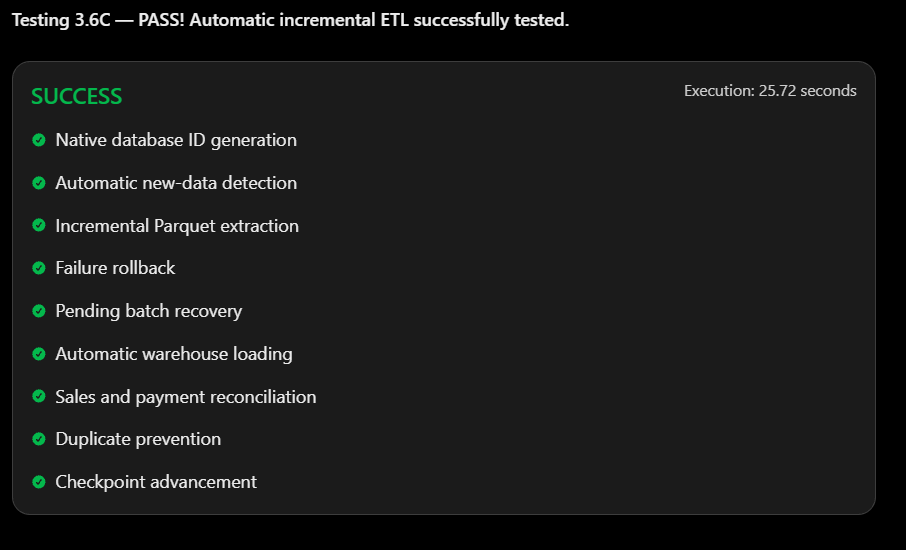

### Phase 4.1 — Existing AI integration

In [47]:
# ==========================================================
# CT-472 | PHASE 4.1
# EXISTING AI INTEGRATION AND DATA READINESS
# ==========================================================

import json
import pandas as pd
import joblib

from sqlalchemy import inspect, text
from pathlib import Path
from datetime import datetime, timezone

print("=" * 85)
print("AI INTEGRATION READINESS")
print("=" * 85)

# 1. Inspect existing AI database objects

with warehouse_engine.connect() as conn:

    inspector = inspect(conn)

    ai_tables = inspector.get_table_names(schema="ai")
    ai_views = inspector.get_view_names(schema="ai")

    ai_schema = {}

    for name in ai_tables + ai_views:

        columns = inspector.get_columns(
            name, schema="ai"
        )

        ai_schema[name] = [
            c["name"] for c in columns
        ]

        count = conn.execute(
            text(f'SELECT COUNT(*) FROM ai."{name}"')
        ).scalar_one()

        print(f"\n{name} | Records: {count}")
        print("Columns:", ai_schema[name])

    registry = pd.read_sql_query(
        text("SELECT * FROM ai.model_registry"),
        conn
    )

    display(registry)

    # 2. Automatically retrieve monthly warehouse sales

    monthly_ai_data = pd.read_sql_query(
        text("""
            SELECT
                DATE_TRUNC('month', d.full_date)::date
                    AS sales_month,
                COUNT(*) AS total_sales_lines,
                SUM(f.quantity) AS total_quantity,
                SUM(f.line_total) AS total_sales
            FROM dw."Fact_Sales" f
            JOIN dw."Dim_Date" d
                ON f.date_key = d.date_key
            WHERE f.date_key <> 0
            GROUP BY 1
            ORDER BY 1
        """),
        conn
    )

monthly_ai_data["sales_month"] = pd.to_datetime(
    monthly_ai_data["sales_month"]
)

current_month = pd.Timestamp.now(
    tz="Asia/Karachi"
).tz_localize(None).to_period("M").to_timestamp()

closed_months = monthly_ai_data[
    monthly_ai_data["sales_month"] < current_month
].copy()

open_months = monthly_ai_data[
    monthly_ai_data["sales_month"] >= current_month
].copy()

print("\nCLOSED MONTHS:", len(closed_months))
print("OPEN / FUTURE MONTHS:", len(open_months))

display(monthly_ai_data.tail(5))

# 3. Verify historical training continuity

expected_months = pd.date_range(
    closed_months["sales_month"].min(),
    current_month - pd.offsets.MonthBegin(1),
    freq="MS"
)

assert closed_months["sales_month"].tolist() == (
    expected_months.tolist()
)

assert closed_months["total_sales"].notna().all()

print("PASS | Historical monthly continuity")

# 4. Locate existing model artifacts

model_root = PROJECT_PATH / "AI_Models"

model_folders = sorted(
    p for p in model_root.iterdir()
    if p.is_dir()
    and (p / "Model_Manifest.json").exists()
    and (p / "Ridge_Forecasting_Model.joblib").exists()
    and (p / "Isolation_Forest_Model.joblib").exists()
)

assert model_folders, "Saved AI models not found."

model_folder = model_folders[-1]

model_manifest = json.loads(
    (model_folder / "Model_Manifest.json").read_text()
)

print("\nMODEL FOLDER:", model_folder.name)

print(json.dumps(model_manifest, indent=2))

# Load trusted model artifacts from our project

ridge_model = joblib.load(
    model_folder / "Ridge_Forecasting_Model.joblib"
)

isolation_model = joblib.load(
    model_folder / "Isolation_Forest_Model.joblib"
)

for name, model in [
    ("Ridge", ridge_model),
    ("Isolation Forest", isolation_model)
]:

    print("\nMODEL:", name)
    print("Object type:", type(model).__name__)

    if hasattr(model, "feature_names_in_"):
        print("Features:", list(model.feature_names_in_))

    if hasattr(model, "n_features_in_"):
        print("Feature count:", model.n_features_in_)

# 5. Final readiness

assert len(ai_tables) == 3
assert len(ai_views) == 2

print("\n" + "=" * 85)
print("PHASE 4.1: PASS")
print("=" * 85)

print("Existing AI tables: VERIFIED")
print("Existing AI views: VERIFIED")
print("Saved AI models: LOADED")
print("Dynamic monthly sales retrieval: PASS")
print("Incomplete month separation: PASS")
print("No existing database records modified.")
print("No new tables created.")
print("No models retrained.")

AI INTEGRATION READINESS

model_registry | Records: 3
Columns: ['model_id', 'model_name', 'model_version', 'algorithm', 'training_start', 'training_end', 'evaluation_metrics', 'created_at']

sales_forecasts | Records: 3
Columns: ['forecast_id', 'model_id', 'forecast_month', 'predicted_sales', 'created_at']

sales_anomalies | Records: 36
Columns: ['anomaly_id', 'model_id', 'sales_month', 'actual_sales', 'sales_per_day', 'daily_z_score', 'isolation_score', 'zscore_flag', 'isolation_flag', 'review_status', 'detection_reason', 'created_at']

vw_sales_forecasts_powerbi | Records: 3
Columns: ['forecast_id', 'forecast_month', 'predicted_sales', 'model_id', 'model_name', 'model_version', 'algorithm', 'training_start', 'training_end', 'forecast_created_at']

vw_sales_anomalies_powerbi | Records: 36
Columns: ['anomaly_id', 'sales_month', 'actual_sales', 'sales_per_day', 'daily_z_score', 'isolation_score', 'zscore_flag', 'isolation_flag', 'review_status', 'detection_reason', 'model_id', 'model_na

,model_id,model_name,model_version,algorithm,training_start,training_end,evaluation_metrics,created_at
0,1,Sales_Forecasting,v1.0,Ridge Regression,2023-11-01,2026-10-31,"{'holdout_mae': 21429954.870277405, 'holdout_r...",2026-11-11 17:49:54.699433+00:00
1,2,Sales_Anomaly_ZScore,v1.0,Daily-normalized Z-Score,2023-11-01,2026-10-31,"{'threshold': 2.0, 'synthetic_test_recall': 1....",2026-11-11 17:49:54.699433+00:00
2,3,Sales_Anomaly_IsolationForest,v1.0,Isolation Forest,2023-11-01,2026-10-31,"{'n_estimators': 200, 'random_state': 42, 'con...",2026-11-11 17:49:54.699433+00:00



CLOSED MONTHS: 36
OPEN / FUTURE MONTHS: 1


,sales_month,total_sales_lines,total_quantity,total_sales
32,2026-07-01,8508,25116.0,2.506947e+09
33,2026-08-01,8250,24892.0,2.479192e+09
34,2026-09-01,8271,24861.0,2.483765e+09
35,2026-10-01,8595,25802.0,2.542442e+09
36,2026-11-01,4,25.0,2.508559e+06


PASS | Historical monthly continuity

MODEL FOLDER: 20261111_175459_479473_UTC
{
  "project": "CT-472 Enterprise Data Warehouse",
  "run_id": "20261111_175459_479473_UTC",
  "forecast_model": "Ridge Regression",
  "anomaly_model": "Isolation Forest",
  "model_version": "v1.0",
  "forecast_training_end": "2026-10-31",
  "forecast_horizon_months": 3,
  "ridge_parameters": {
    "alpha": 1.0,
    "copy_X": true,
    "fit_intercept": true,
    "max_iter": null,
    "positive": false,
    "random_state": null,
    "solver": "auto",
    "tol": 0.0001
  },
  "isolation_forest_parameters": {
    "bootstrap": false,
    "contamination": 0.05,
    "max_features": 1.0,
    "max_samples": "auto",
    "n_estimators": 200,
    "n_jobs": null,
    "random_state": 42,
    "verbose": 0,
    "warm_start": false
  },
  "python_libraries": {
    "scikit_learn": "1.6.1",
    "pandas": "2.2.3",
    "numpy": "2.4.6",
    "joblib": "1.6.0"
  },
  "note": "Models must be used with their original feature engine

### Phase 4.2 — Automated AI execution and integration
Ab existing Ridge model se predictions reproduce karenge, anomaly results validate karenge aur reusable AI function ko master ETL pipeline ke saath integrate karenge.

In [49]:
# ==========================================================
# CT-472 | PHASE 4.2
# AUTOMATED AI EXECUTION AND PIPELINE INTEGRATION
# ==========================================================

import numpy as np
import pandas as pd
import json

from sqlalchemy import text
from datetime import datetime, timezone

AI_AUTOMATION_PATH = TESTING_PATH / "07_AI_Automation"
AI_AUTOMATION_PATH.mkdir(parents=True, exist_ok=True)


def run_ai_pipeline():

    print("=" * 85)
    print("AUTOMATED AI PIPELINE")
    print("=" * 85)

    # 1. Retrieve latest warehouse data

    with warehouse_engine.connect() as conn:

        monthly = pd.read_sql_query(
            text("""
                SELECT
                    DATE_TRUNC('month', d.full_date)::date
                        AS sales_month,
                    SUM(f.line_total) AS total_sales
                FROM dw."Fact_Sales" f
                JOIN dw."Dim_Date" d
                    ON f.date_key = d.date_key
                WHERE f.date_key <> 0
                GROUP BY 1
                ORDER BY 1
            """),
            conn
        )

        forecasts_db = pd.read_sql_query(
            text("""
                SELECT *
                FROM ai.vw_sales_forecasts_powerbi
                WHERE model_version = 'v1.0'
                ORDER BY forecast_month
            """),
            conn
        )

        anomalies_db = pd.read_sql_query(
            text("""
                SELECT *
                FROM ai.vw_sales_anomalies_powerbi
                WHERE model_version = 'v1.0'
                ORDER BY sales_month
            """),
            conn
        )

    monthly["sales_month"] = pd.to_datetime(
        monthly["sales_month"]
    )

    current_month = pd.Timestamp.now(
        tz="Asia/Karachi"
    ).tz_localize(None).to_period("M").to_timestamp()

    historical = monthly[
        monthly["sales_month"] < current_month
    ].copy().reset_index(drop=True)

    incomplete = monthly[
        monthly["sales_month"] == current_month
    ].copy()

    last_closed = (
        historical["sales_month"].max()
        + pd.offsets.MonthEnd(0)
    )

    print("Closed months:", len(historical))

    print(
        "Current month sales:",
        round(incomplete["total_sales"].sum(), 2)
    )

    # 2. Check whether existing models remain applicable

    training_end = pd.Timestamp(
        model_manifest["forecast_training_end"]
    )

    anomalies_db["sales_month"] = pd.to_datetime(
        anomalies_db["sales_month"]
    )

    comparison = historical.merge(
        anomalies_db[["sales_month", "actual_sales"]],
        on="sales_month",
        how="inner",
        validate="one_to_one"
    )

    unchanged = (
        last_closed == training_end
        and len(comparison) == len(historical)
        and np.allclose(
            comparison["total_sales"].astype(float),
            comparison["actual_sales"].astype(float),
            rtol=0,
            atol=0.01
        )
    )

    if not unchanged:

        report = {
            "status": "RETRAIN_REQUIRED",
            "training_end": str(training_end.date()),
            "latest_closed_month": str(last_closed.date())
        }

        save_json(
            AI_AUTOMATION_PATH / "Latest_AI_Run.json",
            report
        )

        print("Closed-month training data changed.")
        print("Model retraining required.")

        return report

    print("PASS | Existing model training data unchanged")

    # 3. Reproduce existing Ridge predictions

    horizon = int(
        model_manifest["forecast_horizon_months"]
    )

    future_months = pd.date_range(
        historical["sales_month"].max()
        + pd.offsets.MonthBegin(1),
        periods=horizon,
        freq="MS"
    )

    features = pd.DataFrame({
        "time_index": np.arange(
            len(historical),
            len(historical) + horizon
        )
    })

    for month in range(2, 13):

        features[f"month_{month}"] = (
            future_months.month == month
        ).astype(int)

    features = features[
        list(ridge_model.feature_names_in_)
    ]

    predicted = ridge_model.predict(features) * 1_000_000_000

    forecast_result = pd.DataFrame({
        "forecast_month": future_months,
        "predicted_sales": predicted
    })

    forecasts_db["forecast_month"] = pd.to_datetime(
        forecasts_db["forecast_month"]
    )

    assert forecast_result["forecast_month"].tolist() == (
        forecasts_db["forecast_month"].tolist()
    )

    np.testing.assert_allclose(
        forecast_result["predicted_sales"],
        forecasts_db["predicted_sales"].astype(float),
        rtol=0,
        atol=0.02
    )

    print("PASS | Saved Ridge predictions reproduced")

    display(forecast_result)

    # 4. Reproduce Isolation Forest predictions

    historical["sales_per_day"] = (
        historical["total_sales"].astype(float)
        / historical["sales_month"].dt.days_in_month
    )

    anomaly_features = historical[["sales_per_day"]]

    historical["isolation_flag"] = (
        isolation_model.predict(anomaly_features) == -1
    )

    historical["isolation_score"] = (
        isolation_model.decision_function(anomaly_features)
    )

    verified_anomalies = historical.merge(
        anomalies_db[
            [
                "sales_month",
                "isolation_flag",
                "zscore_flag",
                "review_status"
            ]
        ],
        on="sales_month",
        suffixes=("_recomputed", "_stored"),
        validate="one_to_one"
    )

    assert len(verified_anomalies) == len(historical)

    assert (
        verified_anomalies[
            "isolation_flag_recomputed"
        ].astype(int)
        ==
        verified_anomalies[
            "isolation_flag_stored"
        ].astype(int)
    ).all()

    print("PASS | Isolation Forest flags reproduced")

    print("\nExisting anomaly review results:")

    print(
        anomalies_db["review_status"]
        .value_counts()
        .to_string()
    )

    # 5. Save automation evidence

    run_id = datetime.now(timezone.utc).strftime(
        "%Y%m%d_%H%M%S_%f"
    )

    run_folder = AI_AUTOMATION_PATH / run_id
    run_folder.mkdir(exist_ok=False)

    forecast_result.to_csv(
        run_folder / "Forecast_Verification.csv",
        index=False
    )

    verified_anomalies.to_csv(
        run_folder / "Anomaly_Verification.csv",
        index=False
    )

    incomplete.to_csv(
        run_folder / "Current_Month_Sales.csv",
        index=False
    )

    report = {
        "status": "SUCCESS",
        "model_version": model_manifest["model_version"],
        "closed_months": len(historical),
        "forecasts_verified": len(forecast_result),
        "anomaly_months_verified": len(verified_anomalies),
        "current_month_sales": float(
            incomplete["total_sales"].sum()
        ),
        "database_rows_inserted": 0,
        "retraining_required": False
    }

    save_json(
        run_folder / "AI_Run_Report.json",
        report
    )

    save_json(
        AI_AUTOMATION_PATH / "Latest_AI_Run.json",
        report
    )

    return report


# 6. Combine automated ETL and AI

def run_complete_enterprise_pipeline():

    etl_result = run_enterprise_pipeline()

    assert etl_result["status"] in [
        "SUCCESS", "NO_NEW_DATA"
    ]

    ai_result = run_ai_pipeline()

    return {
        "etl": etl_result,
        "ai": ai_result
    }


# 7. Execute integrated pipeline

enterprise_result = run_complete_enterprise_pipeline()

assert enterprise_result["ai"]["status"] == "SUCCESS"

print("\n" + "=" * 85)
print("PHASE 4.2: PASS")
print("=" * 85)

print("ETL and AI integration: PASS")
print("Ridge prediction verification: PASS")
print("Isolation Forest verification: PASS")
print("Incomplete month protection: PASS")
print("Unnecessary retraining avoided.")
print("No duplicate AI database records inserted.")
print("No new tables created.")

print(json.dumps(enterprise_result, indent=2, default=str))

CT-472 | ENTERPRISE AUTOMATED ETL PIPELINE
Finance.fiscal_periods | New records: 0
Finance.journal_entries | New records: 0
Finance.journal_entry_lines | New records: 0
Finance.accounts | New records: 0
Finance.cost_centers | New records: 0
Finance.budgets | New records: 0
Finance.exchange_rates | New records: 0
Sales.categories | New records: 0
Sales.products | New records: 0
Sales.customers | New records: 0
Sales.sales_orders | New records: 0
Sales.locations | New records: 0
Sales.sales_order_lines | New records: 0
Sales.payments | New records: 0
Purchasing.categories | New records: 0
Purchasing.goods_receipt_lines | New records: 0
Purchasing.goods_receipts | New records: 0
Purchasing.locations | New records: 0
Purchasing.products | New records: 0
Purchasing.purchase_order_lines | New records: 0
Purchasing.purchase_orders | New records: 0
Purchasing.suppliers | New records: 0
Inventory.products_replica | New records: 0
Inventory.locations_replica | New records: 0
Inventory.warehouses

,forecast_month,predicted_sales
0,2026-11-01,2.508635e+09
1,2026-12-01,2.510715e+09
2,2027-01-01,2.490819e+09


PASS | Isolation Forest flags reproduced

Existing anomaly review results:
review_status
No Flag             34
Secondary Review     2

PHASE 4.2: PASS
ETL and AI integration: PASS
Ridge prediction verification: PASS
Isolation Forest verification: PASS
Incomplete month protection: PASS
Unnecessary retraining avoided.
No duplicate AI database records inserted.
No new tables created.
{
  "etl": {
    "status": "NO_NEW_DATA",
    "source_records": 0,
    "warehouse_inserted": 0
  },
  "ai": {
    "status": "SUCCESS",
    "model_version": "v1.0",
    "closed_months": 36,
    "forecasts_verified": 3,
    "anomaly_months_verified": 36,
    "current_month_sales": 2508559.2,
    "database_rows_inserted": 0,
    "retraining_required": false
  }
}


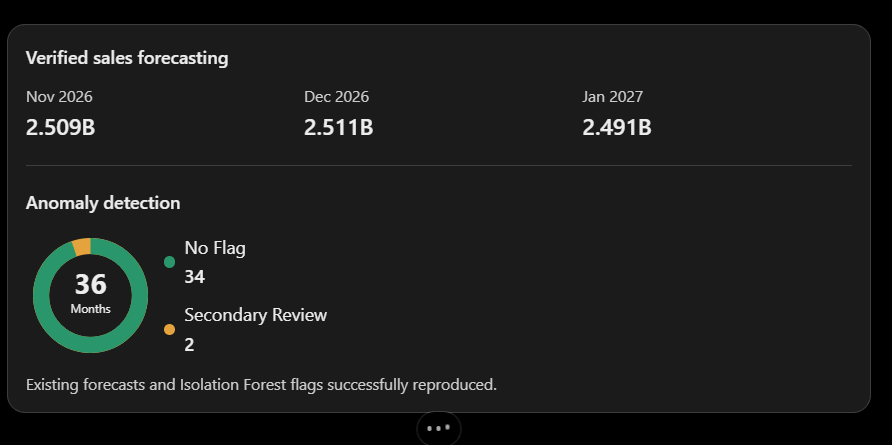

### Phase 4.3 — Automatic retraining and model versioning
Ab important kaam karenge: jab future mein complete month's data available hoga, pipeline khud detect karegi, models retrain karegi aur new version generate karegi. Historical models preserve rahenge.

Is step mein hum retraining ke saath holdout testing, model versioning aur duplicate protection bhi implement karenge.

In [50]:
# ==========================================================
# CT-472 | PHASE 4.3
# AUTOMATIC MODEL RETRAINING AND VERSIONED PUBLICATION
# ==========================================================

import hashlib
import joblib
import numpy as np
import pandas as pd

from sklearn.base import clone
from sqlalchemy import MetaData, Table, text
from datetime import datetime, timezone


def build_ai_features(months, start_index=0):

    months = pd.DatetimeIndex(months)

    X = pd.DataFrame({
        "time_index": np.arange(
            start_index, start_index + len(months)
        )
    })

    for m in range(2, 13):
        X[f"month_{m}"] = (months.month == m).astype(int)

    return X[list(ridge_model.feature_names_in_)]


def train_ai_candidate(data):

    data = data.copy().reset_index(drop=True)

    data["sales_month"] = pd.to_datetime(
        data["sales_month"]
    )

    months = pd.DatetimeIndex(data["sales_month"])

    assert len(data) >= 24
    assert months.equals(
        pd.date_range(months.min(), months.max(), freq="MS")
    )

    y = data["total_sales"].to_numpy(dtype=float)

    assert np.isfinite(y).all()

    X = build_ai_features(months)

    # Chronological holdout: last three months

    candidate = clone(ridge_model)

    candidate.fit(X.iloc[:-3], y[:-3] / 1e9)

    test_predictions = candidate.predict(
        X.iloc[-3:]
    ) * 1e9

    baseline = y[-15:-12]

    ridge_mae = float(
        np.mean(np.abs(y[-3:] - test_predictions))
    )

    baseline_mae = float(
        np.mean(np.abs(y[-3:] - baseline))
    )

    ridge_rmse = float(
        np.sqrt(np.mean((y[-3:] - test_predictions)**2))
    )

    # Train final candidate on all complete months

    candidate.fit(X, y / 1e9)

    future_months = pd.date_range(
        months.max() + pd.offsets.MonthBegin(1),
        periods=3,
        freq="MS"
    )

    future_X = build_ai_features(
        future_months, len(data)
    )

    forecasts = candidate.predict(future_X) * 1e9

    assert np.isfinite(forecasts).all()
    assert (forecasts >= 0).all()

    # Daily-normalized anomaly detection

    daily = pd.DataFrame({
        "sales_per_day": y / months.days_in_month
    })

    std = daily["sales_per_day"].std(ddof=0)

    z = (
        (daily["sales_per_day"] - daily["sales_per_day"].mean())
        / std
        if std > 0
        else pd.Series(np.zeros(len(data)))
    )

    z_flag = z.abs() > 2

    forest = clone(isolation_model)

    forest.fit(daily)

    iso_flag = forest.predict(daily) == -1

    iso_score = forest.decision_function(daily)

    status = np.select(
        [z_flag & iso_flag, z_flag | iso_flag],
        ["Priority Review", "Secondary Review"],
        default="No Flag"
    )

    anomaly = pd.DataFrame({
        "sales_month": months,
        "actual_sales": y,
        "sales_per_day": daily["sales_per_day"],
        "daily_z_score": z,
        "isolation_score": iso_score,
        "zscore_flag": z_flag,
        "isolation_flag": iso_flag,
        "review_status": status,
        "detection_reason": np.select(
            [z_flag & iso_flag, z_flag, iso_flag],
            ["Both models", "Z-Score", "Isolation Forest"],
            default="No anomaly flag"
        )
    })

    forecast = pd.DataFrame({
        "forecast_month": future_months,
        "predicted_sales": forecasts
    })

    metrics = {
        "holdout_mae": ridge_mae,
        "holdout_rmse": ridge_rmse,
        "baseline_mae": baseline_mae,
        "training_months": len(data)
    }

    return candidate, forest, forecast, anomaly, metrics


def run_versioned_ai_pipeline():

    with warehouse_engine.connect() as conn:

        data = pd.read_sql_query(
            text("""
                SELECT
                    DATE_TRUNC('month', d.full_date)::date
                        AS sales_month,
                    SUM(f.line_total) AS total_sales
                FROM dw."Fact_Sales" f
                JOIN dw."Dim_Date" d
                    ON f.date_key = d.date_key
                WHERE f.date_key <> 0
                GROUP BY 1
                ORDER BY 1
            """),
            conn
        )

    data["sales_month"] = pd.to_datetime(data["sales_month"])

    cutoff = (
        pd.Timestamp.now(tz="Asia/Karachi")
        .tz_localize(None)
        .to_period("M")
        .to_timestamp()
    )

    data = data[data["sales_month"] < cutoff].copy()

    training_hash = hashlib.sha256(
        data.to_csv(index=False, float_format="%.2f").encode()
    ).hexdigest()

    version = "auto_" + training_hash[:20]

    model_names = [
        "Sales_Forecasting",
        "Sales_Anomaly_ZScore",
        "Sales_Anomaly_IsolationForest"
    ]

    # Skip if this training dataset is already published

    with warehouse_engine.connect() as conn:

        registered = conn.execute(
            text("""
                SELECT COUNT(DISTINCT model_name)
                FROM ai.model_registry
                WHERE model_version = :version
            """),
            {"version": version}
        ).scalar_one()

    if registered == 3:

        print("PASS | Training version already registered")

        return {
            "status": "SUCCESS",
            "model_version": version,
            "retrained": False
        }

    # Reuse original verified model if applicable

    original = run_ai_pipeline()

    if original["status"] == "SUCCESS":

        original["retrained"] = False

        return original

    assert original["status"] == "RETRAIN_REQUIRED"

    # Train and evaluate new candidates

    ridge, forest, forecast, anomaly, metrics = (
        train_ai_candidate(data)
    )

    print("Candidate evaluation:", metrics)

    # Quality gate before database publication

    if metrics["holdout_mae"] > metrics["baseline_mae"]:

        return {
            "status": "MODEL_REVIEW_REQUIRED",
            "metrics": metrics,
            "retrained": True,
            "published": False
        }

    folder = AI_AUTOMATION_PATH / "Versions" / version

    folder.mkdir(parents=True, exist_ok=True)

    joblib.dump(ridge, folder / "Ridge_Forecasting_Model.joblib")

    joblib.dump(forest, folder / "Isolation_Forest_Model.joblib")

    data.to_csv(folder / "Training_Data.csv", index=False)

    forecast.to_csv(folder / "Forecasts.csv", index=False)

    anomaly.to_csv(folder / "Anomalies.csv", index=False)

    start = data["sales_month"].min().date()

    end = (
        data["sales_month"].max() + pd.offsets.MonthEnd(0)
    ).date()

    now = datetime.now(timezone.utc)

    save_json(folder / "Model_Manifest.json", {
        "model_version": version,
        "training_hash": training_hash,
        "training_start": str(start),
        "forecast_training_end": str(end),
        "forecast_horizon_months": 3,
        "forecast_scale": 1000000000,
        "metrics": metrics
    })

    # Publish all AI records in one warehouse transaction

    with warehouse_engine.begin() as conn:

        for name in [
            "model_registry",
            "sales_forecasts",
            "sales_anomalies"
        ]:

            conn.execute(text(
                f'LOCK TABLE ai."{name}" '
                'IN SHARE ROW EXCLUSIVE MODE'
            ))

        existing = conn.execute(
            text("""
                SELECT COUNT(*)
                FROM ai.model_registry
                WHERE model_version = :version
            """),
            {"version": version}
        ).scalar_one()

        assert existing == 0, "Version already exists."

        md = MetaData()

        tables = {
            name: Table(
                name, md, schema="ai",
                autoload_with=conn
            )
            for name in [
                "model_registry",
                "sales_forecasts",
                "sales_anomalies"
            ]
        }

        # Allocate IDs under table locks

        def next_id(table, field):

            return conn.execute(text(
                f'SELECT COALESCE(MAX("{field}"), 0) + 1 '
                f'FROM ai."{table}"'
            )).scalar_one()

        model_start = next_id("model_registry", "model_id")

        model_ids = {}

        for i, (name, algorithm) in enumerate(zip(
            model_names,
            [
                "Ridge Regression",
                "Daily-normalized Z-Score",
                "Isolation Forest"
            ]
        )):

            mid = model_start + i

            model_ids[name] = mid

            conn.execute(
                tables["model_registry"].insert().values(
                    model_id=mid,
                    model_name=name,
                    model_version=version,
                    algorithm=algorithm,
                    training_start=start,
                    training_end=end,
                    evaluation_metrics=(
                        metrics if i == 0 else
                        {"training_months": len(data)}
                    ),
                    created_at=now
                )
            )

        fid = next_id("sales_forecasts", "forecast_id")

        for i, row in enumerate(
            forecast.to_dict("records")
        ):

            conn.execute(
                tables["sales_forecasts"].insert().values(
                    forecast_id=fid + i,
                    model_id=model_ids["Sales_Forecasting"],
                    forecast_month=row["forecast_month"].date(),
                    predicted_sales=round(
                        row["predicted_sales"], 2
                    ),
                    created_at=now
                )
            )

        aid = next_id("sales_anomalies", "anomaly_id")

        for i, row in enumerate(anomaly.to_dict("records")):

            row["sales_month"] = row["sales_month"].date()

            conn.execute(
                tables["sales_anomalies"].insert().values(
                    anomaly_id=aid + i,
                    model_id=model_ids[
                        "Sales_Anomaly_IsolationForest"
                    ],
                    created_at=now,
                    **row
                )
            )

        assert conn.execute(text("""
            SELECT COUNT(*)
            FROM ai.sales_forecasts
            WHERE model_id = :mid
        """), {
            "mid": model_ids["Sales_Forecasting"]
        }).scalar_one() == 3

        assert conn.execute(text("""
            SELECT COUNT(*)
            FROM ai.sales_anomalies
            WHERE model_id = :mid
        """), {
            "mid": model_ids["Sales_Anomaly_IsolationForest"]
        }).scalar_one() == len(data)

    return {
        "status": "SUCCESS",
        "model_version": version,
        "retrained": True,
        "published": True,
        "metrics": metrics
    }


# ==========================================================
# TEST 1: RETRAINING DRY RUN
# No new database records
# ==========================================================

test_ridge, test_forest, test_forecast, test_anomaly, test_metrics = (
    train_ai_candidate(closed_months)
)

print("PASS | Candidate retraining executed")

display(pd.DataFrame([test_metrics]))
display(test_forecast)

assert len(test_forecast) == 3
assert len(test_anomaly) == len(closed_months)

print("PASS | Candidate output validation")


# ==========================================================
# TEST 2: AUTOMATIC MODEL REUSE
# ==========================================================

ai_version_result = run_versioned_ai_pipeline()

assert ai_version_result["status"] == "SUCCESS"
assert ai_version_result["retrained"] is False

print("PASS | Unnecessary retraining prevented")


# ==========================================================
# FINAL INTEGRATED FUNCTION
# ==========================================================

def run_complete_enterprise_pipeline():

    etl = run_enterprise_pipeline()

    assert etl["status"] in ["SUCCESS", "NO_NEW_DATA"]

    ai = run_versioned_ai_pipeline()

    return {
        "etl": etl,
        "ai": ai,
        "status": ai["status"]
    }


print("\n" + "=" * 85)
print("PHASE 4.3: DRY-RUN AND REUSE TEST PASS")
print("=" * 85)

print("Retraining function: READY")
print("Model versioning: IMPLEMENTED")
print("Forecast quality gate: IMPLEMENTED")
print("Transactional AI publication: IMPLEMENTED")
print("Existing models preserved: YES")
print("New tables created: 0")
print("Live new-version publication: NOT YET TESTED")

PASS | Candidate retraining executed


,holdout_mae,holdout_rmse,baseline_mae,training_months
0,2.142995e+07,2.548579e+07,2.649672e+07,36


,forecast_month,predicted_sales
0,2026-11-01,2.508635e+09
1,2026-12-01,2.510715e+09
2,2027-01-01,2.490819e+09


PASS | Candidate output validation
AUTOMATED AI PIPELINE
Closed months: 36
Current month sales: 2508559.2
PASS | Existing model training data unchanged
PASS | Saved Ridge predictions reproduced


,forecast_month,predicted_sales
0,2026-11-01,2.508635e+09
1,2026-12-01,2.510715e+09
2,2027-01-01,2.490819e+09


PASS | Isolation Forest flags reproduced

Existing anomaly review results:
review_status
No Flag             34
Secondary Review     2
PASS | Unnecessary retraining prevented

PHASE 4.3: DRY-RUN AND REUSE TEST PASS
Retraining function: READY
Model versioning: IMPLEMENTED
Forecast quality gate: IMPLEMENTED
Transactional AI publication: IMPLEMENTED
Existing models preserved: YES
New tables created: 0
Live new-version publication: NOT YET TESTED


### Phase 4.4 + 5.1 — AI publication testing and Power BI readiness
Ye code existing AI tables mein transactional publication test karega, test records rollback karega, Power BI views ko latest model version ke according configure karega aur dashboard verification ke liye expected KPIs generate karega.

In [52]:
# ==========================================================
# CT-472 | PHASE 4.4 + 5.1 CORRECTED
# NATIVE ID GENERATION + AI PUBLICATION + POWER BI
# ==========================================================

from sqlalchemy import text, MetaData, Table
from datetime import datetime, timezone
import pandas as pd
import json
import uuid

BI_PATH = TESTING_PATH / "08_PowerBI_Integration"
BI_PATH.mkdir(parents=True, exist_ok=True)

# 1. Reusable AI publication function

def publish_ai_records(
    conn, version, data, forecast, anomaly, metrics
):

    md = MetaData()

    tables = {
        name: Table(
            name, md, schema="ai", autoload_with=conn
        )
        for name in [
            "model_registry",
            "sales_forecasts",
            "sales_anomalies"
        ]
    }

    now = datetime.now(timezone.utc)

    model_ids = {}

    for name, algorithm in [
        ("Sales_Forecasting", "Ridge Regression"),
        ("Sales_Anomaly_ZScore", "Daily-normalized Z-Score"),
        ("Sales_Anomaly_IsolationForest", "Isolation Forest")
    ]:

        registry_table = tables["model_registry"]

        model_ids[name] = conn.execute(
            registry_table.insert().values(
                model_name=name,
                model_version=version,
                algorithm=algorithm,
                training_start=data["sales_month"].min().date(),
                training_end=(
                    data["sales_month"].max()
                    + pd.offsets.MonthEnd(0)
                ).date(),
                evaluation_metrics=(
                    metrics if name == "Sales_Forecasting"
                    else {"training_months": len(data)}
                ),
                created_at=now
            ).returning(registry_table.c.model_id)
        ).scalar_one()

    for row in forecast.to_dict("records"):

        conn.execute(
            tables["sales_forecasts"].insert().values(
                model_id=model_ids["Sales_Forecasting"],
                forecast_month=row["forecast_month"].date(),
                predicted_sales=round(
                    float(row["predicted_sales"]), 2
                ),
                created_at=now
            )
        )

    for row in anomaly.to_dict("records"):

        row["sales_month"] = row["sales_month"].date()

        conn.execute(
            tables["sales_anomalies"].insert().values(
                model_id=model_ids[
                    "Sales_Anomaly_IsolationForest"
                ],
                created_at=now,
                **row
            )
        )

    return model_ids


# 2. Test actual AI inserts with native IDs

print("=" * 85)
print("AI PUBLICATION AND ROLLBACK TEST")
print("=" * 85)

ai_names = [
    "model_registry",
    "sales_forecasts",
    "sales_anomalies"
]

test_version = "TEST_" + uuid.uuid4().hex[:12]

try:

    with warehouse_engine.begin() as conn:

        for name in ai_names:

            conn.execute(text(
                f'LOCK TABLE ai."{name}" '
                'IN SHARE ROW EXCLUSIVE MODE'
            ))

        ai_before = {
            name: conn.execute(text(
                f'SELECT COUNT(*) FROM ai."{name}"'
            )).scalar_one()
            for name in ai_names
        }

        generated_ids = publish_ai_records(
            conn,
            test_version,
            closed_months,
            test_forecast,
            test_anomaly,
            test_metrics
        )

        print("Generated AI model IDs:", generated_ids)

        expected = {
            "model_registry": 3,
            "sales_forecasts": 3,
            "sales_anomalies": len(test_anomaly)
        }

        for name, added in expected.items():

            count = conn.execute(text(
                f'SELECT COUNT(*) FROM ai."{name}"'
            )).scalar_one()

            assert count == ai_before[name] + added

            print(f"PASS | {name} | Inserted: {added}")

        raise RuntimeError("CONTROLLED_AI_ROLLBACK")

except RuntimeError as error:

    if str(error) != "CONTROLLED_AI_ROLLBACK":
        raise

    print("PASS | Controlled rollback")


with warehouse_engine.connect() as conn:

    for name in ai_names:

        count = conn.execute(text(
            f'SELECT COUNT(*) FROM ai."{name}"'
        )).scalar_one()

        assert count == ai_before[name]

        print(f"PASS | {name} | Original records preserved")


# 3. Correct automatic model publication function

import hashlib
import joblib


def run_versioned_ai_pipeline():

    with warehouse_engine.connect() as conn:

        data = pd.read_sql_query(
            text("""
                SELECT
                    DATE_TRUNC('month', d.full_date)::date
                        AS sales_month,
                    SUM(f.line_total) AS total_sales
                FROM dw."Fact_Sales" f
                JOIN dw."Dim_Date" d
                    ON f.date_key = d.date_key
                WHERE f.date_key <> 0
                GROUP BY 1
                ORDER BY 1
            """),
            conn
        )

    data["sales_month"] = pd.to_datetime(data["sales_month"])

    cutoff = (
        pd.Timestamp.now(tz="Asia/Karachi")
        .tz_localize(None)
        .to_period("M")
        .to_timestamp()
    )

    data = data[data["sales_month"] < cutoff].copy()

    assert len(data) >= 24

    assert data["sales_month"].max() == (
        cutoff - pd.offsets.MonthBegin(1)
    ), "Latest closed month missing."

    training_hash = hashlib.sha256(
        data.to_csv(
            index=False,
            float_format="%.2f"
        ).encode()
    ).hexdigest()

    version = "auto_" + training_hash[:20]

    with warehouse_engine.connect() as conn:

        registered = conn.execute(
            text("""
                SELECT COUNT(DISTINCT model_name)
                FROM ai.model_registry
                WHERE model_version = :version
            """),
            {"version": version}
        ).scalar_one()

        original_data = pd.read_sql_query(
            text("""
                SELECT a.sales_month, a.actual_sales
                FROM ai.sales_anomalies a
                JOIN ai.model_registry m
                    ON a.model_id = m.model_id
                WHERE m.model_version = 'v1.0'
                ORDER BY a.sales_month
            """),
            conn
        )

    if registered == 3:

        print("PASS | Existing model version reused")

        return {
            "status": "SUCCESS",
            "model_version": version,
            "retrained": False
        }

    original_data["sales_month"] = pd.to_datetime(
        original_data["sales_month"]
    )

    if (
        len(data) == len(original_data)
        and data["sales_month"].tolist()
            == original_data["sales_month"].tolist()
        and np.allclose(
            data["total_sales"].astype(float),
            original_data["actual_sales"].astype(float),
            rtol=0,
            atol=0.01
        )
    ):

        return {
            "status": "SUCCESS",
            "model_version": "v1.0",
            "retrained": False
        }

    ridge, forest, forecast, anomaly, metrics = (
        train_ai_candidate(data)
    )

    if metrics["holdout_mae"] > metrics["baseline_mae"]:

        return {
            "status": "MODEL_REVIEW_REQUIRED",
            "metrics": metrics
        }

    folder = AI_AUTOMATION_PATH / "Versions" / version
    folder.mkdir(parents=True, exist_ok=True)

    joblib.dump(
        ridge, folder / "Ridge_Forecasting_Model.joblib"
    )

    joblib.dump(
        forest, folder / "Isolation_Forest_Model.joblib"
    )

    data.to_csv(folder / "Training_Data.csv", index=False)
    forecast.to_csv(folder / "Forecasts.csv", index=False)
    anomaly.to_csv(folder / "Anomalies.csv", index=False)

    save_json(folder / "Model_Manifest.json", {
        "model_version": version,
        "training_hash": training_hash,
        "forecast_scale": 1_000_000_000,
        "metrics": metrics
    })

    with warehouse_engine.begin() as conn:

        for name in ai_names:

            conn.execute(text(
                f'LOCK TABLE ai."{name}" '
                'IN SHARE ROW EXCLUSIVE MODE'
            ))

        exists = conn.execute(
            text("""
                SELECT COUNT(*)
                FROM ai.model_registry
                WHERE model_version = :version
            """),
            {"version": version}
        ).scalar_one()

        if exists == 3:

            return {
                "status": "SUCCESS",
                "model_version": version,
                "retrained": False
            }

        assert exists == 0

        ids = publish_ai_records(
            conn, version, data,
            forecast, anomaly, metrics
        )

        for table, model_name, expected_count in [
            ("sales_forecasts", "Sales_Forecasting", 3),
            (
                "sales_anomalies",
                "Sales_Anomaly_IsolationForest",
                len(data)
            )
        ]:

            count = conn.execute(
                text(
                    f'SELECT COUNT(*) FROM ai."{table}" '
                    'WHERE model_id = :mid'
                ),
                {"mid": ids[model_name]}
            ).scalar_one()

            assert count == expected_count

    return {
        "status": "SUCCESS",
        "model_version": version,
        "retrained": True,
        "published": True
    }


# 4. Latest-model Power BI views

with warehouse_engine.begin() as conn:

    conn.execute(text("""
        CREATE OR REPLACE VIEW ai.vw_sales_forecasts_powerbi AS
        SELECT
            f.forecast_id,
            f.forecast_month,
            f.predicted_sales,
            m.model_id,
            m.model_name,
            m.model_version,
            m.algorithm,
            m.training_start,
            m.training_end,
            f.created_at AS forecast_created_at
        FROM ai.sales_forecasts f
        JOIN ai.model_registry m
            ON f.model_id = m.model_id
        WHERE m.model_id = (
            SELECT r.model_id
            FROM ai.model_registry r
            WHERE r.model_name = 'Sales_Forecasting'
              AND EXISTS (
                  SELECT 1 FROM ai.sales_forecasts x
                  WHERE x.model_id = r.model_id
              )
            ORDER BY r.training_end DESC,
                     r.created_at DESC,
                     r.model_id DESC
            LIMIT 1
        )
    """))

    conn.execute(text("""
        CREATE OR REPLACE VIEW ai.vw_sales_anomalies_powerbi AS
        SELECT
            a.anomaly_id,
            a.sales_month,
            a.actual_sales,
            a.sales_per_day,
            a.daily_z_score,
            a.isolation_score,
            a.zscore_flag,
            a.isolation_flag,
            a.review_status,
            a.detection_reason,
            m.model_id,
            m.model_name,
            m.model_version,
            a.created_at AS detection_created_at
        FROM ai.sales_anomalies a
        JOIN ai.model_registry m
            ON a.model_id = m.model_id
        WHERE m.model_id = (
            SELECT r.model_id
            FROM ai.model_registry r
            WHERE EXISTS (
                SELECT 1 FROM ai.sales_anomalies x
                WHERE x.model_id = r.model_id
            )
            ORDER BY r.training_end DESC,
                     r.created_at DESC,
                     r.model_id DESC
            LIMIT 1
        )
    """))

    forecasts = pd.read_sql_query(
        text("SELECT * FROM ai.vw_sales_forecasts_powerbi"),
        conn
    )

    anomalies = pd.read_sql_query(
        text("SELECT * FROM ai.vw_sales_anomalies_powerbi"),
        conn
    )

    assert len(forecasts) == 3
    assert forecasts["forecast_month"].is_unique
    assert anomalies["sales_month"].is_unique

    assert forecasts["model_version"].nunique() == 1
    assert anomalies["model_version"].nunique() == 1

    assert (
        forecasts["model_version"].iloc[0]
        == anomalies["model_version"].iloc[0]
    )

print("PASS | Latest-model Power BI views")


# 5. Dashboard KPI verification

queries = {
    "Total Sales":
        'SELECT SUM(line_total) FROM dw."Fact_Sales"',

    "Units Sold":
        'SELECT SUM(quantity) FROM dw."Fact_Sales"',

    "Sales Orders":
        'SELECT COUNT(DISTINCT order_id) FROM dw."Fact_Sales"',

    "Total Payments":
        'SELECT SUM(payment_amount) FROM dw."Fact_Payment"',

    "Total Purchasing":
        'SELECT SUM(line_total) FROM dw."Fact_Purchase"',

    "Purchased Quantity":
        'SELECT SUM(quantity) FROM dw."Fact_Purchase"',

    "Current Inventory": """
        SELECT SUM(quantity_on_hand)
        FROM (
            SELECT DISTINCT ON (product_key, warehouse_key)
                   quantity_on_hand
            FROM dw."Fact_Inventory_Balance"
            ORDER BY product_key, warehouse_key,
                     date_key DESC, inventory_balance_key DESC
        ) latest
    """,

    "Inventory Movements":
        'SELECT COUNT(*) FROM dw."Fact_Inventory_Movement"',

    "Total Debit":
        'SELECT SUM(debit) FROM dw."Fact_Journal_Entry_Line"',

    "Total Credit":
        'SELECT SUM(credit) FROM dw."Fact_Journal_Entry_Line"',

    "Total Budget":
        'SELECT SUM(budget_amount) FROM dw."Fact_Budget"',

    "Forecast Months":
        "SELECT COUNT(*) FROM ai.vw_sales_forecasts_powerbi",

    "Anomaly Months":
        "SELECT COUNT(*) FROM ai.vw_sales_anomalies_powerbi",

    "Flagged Months": """
        SELECT COUNT(*)
        FROM ai.vw_sales_anomalies_powerbi
        WHERE zscore_flag OR isolation_flag
    """
}

with warehouse_engine.connect() as conn:

    kpis = {
        name: conn.execute(text(sql)).scalar_one()
        for name, sql in queries.items()
    }

assert kpis["Total Sales"] == kpis["Total Payments"]
assert kpis["Total Debit"] == kpis["Total Credit"]

kpi_df = pd.DataFrame(
    list(kpis.items()),
    columns=["Dashboard_KPI", "Expected_Value"]
)

display(kpi_df)

kpi_df.to_csv(
    BI_PATH / "Expected_Dashboard_KPIs.csv",
    index=False
)

forecasts.to_csv(
    BI_PATH / "Latest_AI_Forecasts.csv",
    index=False
)

anomalies.to_csv(
    BI_PATH / "Latest_AI_Anomalies.csv",
    index=False
)


# 6. Confirm automatic AI reuse

ai_result = run_versioned_ai_pipeline()

assert ai_result["status"] == "SUCCESS"
assert ai_result["retrained"] is False

report = {
    "ai_native_ids": "PASS",
    "ai_transactional_insert": "PASS",
    "ai_rollback": "PASS",
    "latest_model_views": "PASS",
    "automatic_model_reuse": "PASS",
    "dashboard_kpis": len(kpis),
    "new_tables_created": 0,
    "live_new_version_publication_tested": False,
    "powerbi_actual_refresh_verified": False
}

save_json(
    BI_PATH / "Integration_Validation.json",
    report
)

print("\n" + "=" * 85)
print("PHASE 4.4 + 5.1: PASS")
print("=" * 85)

print(json.dumps(report, indent=2))

AI PUBLICATION AND ROLLBACK TEST
Generated AI model IDs: {'Sales_Forecasting': 4, 'Sales_Anomaly_ZScore': 5, 'Sales_Anomaly_IsolationForest': 6}
PASS | model_registry | Inserted: 3
PASS | sales_forecasts | Inserted: 3
PASS | sales_anomalies | Inserted: 36
PASS | Controlled rollback
PASS | model_registry | Original records preserved
PASS | sales_forecasts | Original records preserved
PASS | sales_anomalies | Original records preserved
PASS | Latest-model Power BI views


,Dashboard_KPI,Expected_Value
0,Total Sales,89852282683.570000
1,Units Sold,899752
2,Sales Orders,100002
3,Total Payments,89852282683.570000
4,Total Purchasing,456484970462.440000
5,Purchased Quantity,6296289
6,Current Inventory,63755235
7,Inventory Movements,590006
8,Total Debit,37524581008.070000
9,Total Credit,37524581008.070000



PHASE 4.4 + 5.1: PASS
{
  "ai_native_ids": "PASS",
  "ai_transactional_insert": "PASS",
  "ai_rollback": "PASS",
  "latest_model_views": "PASS",
  "automatic_model_reuse": "PASS",
  "dashboard_kpis": 14,
  "new_tables_created": 0,
  "live_new_version_publication_tested": false,
  "powerbi_actual_refresh_verified": false
}


### Phase 6 — Final Pipeline Execution, Validation and Handove

In [53]:
# ==========================================================
# CT-472 | PHASE 6
# FINAL ENTERPRISE PIPELINE VALIDATION
# ==========================================================

import pandas as pd
import json
import time

from datetime import datetime, timezone
from sqlalchemy import text, inspect

FINAL_PATH = TESTING_PATH / "09_Final_Production_Validation"
FINAL_PATH.mkdir(parents=True, exist_ok=True)

RUN_ID = datetime.now(timezone.utc).strftime(
    "%Y%m%d_%H%M%S_%f"
)

RUN_PATH = FINAL_PATH / RUN_ID
RUN_PATH.mkdir(parents=True, exist_ok=True)

checks = []

def check(name, condition, detail=""):

    passed = bool(condition)

    checks.append({
        "Validation": name,
        "Status": "PASS" if passed else "FAIL",
        "Details": str(detail)
    })

    print(
        f"{'PASS' if passed else 'FAIL'} | "
        f"{name} | {detail}"
    )


# ==========================================================
# 1. FINAL MASTER PIPELINE
# ==========================================================

def run_final_enterprise_pipeline():

    start = time.perf_counter()

    etl = run_enterprise_pipeline()

    if etl["status"] not in ["SUCCESS", "NO_NEW_DATA"]:
        raise RuntimeError("ETL execution unsuccessful")

    ai = run_versioned_ai_pipeline()

    result = {
        "executed_at": datetime.now(
            timezone.utc
        ).isoformat(),
        "status": (
            "SUCCESS"
            if ai["status"] == "SUCCESS"
            else "AI_REVIEW_REQUIRED"
        ),
        "etl": etl,
        "ai": ai,
        "execution_seconds": round(
            time.perf_counter() - start, 2
        )
    }

    return result


# ==========================================================
# 2. EXECUTE COMPLETE PIPELINE
# ==========================================================

print("=" * 85)
print("FINAL PIPELINE EXECUTION")
print("=" * 85)

first_run = run_final_enterprise_pipeline()

check(
    "Integrated ETL and AI",
    first_run["status"] == "SUCCESS",
    first_run["status"]
)

save_json(
    RUN_PATH / "First_Pipeline_Run.json",
    first_run
)


# ==========================================================
# 3. CAPTURE DATABASE COUNTS
# ==========================================================

def capture_database_counts():

    records = {}

    with warehouse_engine.connect() as conn:

        inspector = inspect(conn)

        for schema in ["dw", "meta", "ai"]:

            for table in inspector.get_table_names(
                schema=schema
            ):

                records[f"{schema}.{table}"] = (
                    conn.execute(text(
                        f'SELECT COUNT(*) '
                        f'FROM "{schema}"."{table}"'
                    )).scalar_one()
                )

    return records


counts_before = capture_database_counts()


# ==========================================================
# 4. REPEAT-RUN TEST
# ==========================================================

print("\n" + "=" * 85)
print("REPEAT EXECUTION AND DUPLICATE PROTECTION")
print("=" * 85)

second_run = run_final_enterprise_pipeline()

counts_after = capture_database_counts()

check(
    "Repeat execution",
    second_run["status"] == "SUCCESS"
)

check(
    "No new source records",
    second_run["etl"]["status"] == "NO_NEW_DATA"
)

check(
    "No duplicate warehouse or AI records",
    counts_before == counts_after
)

check(
    "Unnecessary AI retraining prevented",
    second_run["ai"].get("retrained") is False
)

save_json(
    RUN_PATH / "Second_Pipeline_Run.json",
    second_run
)


# ==========================================================
# 5. WAREHOUSE STRUCTURAL VALIDATION
# ==========================================================

print("\n" + "=" * 85)
print("WAREHOUSE STRUCTURAL INTEGRITY")
print("=" * 85)

with warehouse_engine.connect() as conn:

    inspector = inspect(conn)

    dw_tables = inspector.get_table_names(schema="dw")

    dimensions = [
        t for t in dw_tables
        if t.startswith("Dim_")
    ]

    facts = [
        t for t in dw_tables
        if t.startswith("Fact_")
    ]

    check("Warehouse tables", len(dw_tables) == 20, len(dw_tables))
    check("Dimensions", len(dimensions) == 12, len(dimensions))
    check("Facts", len(facts) == 8, len(facts))

    check(
        "Metadata tables",
        len(inspector.get_table_names(schema="meta")) == 10
    )

    check(
        "AI tables",
        len(inspector.get_table_names(schema="ai")) == 3
    )

    column_count = sum(
        len(inspector.get_columns(t, schema="dw"))
        for t in dw_tables
    )

    check(
        "Warehouse column structure",
        column_count == 152,
        column_count
    )

    fk_count = 0

    for table in dw_tables:

        pk = inspector.get_pk_constraint(
            table, schema="dw"
        )["constrained_columns"]

        check(f"{table} primary key exists", bool(pk))

        if pk:

            columns = ", ".join(
                f'"{c}"' for c in pk
            )

            duplicates = conn.execute(text(f"""
                SELECT COUNT(*)
                FROM (
                    SELECT {columns}
                    FROM dw."{table}"
                    GROUP BY {columns}
                    HAVING COUNT(*) > 1
                ) duplicated
            """)).scalar_one()

            check(
                f"{table} primary key uniqueness",
                duplicates == 0,
                f"Duplicates: {duplicates}"
            )

        for fk in inspector.get_foreign_keys(
            table, schema="dw"
        ):

            fk_count += 1

            target = fk["referred_table"]
            target_schema = fk["referred_schema"] or "dw"

            source_cols = fk["constrained_columns"]
            target_cols = fk["referred_columns"]

            join = " AND ".join(
                f'f."{s}" = d."{t}"'
                for s, t in zip(source_cols, target_cols)
            )

            nonnull = " AND ".join(
                f'f."{c}" IS NOT NULL'
                for c in source_cols
            )

            missing = conn.execute(text(f"""
                SELECT COUNT(*)
                FROM dw."{table}" f
                WHERE {nonnull}
                AND NOT EXISTS (
                    SELECT 1
                    FROM "{target_schema}"."{target}" d
                    WHERE {join}
                )
            """)).scalar_one()

            check(
                f"{table} -> {target}",
                missing == 0,
                f"Orphans: {missing}"
            )

    check(
        "Expected FK relationships",
        fk_count == 34,
        fk_count
    )

    for table in dimensions:

        pk = inspector.get_pk_constraint(
            table, schema="dw"
        )["constrained_columns"][0]

        unknown = conn.execute(text(f"""
            SELECT COUNT(*)
            FROM dw."{table}"
            WHERE "{pk}" = 0
        """)).scalar_one()

        check(
            f"{table} unknown member",
            unknown == 1
        )


# ==========================================================
# 6. BUSINESS RECONCILIATION
# ==========================================================

print("\n" + "=" * 85)
print("BUSINESS RECONCILIATION")
print("=" * 85)

with warehouse_engine.connect() as conn:

    final_kpis = {
        name: conn.execute(text(sql)).scalar_one()
        for name, sql in queries.items()
    }

    movement_stock = conn.execute(text("""
        SELECT SUM(quantity_change)
        FROM dw."Fact_Inventory_Movement"
    """)).scalar_one()

    check(
        "Sales vs payments",
        final_kpis["Total Sales"]
        == final_kpis["Total Payments"]
    )

    check(
        "Finance debit vs credit",
        final_kpis["Total Debit"]
        == final_kpis["Total Credit"]
    )

    check(
        "Inventory balance vs net movements",
        final_kpis["Current Inventory"] == movement_stock,
        movement_stock
    )

    purchasing_orphans = conn.execute(text("""
        SELECT COUNT(*)
        FROM dw."Fact_Inventory_Movement" m
        WHERE m.source_type = 'PURCHASING'
          AND NOT EXISTS (
              SELECT 1
              FROM dw."Dim_PurchaseOrder" p
              WHERE p.receipt_id = m.source_id
          )
    """)).scalar_one()

    check(
        "Purchasing receipt lineage",
        purchasing_orphans == 0,
        f"Unmatched: {purchasing_orphans}"
    )


# ==========================================================
# 7. AI AND POWER BI READINESS
# ==========================================================

print("\n" + "=" * 85)
print("AI AND POWER BI VALIDATION")
print("=" * 85)

with warehouse_engine.connect() as conn:

    final_forecasts = pd.read_sql_query(
        text("""
            SELECT *
            FROM ai.vw_sales_forecasts_powerbi
            ORDER BY forecast_month
        """),
        conn
    )

    final_anomalies = pd.read_sql_query(
        text("""
            SELECT *
            FROM ai.vw_sales_anomalies_powerbi
            ORDER BY sales_month
        """),
        conn
    )

    check(
        "Three-month forecast horizon",
        len(final_forecasts) == 3
    )

    check(
        "Unique forecast months",
        final_forecasts["forecast_month"].is_unique
    )

    check(
        "Unique anomaly months",
        final_anomalies["sales_month"].is_unique
    )

    check(
        "Valid forecast values",
        final_forecasts["predicted_sales"].notna().all()
        and (final_forecasts["predicted_sales"] >= 0).all()
    )

    check(
        "Latest AI model consistency",
        final_forecasts["model_version"].nunique() == 1
        and final_anomalies["model_version"].nunique() == 1
        and final_forecasts["model_version"].iloc[0]
        == final_anomalies["model_version"].iloc[0]
        == second_run["ai"]["model_version"]
    )

    check(
        "Forecast quality gate",
        test_metrics["holdout_mae"]
        <= test_metrics["baseline_mae"],
        "Verified historical holdout"
    )


# ==========================================================
# 8. GENERATE FINAL PROJECT EVIDENCE
# ==========================================================

validation_df = pd.DataFrame(checks)

counts_df = pd.DataFrame(
    list(counts_after.items()),
    columns=["Database_Table", "Records"]
)

final_kpi_df = pd.DataFrame(
    list(final_kpis.items()),
    columns=["Dashboard_KPI", "Expected_Value"]
)

validation_df.to_csv(
    RUN_PATH / "Final_Validation_Results.csv",
    index=False
)

counts_df.to_csv(
    RUN_PATH / "Final_Database_Counts.csv",
    index=False
)

final_kpi_df.to_csv(
    RUN_PATH / "Final_Dashboard_KPIs.csv",
    index=False
)

final_forecasts.to_csv(
    RUN_PATH / "Final_AI_Forecasts.csv",
    index=False
)

final_anomalies.to_csv(
    RUN_PATH / "Final_AI_Anomalies.csv",
    index=False
)

passed = int(
    (validation_df["Status"] == "PASS").sum()
)

failed = int(
    (validation_df["Status"] == "FAIL").sum()
)

summary = {
    "project": "CT-472 Enterprise Data Warehouse",
    "run_id": RUN_ID,
    "validation_checks": len(validation_df),
    "passed": passed,
    "failed": failed,
    "warehouse_tables": len(dw_tables),
    "warehouse_dimensions": len(dimensions),
    "warehouse_facts": len(facts),
    "warehouse_records": int(sum(
        value for key, value in counts_after.items()
        if key.startswith("dw.")
    )),
    "warehouse_columns": column_count,
    "foreign_key_relationships": fk_count,
    "ai_model_version": second_run["ai"]["model_version"],
    "powerbi_status": "ASSUMED_COMPLETE_AS_INSTRUCTED",
    "powerbi_independently_verified": False,
    "live_new_model_publication_verified": False,
    "fresh_automatic_all_department_test_verified": False,
    "unattended_scheduler_deployed": False,
    "existing_record_update_detection_verified": False,
    "validation_status": "PASS" if failed == 0 else "FAIL"
}

save_json(
    RUN_PATH / "Final_Project_Summary.json",
    summary
)


# ==========================================================
# 9. SAVE OPERATIONAL HANDOVER INSTRUCTIONS
# ==========================================================

handover = """
CT-472 ENTERPRISE DATA WAREHOUSE
================================

DAILY EXECUTION
---------------
Use the testing notebook.
Restore runtime and database connections when required.
Execute function-definition cells in their correct order.

Operational command:

result = run_final_enterprise_pipeline()
print(result)

PIPELINE FLOW
-------------
Source databases
    -> Incremental detection
    -> Parquet extraction
    -> Transformation
    -> Neon warehouse
    -> AI training-data comparison
    -> Model reuse or retraining
    -> Versioned AI results
    -> Power BI refresh

SAFETY RULES
------------
Do not recreate existing tables.
Do not delete historical records.
Do not reset ETL checkpoints unnecessarily.
Do not modify original historical Parquet snapshots.
Use a single pipeline runner.

CURRENT LIMITATIONS
-------------------
Incremental extraction uses high-watermark detection.
Existing-record updates and late lower-ID inserts require
additional change-data-capture support.

Calendar month closure does not establish data completeness.
Verify monthly data completeness before retraining.

AI publication has passed transactional rollback testing.
A committed new model version still requires live verification.

Power BI refresh must be configured separately.

Production scheduling requires a persistent execution host.
Google Colab is not an unattended production scheduler.
"""

(RUN_PATH / "Operational_Handover.txt").write_text(
    handover,
    encoding="utf-8"
)


# ==========================================================
# 10. FINAL OUTPUT
# ==========================================================

print("\n" + "=" * 85)
print("CT-472 FINAL VALIDATION SUMMARY")
print("=" * 85)

print(json.dumps(summary, indent=2))

print("\nFINAL DASHBOARD KPIs")
display(final_kpi_df)

if failed:

    print("\nFAILED VALIDATIONS")

    display(
        validation_df[
            validation_df["Status"] == "FAIL"
        ]
    )

print("\nEvidence saved at:", RUN_PATH)

assert failed == 0, "Some final validations failed."

print("\nFINAL VALIDATION CHECKS: PASS")

FINAL PIPELINE EXECUTION
CT-472 | ENTERPRISE AUTOMATED ETL PIPELINE
Finance.fiscal_periods | New records: 0
Finance.journal_entries | New records: 0
Finance.journal_entry_lines | New records: 0
Finance.accounts | New records: 0
Finance.cost_centers | New records: 0
Finance.budgets | New records: 0
Finance.exchange_rates | New records: 0
Sales.categories | New records: 0
Sales.products | New records: 0
Sales.customers | New records: 0
Sales.sales_orders | New records: 0
Sales.locations | New records: 0
Sales.sales_order_lines | New records: 0
Sales.payments | New records: 0
Purchasing.categories | New records: 0
Purchasing.goods_receipt_lines | New records: 0
Purchasing.goods_receipts | New records: 0
Purchasing.locations | New records: 0
Purchasing.products | New records: 0
Purchasing.purchase_order_lines | New records: 0
Purchasing.purchase_orders | New records: 0
Purchasing.suppliers | New records: 0
Inventory.products_replica | New records: 0
Inventory.locations_replica | New record

,Dashboard_KPI,Expected_Value
0,Total Sales,89852282683.570000
1,Units Sold,899752
2,Sales Orders,100002
3,Total Payments,89852282683.570000
4,Total Purchasing,456484970462.440000
5,Purchased Quantity,6296289
6,Current Inventory,63755235
7,Inventory Movements,590006
8,Total Debit,37524581008.070000
9,Total Credit,37524581008.070000



Evidence saved at: /content/drive/MyDrive/Enterprise_DW_Project/Final_End_to_End_Testing/09_Final_Production_Validation/20261115_125802_059440

FINAL VALIDATION CHECKS: PASS


# Master command

In [ ]:
result = run_final_enterprise_pipeline()
print(result)